# ============================
# SECTION 1: FACIAL EMOTION MODEL (COMPLETE)
# ============================

In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [ ]:
import os
import torch
print("GPU Available:", torch.cuda.is_available())
print("GPU Name:", torch.cuda.get_device_name(0))

# Dataset path check karo
for dirname, _, filenames in os.walk('/kaggle/input'):
    print(dirname, len(filenames))

In [ ]:
import os
from torch.utils.data import Dataset
from PIL import Image

class EmotionDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.samples = []
        self.transform = transform
        self.classes = sorted(os.listdir(root_dir))
        self.class_to_idx = {cls: i for i, cls in enumerate(self.classes)}
        
        for cls in self.classes:
            cls_folder = os.path.join(root_dir, cls)
            for fname in os.listdir(cls_folder):
                self.samples.append((os.path.join(cls_folder, fname), self.class_to_idx[cls]))
    
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label

In [ ]:
import os
for item in os.listdir('/kaggle/input'):
    print(item)

In [ ]:
import os

for root, dirs, files in os.walk('/kaggle/input'):
    level = root.replace('/kaggle/input', '').count(os.sep)
    indent = ' ' * 2 * level
    print(f'{indent}{os.path.basename(root)}/')
    if level < 3:  # zyada deep na jaye, sirf structure dikhana hai
        for f in files[:3]:  # sirf 3 files sample dikhao
            print(f'{indent}  {f}')

In [ ]:
import os
import torch
print("GPU Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

# Dataset path confirm karo
DATA_ROOT = '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset'
print("Classes found:", os.listdir(DATA_ROOT))

In [ ]:
!pip install timm grad-cam scikit-learn -q

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms
import timm
from PIL import Image
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

In [ ]:
class EmotionDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.samples = []
        self.transform = transform
        self.classes = sorted(os.listdir(root_dir))
        self.class_to_idx = {cls: i for i, cls in enumerate(self.classes)}
        
        for cls in self.classes:
            cls_folder = os.path.join(root_dir, cls)
            for fname in os.listdir(cls_folder):
                self.samples.append((os.path.join(cls_folder, fname), self.class_to_idx[cls]))
    
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label

In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [ ]:
DATA_ROOT = '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset'

# Poora dataset (no transform) - sirf indexing ke liye
base_dataset = EmotionDataset(DATA_ROOT, transform=None)
n = len(base_dataset)
print("Total images:", n)
print("Classes:", base_dataset.classes)

train_size = int(0.7 * n)
val_size = int(0.15 * n)
test_size = n - train_size - val_size

# Indices split karo
generator = torch.Generator().manual_seed(42)
train_idx, val_idx, test_idx = random_split(range(n), [train_size, val_size, test_size], generator=generator)

# Alag-alag transform ke saath teen dataset instances banao
train_full = EmotionDataset(DATA_ROOT, transform=train_transform)
val_full = EmotionDataset(DATA_ROOT, transform=val_transform)
test_full = EmotionDataset(DATA_ROOT, transform=val_transform)

from torch.utils.data import Subset
train_set = Subset(train_full, train_idx.indices)
val_set = Subset(val_full, val_idx.indices)
test_set = Subset(test_full, test_idx.indices)

print("Train/Val/Test sizes:", len(train_set), len(val_set), len(test_set))

In [ ]:
BATCH_SIZE = 64

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)

In [ ]:
NUM_CLASSES = len(base_dataset.classes)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = timm.create_model('efficientnet_b0', pretrained=True, num_classes=NUM_CLASSES)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=25)

# Mixed precision training ke liye
scaler = torch.cuda.amp.GradScaler()

print("Model ready on:", device)

In [ ]:
def train_one_epoch(model, loader):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        
        with torch.cuda.amp.autocast():
            outputs = model(images)
            loss = criterion(outputs, labels)
        
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        
        total_loss += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss/len(loader), correct/total

def validate(model, loader):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            with torch.cuda.amp.autocast():
                outputs = model(images)
                loss = criterion(outputs, labels)
            total_loss += loss.item()
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss/len(loader), correct/total

In [ ]:
best_val_acc = 0
EPOCHS = 25

history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(model, train_loader)
    val_loss, val_acc = validate(model, val_loader)
    scheduler.step()
    
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    
    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")
    
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), '/kaggle/working/best_facial_model.pth')
        print("  -> Best model saved!")

print("\nTraining complete. Best Val Accuracy:", best_val_acc)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history['train_loss'], label='Train Loss')
axes[0].plot(history['val_loss'], label='Val Loss')
axes[0].set_title('Loss Curve')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(history['train_acc'], label='Train Acc')
axes[1].plot(history['val_acc'], label='Val Acc')
axes[1].set_title('Accuracy Curve')
axes[1].set_xlabel('Epoch')
axes[1].legend()

plt.savefig('/kaggle/working/training_curves.png')
plt.show()

In [ ]:
model.load_state_dict(torch.load('/kaggle/working/best_facial_model.pth'))
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        with torch.cuda.amp.autocast():
            outputs = model(images)
        preds = outputs.argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

print(classification_report(all_labels, all_preds, target_names=base_dataset.classes))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8,6))
plt.imshow(cm, cmap='Blues')
plt.xticks(range(len(base_dataset.classes)), base_dataset.classes, rotation=45)
plt.yticks(range(len(base_dataset.classes)), base_dataset.classes)
plt.colorbar()
plt.title("Confusion Matrix - Facial Emotion Model")

for i in range(len(base_dataset.classes)):
    for j in range(len(base_dataset.classes)):
        plt.text(j, i, cm[i, j], ha='center', va='center', color='black')

plt.tight_layout()
plt.savefig('/kaggle/working/confusion_matrix.png')
plt.show()

In [ ]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split, Subset
from torchvision import transforms
import timm
from PIL import Image
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

# Emotion -> Stress mapping
STRESS_MAPPING = {
    'Angry': 'Stressed',
    'Disgust': 'Stressed',
    'Fear': 'Stressed',
    'Sad': 'Stressed',
    'Happy': 'Not_Stressed',
    'Neutral': 'Not_Stressed'
}

class StressDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.samples = []
        self.transform = transform
        self.classes = ['Not_Stressed', 'Stressed']  # 0 = Not Stressed, 1 = Stressed
        self.class_to_idx = {cls: i for i, cls in enumerate(self.classes)}
        
        emotion_folders = sorted(os.listdir(root_dir))
        for emotion in emotion_folders:
            stress_label = STRESS_MAPPING.get(emotion)
            if stress_label is None:
                continue  # skip agar koi extra folder ho
            label_idx = self.class_to_idx[stress_label]
            emotion_folder = os.path.join(root_dir, emotion)
            for fname in os.listdir(emotion_folder):
                self.samples.append((os.path.join(emotion_folder, fname), label_idx))
    
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label

In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

DATA_ROOT = '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset'

base_stress_dataset = StressDataset(DATA_ROOT, transform=None)
n = len(base_stress_dataset)
print("Total images:", n)
print("Classes:", base_stress_dataset.classes)

# Class distribution check karo (imbalance dekhne ke liye)
labels_array = np.array([s[1] for s in base_stress_dataset.samples])
print("Not_Stressed count:", (labels_array == 0).sum())
print("Stressed count:", (labels_array == 1).sum())

train_size = int(0.7 * n)
val_size = int(0.15 * n)
test_size = n - train_size - val_size

generator = torch.Generator().manual_seed(42)
train_idx, val_idx, test_idx = random_split(range(n), [train_size, val_size, test_size], generator=generator)

train_full = StressDataset(DATA_ROOT, transform=train_transform)
val_full = StressDataset(DATA_ROOT, transform=val_transform)
test_full = StressDataset(DATA_ROOT, transform=val_transform)

train_set = Subset(train_full, train_idx.indices)
val_set = Subset(val_full, val_idx.indices)
test_set = Subset(test_full, test_idx.indices)

print("Train/Val/Test sizes:", len(train_set), len(val_set), len(test_set))

In [ ]:
BATCH_SIZE = 64

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Naya model banao same architecture ka (6-class output ke saath pehle)
base_model = timm.create_model('efficientnet_b0', pretrained=False, num_classes=6)

# Pehle trained weights load karo (jo tumne CREMA-D 6-emotion pe train kiya tha)
base_model.load_state_dict(torch.load('/kaggle/working/best_facial_model.pth', map_location=device))

# Ab final classifier layer replace karo 2-class (stress) output ke liye
# EfficientNet me classifier layer ka naam 'classifier' hota hai
in_features = base_model.classifier.in_features
base_model.classifier = nn.Linear(in_features, 2)

model = base_model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)
optimizer = optim.AdamW(model.parameters(), lr=5e-5)  # Lower LR kyunki fine-tuning hai
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20)
scaler = torch.cuda.amp.GradScaler()

print("Stress model ready on:", device)

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

train_labels = [base_stress_dataset.samples[i][1] for i in train_idx.indices]
class_weights = compute_class_weight('balanced', classes=np.array([0, 1]), y=train_labels)
class_weights = torch.tensor(class_weights, dtype=torch.float).to('cuda' if torch.cuda.is_available() else 'cpu')
print("Class weights:", class_weights)

In [ ]:
BATCH_SIZE = 64

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Naya model banao same architecture ka (6-class output ke saath pehle)
base_model = timm.create_model('efficientnet_b0', pretrained=False, num_classes=6)

# Pehle trained weights load karo (jo tumne CREMA-D 6-emotion pe train kiya tha)
base_model.load_state_dict(torch.load('/kaggle/working/best_facial_model.pth', map_location=device))

# Ab final classifier layer replace karo 2-class (stress) output ke liye
# EfficientNet me classifier layer ka naam 'classifier' hota hai
in_features = base_model.classifier.in_features
base_model.classifier = nn.Linear(in_features, 2)

model = base_model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)
optimizer = optim.AdamW(model.parameters(), lr=5e-5)  # Lower LR kyunki fine-tuning hai
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20)
scaler = torch.cuda.amp.GradScaler()

print("Stress model ready on:", device)

In [ ]:
def train_one_epoch(model, loader):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        
        with torch.cuda.amp.autocast():
            outputs = model(images)
            loss = criterion(outputs, labels)
        
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        
        total_loss += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss/len(loader), correct/total

def validate(model, loader):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            with torch.cuda.amp.autocast():
                outputs = model(images)
                loss = criterion(outputs, labels)
            total_loss += loss.item()
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss/len(loader), correct/total

In [ ]:
best_val_acc = 0
EPOCHS = 20

stress_history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(model, train_loader)
    val_loss, val_acc = validate(model, val_loader)
    scheduler.step()
    
    stress_history['train_loss'].append(train_loss)
    stress_history['train_acc'].append(train_acc)
    stress_history['val_loss'].append(val_loss)
    stress_history['val_acc'].append(val_acc)
    
    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")
    
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), '/kaggle/working/best_stress_model.pth')
        print("  -> Best stress model saved!")

print("\nTraining complete. Best Val Accuracy:", best_val_acc)

In [ ]:
def train_one_epoch(model, loader):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        
        with torch.cuda.amp.autocast():
            outputs = model(images)
            loss = criterion(outputs, labels)
        
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        
        total_loss += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss/len(loader), correct/total

def validate(model, loader):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            with torch.cuda.amp.autocast():
                outputs = model(images)
                loss = criterion(outputs, labels)
            total_loss += loss.item()
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss/len(loader), correct/total

In [ ]:
best_val_acc = 0
EPOCHS = 20

stress_history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(model, train_loader)
    val_loss, val_acc = validate(model, val_loader)
    scheduler.step()
    
    stress_history['train_loss'].append(train_loss)
    stress_history['train_acc'].append(train_acc)
    stress_history['val_loss'].append(val_loss)
    stress_history['val_acc'].append(val_acc)
    
    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")
    
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), '/kaggle/working/best_stress_model.pth')
        print("  -> Best stress model saved!")

print("\nTraining complete. Best Val Accuracy:", best_val_acc)

In [ ]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split, Subset
from torchvision import transforms
import timm
from PIL import Image
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

# Emotion -> Stress mapping
STRESS_MAPPING = {
    'Angry': 'Stressed',
    'Disgust': 'Stressed',
    'Fear': 'Stressed',
    'Sad': 'Stressed',
    'Happy': 'Not_Stressed',
    'Neutral': 'Not_Stressed'
}

class StressDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.samples = []
        self.transform = transform
        self.classes = ['Not_Stressed', 'Stressed']  # 0 = Not Stressed, 1 = Stressed
        self.class_to_idx = {cls: i for i, cls in enumerate(self.classes)}
        
        emotion_folders = sorted(os.listdir(root_dir))
        for emotion in emotion_folders:
            stress_label = STRESS_MAPPING.get(emotion)
            if stress_label is None:
                continue  # skip agar koi extra folder ho
            label_idx = self.class_to_idx[stress_label]
            emotion_folder = os.path.join(root_dir, emotion)
            for fname in os.listdir(emotion_folder):
                self.samples.append((os.path.join(emotion_folder, fname), label_idx))
    
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label

In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

DATA_ROOT = '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset'

base_stress_dataset = StressDataset(DATA_ROOT, transform=None)
n = len(base_stress_dataset)
print("Total images:", n)
print("Classes:", base_stress_dataset.classes)

# Class distribution check karo (imbalance dekhne ke liye)
labels_array = np.array([s[1] for s in base_stress_dataset.samples])
print("Not_Stressed count:", (labels_array == 0).sum())
print("Stressed count:", (labels_array == 1).sum())

train_size = int(0.7 * n)
val_size = int(0.15 * n)
test_size = n - train_size - val_size

generator = torch.Generator().manual_seed(42)
train_idx, val_idx, test_idx = random_split(range(n), [train_size, val_size, test_size], generator=generator)

train_full = StressDataset(DATA_ROOT, transform=train_transform)
val_full = StressDataset(DATA_ROOT, transform=val_transform)
test_full = StressDataset(DATA_ROOT, transform=val_transform)

train_set = Subset(train_full, train_idx.indices)
val_set = Subset(val_full, val_idx.indices)
test_set = Subset(test_full, test_idx.indices)

print("Train/Val/Test sizes:", len(train_set), len(val_set), len(test_set))

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

train_labels = [base_stress_dataset.samples[i][1] for i in train_idx.indices]
class_weights = compute_class_weight('balanced', classes=np.array([0, 1]), y=train_labels)
class_weights = torch.tensor(class_weights, dtype=torch.float).to('cuda' if torch.cuda.is_available() else 'cpu')
print("Class weights:", class_weights)

In [ ]:
BATCH_SIZE = 64

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Naya model banao same architecture ka (6-class output ke saath pehle)
base_model = timm.create_model('efficientnet_b0', pretrained=False, num_classes=6)

# Pehle trained weights load karo (jo tumne CREMA-D 6-emotion pe train kiya tha)
base_model.load_state_dict(torch.load('/kaggle/working/best_facial_model.pth', map_location=device))

# Ab final classifier layer replace karo 2-class (stress) output ke liye
# EfficientNet me classifier layer ka naam 'classifier' hota hai
in_features = base_model.classifier.in_features
base_model.classifier = nn.Linear(in_features, 2)

model = base_model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)
optimizer = optim.AdamW(model.parameters(), lr=5e-5)  # Lower LR kyunki fine-tuning hai
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20)
scaler = torch.cuda.amp.GradScaler()

print("Stress model ready on:", device)

In [ ]:
import os
print(os.listdir('/kaggle/working'))

In [ ]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        if 'facial_model' in filename:
            print(os.path.join(dirname, filename))

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

base_model = timm.create_model('efficientnet_b0', pretrained=False, num_classes=6)

# YAHAN APNA UPLOADED PATH DAALO (upar wale output se copy karo)

base_model.load_state_dict(torch.load('/kaggle/input/datasets/jigardave26121992/facial-stress-model/best_facial_model.pth', map_location=device))

in_features = base_model.classifier.in_features
base_model.classifier = nn.Linear(in_features, 2)

model = base_model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)
optimizer = optim.AdamW(model.parameters(), lr=5e-5)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20)
scaler = torch.cuda.amp.GradScaler()

print("Stress model ready on:", device)

In [ ]:
def train_one_epoch(model, loader):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        
        with torch.cuda.amp.autocast():
            outputs = model(images)
            loss = criterion(outputs, labels)
        
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        
        total_loss += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss/len(loader), correct/total

def validate(model, loader):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            with torch.cuda.amp.autocast():
                outputs = model(images)
                loss = criterion(outputs, labels)
            total_loss += loss.item()
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss/len(loader), correct/total

In [ ]:
best_val_acc = 0
EPOCHS = 20

stress_history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(model, train_loader)
    val_loss, val_acc = validate(model, val_loader)
    scheduler.step()
    
    stress_history['train_loss'].append(train_loss)
    stress_history['train_acc'].append(train_acc)
    stress_history['val_loss'].append(val_loss)
    stress_history['val_acc'].append(val_acc)
    
    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")
    
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), '/kaggle/working/best_stress_model.pth')
        print("  -> Best stress model saved!")

print("\nTraining complete. Best Val Accuracy:", best_val_acc)

In [ ]:
base_model.classifier = nn.Sequential(
    nn.Dropout(0.5),
    nn.Linear(in_features, 2)
)

In [ ]:
import re
from collections import defaultdict

# Sabse pehle har sample ka actor ID nikालो filename se
def get_actor_id(filepath):
    filename = os.path.basename(filepath)
    return filename.split('_')[0]  # e.g. "1001"

# Actor-wise grouping karo
actor_to_indices = defaultdict(list)
for idx, (filepath, label) in enumerate(base_stress_dataset.samples):
    actor_id = get_actor_id(filepath)
    actor_to_indices[actor_id].append(idx)

all_actors = sorted(actor_to_indices.keys())
print("Total unique actors:", len(all_actors))

# Actors ko shuffle karke split karo (70/15/15) - actor level pe, image level pe nahi
np.random.seed(42)
shuffled_actors = np.random.permutation(all_actors)

n_actors = len(shuffled_actors)
train_actor_count = int(0.7 * n_actors)
val_actor_count = int(0.15 * n_actors)

train_actors = shuffled_actors[:train_actor_count]
val_actors = shuffled_actors[train_actor_count:train_actor_count+val_actor_count]
test_actors = shuffled_actors[train_actor_count+val_actor_count:]

print("Train actors:", len(train_actors), "| Val actors:", len(val_actors), "| Test actors:", len(test_actors))

# Ab actual image indices nikalo har split ke liye
train_indices = [idx for actor in train_actors for idx in actor_to_indices[actor]]
val_indices = [idx for actor in val_actors for idx in actor_to_indices[actor]]
test_indices = [idx for actor in test_actors for idx in actor_to_indices[actor]]

print("Train images:", len(train_indices))
print("Val images:", len(val_indices))
print("Test images:", len(test_indices))

In [ ]:
train_full = StressDataset(DATA_ROOT, transform=train_transform)
val_full = StressDataset(DATA_ROOT, transform=val_transform)
test_full = StressDataset(DATA_ROOT, transform=val_transform)

train_set = Subset(train_full, train_indices)
val_set = Subset(val_full, val_indices)
test_set = Subset(test_full, test_indices)

print("Final Train/Val/Test sizes:", len(train_set), len(val_set), len(test_set))

In [ ]:
train_labels = [base_stress_dataset.samples[i][1] for i in train_indices]
class_weights = compute_class_weight('balanced', classes=np.array([0, 1]), y=train_labels)
class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)
print("Class weights:", class_weights)

In [ ]:
BATCH_SIZE = 64

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)

In [ ]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        if filename.endswith('.pth'):
            print(os.path.join(dirname, filename))

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

base_model = timm.create_model('efficientnet_b0', pretrained=False, num_classes=6)
base_model.load_state_dict(torch.load('/kaggle/input/datasets/jigardave26121992/facial-stress-model/best_facial_model.pth', map_location=device))

in_features = base_model.classifier.in_features
base_model.classifier = nn.Linear(in_features, 2)

model = base_model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)
optimizer = optim.AdamW(model.parameters(), lr=5e-5)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20)
scaler = torch.cuda.amp.GradScaler()

print("Stress model (actor-independent split) ready on:", device)

In [ ]:
def train_one_epoch(model, loader):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        with torch.cuda.amp.autocast():
            outputs = model(images)
            loss = criterion(outputs, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss/len(loader), correct/total

def validate(model, loader):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            with torch.cuda.amp.autocast():
                outputs = model(images)
                loss = criterion(outputs, labels)
            total_loss += loss.item()
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss/len(loader), correct/total

In [ ]:
best_val_acc = 0
EPOCHS = 20

stress_history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(model, train_loader)
    val_loss, val_acc = validate(model, val_loader)
    scheduler.step()
    
    stress_history['train_loss'].append(train_loss)
    stress_history['train_acc'].append(train_acc)
    stress_history['val_loss'].append(val_loss)
    stress_history['val_acc'].append(val_acc)
    
    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")
    
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), '/kaggle/working/best_stress_model_actorsplit.pth')
        print("  -> Best model saved!")

print("\nTraining complete. Best Val Accuracy:", best_val_acc)

In [ ]:
import torch
print(torch.cuda.is_available())
print(model)  # agar ye error de, matlab session disconnect ho gaya variables sahit

In [ ]:
import os
print(os.path.exists('/kaggle/working/best_stress_model_actorsplit.pth'))
print(os.listdir('/kaggle/working'))

In [ ]:
model.load_state_dict(torch.load('/kaggle/working/best_stress_model_actorsplit.pth'))
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        with torch.cuda.amp.autocast():
            outputs = model(images)
        preds = outputs.argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

print(classification_report(all_labels, all_preds, target_names=base_stress_dataset.classes))

In [ ]:
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6,5))
plt.imshow(cm, cmap='Blues')
plt.xticks(range(2), base_stress_dataset.classes, rotation=45)
plt.yticks(range(2), base_stress_dataset.classes)
plt.colorbar()
plt.title("Confusion Matrix - Stress Detection Model (Actor-Independent)")
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center', color='black')
plt.tight_layout()
plt.savefig('/kaggle/working/stress_confusion_matrix_final.png')
plt.show()

In [ ]:
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6,5))
plt.imshow(cm, cmap='Blues')
plt.xticks(range(2), base_stress_dataset.classes, rotation=45)
plt.yticks(range(2), base_stress_dataset.classes)
plt.colorbar()
plt.title("Confusion Matrix - Stress Detection Model (Actor-Independent)")
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center', color='black')
plt.tight_layout()
plt.savefig('/kaggle/working/stress_confusion_matrix_final.png')
plt.show()

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(stress_history['train_loss'], label='Train Loss')
axes[0].plot(stress_history['val_loss'], label='Val Loss')
axes[0].set_title('Stress Model - Loss Curve')
axes[0].legend()
axes[1].plot(stress_history['train_acc'], label='Train Acc')
axes[1].plot(stress_history['val_acc'], label='Val Acc')
axes[1].set_title('Stress Model - Accuracy Curve')
axes[1].legend()
plt.savefig('/kaggle/working/stress_training_curves_final.png')
plt.show()

In [ ]:
import shutil
import os

# Pehle check karo working directory me kya kya hai
print("Current files in /kaggle/working:")
for f in os.listdir('/kaggle/working'):
    print(" -", f)

# Sab kuch ek zip me combine karo
shutil.make_archive('/kaggle/working/stress_model_all_results', 'zip', '/kaggle/working')
print("\nZip ban gaya: stress_model_all_results.zip")

In [ ]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6,5))
plt.imshow(cm, cmap='Blues')
plt.xticks(range(2), base_stress_dataset.classes, rotation=45)
plt.yticks(range(2), base_stress_dataset.classes)
plt.colorbar()
plt.title("Confusion Matrix - Stress Detection Model (Actor-Independent)")
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center', color='black')
plt.tight_layout()
plt.savefig('/kaggle/working/stress_confusion_matrix_final.png')
plt.show()

# Training Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(stress_history['train_loss'], label='Train Loss')
axes[0].plot(stress_history['val_loss'], label='Val Loss')
axes[0].set_title('Stress Model - Loss Curve')
axes[0].legend()
axes[1].plot(stress_history['train_acc'], label='Train Acc')
axes[1].plot(stress_history['val_acc'], label='Val Acc')
axes[1].set_title('Stress Model - Accuracy Curve')
axes[1].legend()
plt.savefig('/kaggle/working/stress_training_curves_final.png')
plt.show()

In [ ]:
import os

# Check karo kaunsi files kitni badi hain
for f in os.listdir('/kaggle/working'):
    path = os.path.join('/kaggle/working', f)
    if os.path.isfile(path):
        size_mb = os.path.getsize(path) / (1024*1024)
        print(f"{f}: {size_mb:.2f} MB")

In [ ]:
report_text = classification_report(all_labels, all_preds, target_names=base_stress_dataset.classes)

with open('/kaggle/working/stress_classification_report.txt', 'w') as f:
    f.write("Stress Detection Model - Test Results (Actor-Independent Split)\n")
    f.write("="*60 + "\n\n")
    f.write(report_text)

print("Report saved!")
print(report_text)

# ============================
# SECTION 1: FACIAL EMOTION MODEL (COMPLETE)
# ============================

SECTION 1.1: UNIFIED-PARTITION RETRAIN

In [1]:
import os, json, numpy as np

def parse_filename(filename):
    parts = filename.replace('.jpg', '').split('_')
    actor_id = parts[0]
    return actor_id

DATA_ROOT = '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset'

# Saare unique actors nikalo (kisi bhi ek emotion folder se kaafi hai, ya sabse)
all_actors = set()
for emotion_folder in os.listdir(DATA_ROOT):
    folder_path = os.path.join(DATA_ROOT, emotion_folder)
    for fname in os.listdir(folder_path):
        all_actors.add(parse_filename(fname))

all_actors = sorted(all_actors)
print("Total unique actors:", len(all_actors))

np.random.seed(42)
shuffled = np.random.permutation(all_actors)
n = len(shuffled)
train_actors = shuffled[:int(0.7*n)].tolist()
val_actors   = shuffled[int(0.7*n):int(0.85*n)].tolist()
test_actors  = shuffled[int(0.85*n):].tolist()

partition = {"train_actors": train_actors, "val_actors": val_actors, "test_actors": test_actors}
with open('/kaggle/working/actor_partition.json', 'w') as f:
    json.dump(partition, f)

print("Train/Val/Test actor counts:", len(train_actors), len(val_actors), len(test_actors))

Total unique actors: 91
Train/Val/Test actor counts: 63 14 14


In [2]:
# Sirf curiosity/documentation ke liye — check karo kitna overlap tha
print("Sample train actors:", train_actors[:10])

Sample train actors: ['1041', '1023', '1056', '1089', '1001', '1027', '1040', '1067', '1011', '1045']


In [4]:
import os
import torch
from torch.utils.data import Dataset

class EmotionDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.samples = []
        self.transform = transform
        self.classes = sorted(os.listdir(root_dir))
        self.class_to_idx = {cls: i for i, cls in enumerate(self.classes)}
        
        for cls in self.classes:
            cls_folder = os.path.join(root_dir, cls)
            for fname in os.listdir(cls_folder):
                self.samples.append((os.path.join(cls_folder, fname), self.class_to_idx[cls]))
    
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        from PIL import Image
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label

def parse_filename(filepath):
    fname = os.path.basename(filepath)
    parts = fname.replace('.jpg', '').split('_')
    return parts[0]  # actor_id

In [5]:
import json
import numpy as np

with open('/kaggle/working/actor_partition.json') as f:
    partition = json.load(f)

train_actors = set(partition['train_actors'])
val_actors   = set(partition['val_actors'])
test_actors  = set(partition['test_actors'])

DATA_ROOT = '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset'
base_dataset = EmotionDataset(DATA_ROOT, transform=None)

train_indices, val_indices, test_indices = [], [], []
for idx, (filepath, label) in enumerate(base_dataset.samples):
    actor_id = parse_filename(filepath)
    if actor_id in train_actors:
        train_indices.append(idx)
    elif actor_id in val_actors:
        val_indices.append(idx)
    elif actor_id in test_actors:
        test_indices.append(idx)

print("Emotion model - Train/Val/Test images:", len(train_indices), len(val_indices), len(test_indices))
print("Classes:", base_dataset.classes)

Emotion model - Train/Val/Test images: 80147 18351 18533
Classes: ['Angry', 'Disgust', 'Fear', 'Happy', 'Neutral', 'Sad']


In [6]:
from torch.utils.data import DataLoader, Subset
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_full = EmotionDataset(DATA_ROOT, transform=train_transform)
val_full = EmotionDataset(DATA_ROOT, transform=val_transform)
test_full = EmotionDataset(DATA_ROOT, transform=val_transform)

train_set = Subset(train_full, train_indices)
val_set = Subset(val_full, val_indices)
test_set = Subset(test_full, test_indices)

BATCH_SIZE = 64
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)

print("DataLoaders ready")

DataLoaders ready


In [7]:
import torch
import torch.nn as nn
import timm

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = timm.create_model('efficientnet_b0', pretrained=True, num_classes=6)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=25)
scaler = torch.cuda.amp.GradScaler()

print("Fresh emotion model ready on:", device)

model.safetensors:   0%|          | 0.00/21.4M [00:00<?, ?B/s]

Fresh emotion model ready on: cuda


/tmp/ipykernel_58/737604410.py:13: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


In [22]:
def train_one_epoch(model, loader):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        with torch.cuda.amp.autocast():
            outputs = model(images)
            loss = criterion(outputs, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss/len(loader), correct/total

def validate(model, loader):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            with torch.cuda.amp.autocast():
                outputs = model(images)
                loss = criterion(outputs, labels)
            total_loss += loss.item()
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss/len(loader), correct/total

In [12]:
best_val_acc = 0
EPOCHS = 25

history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(model, train_loader)
    val_loss, val_acc = validate(model, val_loader)
    scheduler.step()
    
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    
    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")
    
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), '/kaggle/working/best_emotion_model_unified.pth')
        print("  -> Best model saved!")

print("\nTraining complete. Best Val Accuracy:", best_val_acc)

NameError: name 'train_one_epoch' is not defined

In [8]:
best_epoch = history['val_acc'].index(max(history['val_acc'])) + 1
print(f"Best val accuracy {max(history['val_acc']):.4f} was at epoch {best_epoch}")
print("Val acc history:", [f'{v:.3f}' for v in history['val_acc']])

NameError: name 'history' is not defined

In [11]:
model.load_state_dict(torch.load('/kaggle/working/best_emotion_model_unified.pth'))
model.eval()

from sklearn.metrics import classification_report, confusion_matrix

all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        with torch.cuda.amp.autocast():
            outputs = model(images)
        preds = outputs.argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

print(classification_report(all_labels, all_preds, target_names=base_dataset.classes))

FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/best_emotion_model_unified.pth'

In [2]:
model = timm.create_model('efficientnet_b0', pretrained=True, num_classes=6)

# Pehle SAARA backbone freeze karo
for param in model.parameters():
    param.requires_grad = False

# Sirf last block + classifier unfreeze karo
for param in model.blocks[-1].parameters():
    param.requires_grad = True
for param in model.conv_head.parameters():
    param.requires_grad = True
for param in model.bn2.parameters():
    param.requires_grad = True
for param in model.classifier.parameters():
    param.requires_grad = True

model = model.to(device)

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=5e-4, weight_decay=0.01)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=25)
scaler = torch.cuda.amp.GradScaler()

print("Trainable params:", sum(p.numel() for p in model.parameters() if p.requires_grad))
print("Total params:", sum(p.numel() for p in model.parameters()))

NameError: name 'timm' is not defined

In [3]:
import timm
import torch
import torch.nn as nn

print("timm imported")

timm imported


In [4]:
try:
    print("train_loader:", len(train_loader))
except NameError:
    print("train_loader NOT defined — DataLoaders cell dobara chalani hogi")

try:
    print("device:", device)
except NameError:
    print("device NOT defined")
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print("device set to:", device)

train_loader NOT defined — DataLoaders cell dobara chalani hogi
device NOT defined
device set to: cuda


In [23]:
import os
import json
import torch
import torch.nn as nn
import timm
import numpy as np
from PIL import Image
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from sklearn.metrics import classification_report, confusion_matrix

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device)

class EmotionDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.samples = []
        self.transform = transform
        self.classes = sorted(os.listdir(root_dir))
        self.class_to_idx = {cls: i for i, cls in enumerate(self.classes)}
        for cls in self.classes:
            cls_folder = os.path.join(root_dir, cls)
            for fname in os.listdir(cls_folder):
                self.samples.append((os.path.join(cls_folder, fname), self.class_to_idx[cls]))
    
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label

def parse_filename(filepath):
    fname = os.path.basename(filepath)
    parts = fname.replace('.jpg', '').split('_')
    return parts[0]

Device: cuda


In [24]:
with open('/kaggle/working/actor_partition.json') as f:
    partition = json.load(f)

train_actors = set(partition['train_actors'])
val_actors   = set(partition['val_actors'])
test_actors  = set(partition['test_actors'])

DATA_ROOT = '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset'
base_dataset = EmotionDataset(DATA_ROOT, transform=None)

train_indices, val_indices, test_indices = [], [], []
for idx, (filepath, label) in enumerate(base_dataset.samples):
    actor_id = parse_filename(filepath)
    if actor_id in train_actors:
        train_indices.append(idx)
    elif actor_id in val_actors:
        val_indices.append(idx)
    elif actor_id in test_actors:
        test_indices.append(idx)

print("Train/Val/Test images:", len(train_indices), len(val_indices), len(test_indices))

Train/Val/Test images: 80147 18351 18533


In [25]:
import json
import numpy as np

DATA_ROOT = '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset'
base_dataset = EmotionDataset(DATA_ROOT, transform=None)

# Actors nikalo (same tareeka jo pehle use kiya tha)
all_actors = set()
for filepath, label in base_dataset.samples:
    all_actors.add(parse_filename(filepath))
all_actors = sorted(all_actors)
print("Total unique actors:", len(all_actors))

np.random.seed(42)
shuffled = np.random.permutation(all_actors)
n = len(shuffled)
train_actors_list = shuffled[:int(0.7*n)].tolist()
val_actors_list   = shuffled[int(0.7*n):int(0.85*n)].tolist()
test_actors_list  = shuffled[int(0.85*n):].tolist()

# Dobara save kar do taaki is baar bhi safe rahe
partition = {"train_actors": train_actors_list, "val_actors": val_actors_list, "test_actors": test_actors_list}
with open('/kaggle/working/actor_partition.json', 'w') as f:
    json.dump(partition, f)

train_actors = set(train_actors_list)
val_actors = set(val_actors_list)
test_actors = set(test_actors_list)

# Verify — pehle wale sample se match hona chahiye
print("Sample train actors:", train_actors_list[:10])
print("Train/Val/Test actor counts:", len(train_actors), len(val_actors), len(test_actors))

# Ab indices banao
train_indices, val_indices, test_indices = [], [], []
for idx, (filepath, label) in enumerate(base_dataset.samples):
    actor_id = parse_filename(filepath)
    if actor_id in train_actors:
        train_indices.append(idx)
    elif actor_id in val_actors:
        val_indices.append(idx)
    elif actor_id in test_actors:
        test_indices.append(idx)

print("Train/Val/Test images:", len(train_indices), len(val_indices), len(test_indices))

Total unique actors: 91
Sample train actors: ['1041', '1023', '1056', '1089', '1001', '1027', '1040', '1067', '1011', '1045']
Train/Val/Test actor counts: 63 14 14
Train/Val/Test images: 80147 18351 18533


In [26]:
from torch.utils.data import DataLoader, Subset
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_full = EmotionDataset(DATA_ROOT, transform=train_transform)
val_full = EmotionDataset(DATA_ROOT, transform=val_transform)
test_full = EmotionDataset(DATA_ROOT, transform=val_transform)

train_set = Subset(train_full, train_indices)
val_set = Subset(val_full, val_indices)
test_set = Subset(test_full, test_indices)

BATCH_SIZE = 64
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)

print("DataLoaders ready")

DataLoaders ready


In [27]:
model = timm.create_model('efficientnet_b0', pretrained=True, num_classes=6)

for param in model.parameters():
    param.requires_grad = False

for param in model.blocks[-1].parameters():
    param.requires_grad = True
for param in model.conv_head.parameters():
    param.requires_grad = True
for param in model.bn2.parameters():
    param.requires_grad = True
for param in model.classifier.parameters():
    param.requires_grad = True

model = model.to(device)

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=5e-4, weight_decay=0.01)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=25)
scaler = torch.cuda.amp.GradScaler()

print("Trainable params:", sum(p.numel() for p in model.parameters() if p.requires_grad))

Trainable params: 1137078


/tmp/ipykernel_58/203126135.py:20: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


In [29]:
def train_one_epoch(model, loader):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        with torch.cuda.amp.autocast():
            outputs = model(images)
            loss = criterion(outputs, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss/len(loader), correct/total

def validate(model, loader):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            with torch.cuda.amp.autocast():
                outputs = model(images)
                loss = criterion(outputs, labels)
            total_loss += loss.item()
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss/len(loader), correct/total

In [30]:
best_val_acc = 0
patience_counter = 0
PATIENCE = 5
EPOCHS = 30

history2 = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(model, train_loader)
    val_loss, val_acc = validate(model, val_loader)
    scheduler.step()
    
    history2['train_loss'].append(train_loss)
    history2['train_acc'].append(train_acc)
    history2['val_loss'].append(val_loss)
    history2['val_acc'].append(val_acc)
    
    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")
    
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        patience_counter = 0
        torch.save(model.state_dict(), '/kaggle/working/best_emotion_model_unified_v2.pth')
        print("  -> Best model saved!")
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"Early stopping at epoch {epoch+1}")
            break

print("\nTraining complete. Best Val Accuracy:", best_val_acc)

/tmp/ipykernel_58/3326020683.py:7: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_58/3326020683.py:24: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch 1/30 | Train Loss: 1.4991 Acc: 0.4582 | Val Loss: 1.7833 Acc: 0.3781
  -> Best model saved!
Epoch 2/30 | Train Loss: 1.2617 Acc: 0.5751 | Val Loss: 1.7839 Acc: 0.3886
  -> Best model saved!
Epoch 3/30 | Train Loss: 1.1792 Acc: 0.6213 | Val Loss: 1.8031 Acc: 0.4042
  -> Best model saved!
Epoch 4/30 | Train Loss: 1.1263 Acc: 0.6494 | Val Loss: 1.8095 Acc: 0.3877
Epoch 5/30 | Train Loss: 1.0829 Acc: 0.6743 | Val Loss: 1.7795 Acc: 0.3921
Epoch 6/30 | Train Loss: 1.0492 Acc: 0.6941 | Val Loss: 1.9002 Acc: 0.3786
Epoch 7/30 | Train Loss: 1.0178 Acc: 0.7119 | Val Loss: 1.8506 Acc: 0.3852
Epoch 8/30 | Train Loss: 0.9925 Acc: 0.7260 | Val Loss: 1.8776 Acc: 0.3926
Early stopping at epoch 8

Training complete. Best Val Accuracy: 0.4041741594463517


In [32]:
model = timm.create_model('efficientnet_b0', pretrained=True, num_classes=6)

for param in model.parameters():
    param.requires_grad = False

# Ab last 2 blocks unfreeze karo (last_block-only se thoda zyada capacity)
for param in model.blocks[-2:].parameters():
    param.requires_grad = True
for param in model.conv_head.parameters():
    param.requires_grad = True
for param in model.bn2.parameters():
    param.requires_grad = True
for param in model.classifier.parameters():
    param.requires_grad = True

model = model.to(device)

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=3e-4, weight_decay=0.01)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=25)
scaler = torch.cuda.amp.GradScaler()

print("Trainable params:", sum(p.numel() for p in model.parameters() if p.requires_grad))

Trainable params: 3163426


/tmp/ipykernel_58/1299179233.py:21: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


In [ ]:
best_val_acc = 0
patience_counter = 0
PATIENCE = 5
EPOCHS = 30

history3 = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(model, train_loader)
    val_loss, val_acc = validate(model, val_loader)
    scheduler.step()
    
    history3['train_loss'].append(train_loss)
    history3['train_acc'].append(train_acc)
    history3['val_loss'].append(val_loss)
    history3['val_acc'].append(val_acc)
    
    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")
    
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        patience_counter = 0
        torch.save(model.state_dict(), '/kaggle/working/best_emotion_model_unified_v3.pth')
        print("  -> Best model saved!")
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"Early stopping at epoch {epoch+1}")
            break

print("\nTraining complete. Best Val Accuracy:", best_val_acc)

In [31]:
model = timm.create_model('efficientnet_b0', pretrained=True, num_classes=6)

for param in model.parameters():
    param.requires_grad = False

# Ab last 2 blocks unfreeze karo (last_block-only se thoda zyada capacity)
for param in model.blocks[-2:].parameters():
    param.requires_grad = True
for param in model.conv_head.parameters():
    param.requires_grad = True
for param in model.bn2.parameters():
    param.requires_grad = True
for param in model.classifier.parameters():
    param.requires_grad = True

model = model.to(device)

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=3e-4, weight_decay=0.01)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=25)
scaler = torch.cuda.amp.GradScaler()

print("Trainable params:", sum(p.numel() for p in model.parameters() if p.requires_grad))

Trainable params: 3163426


/tmp/ipykernel_58/1299179233.py:21: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


In [35]:
import os
import json
import time
import torch
import torch.nn as nn
import timm
import numpy as np
from PIL import Image
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from sklearn.metrics import classification_report, confusion_matrix

# ============ SETUP ============
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device)
print("CPU cores:", os.cpu_count())

class EmotionDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.samples = []
        self.transform = transform
        self.classes = sorted(os.listdir(root_dir))
        self.class_to_idx = {cls: i for i, cls in enumerate(self.classes)}
        for cls in self.classes:
            cls_folder = os.path.join(root_dir, cls)
            for fname in os.listdir(cls_folder):
                self.samples.append((os.path.join(cls_folder, fname), self.class_to_idx[cls]))
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label

def parse_filename(filepath):
    fname = os.path.basename(filepath)
    parts = fname.replace('.jpg', '').split('_')
    return parts[0]

# ============ PARTITION LOAD/RECREATE ============
DATA_ROOT = '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset'
base_dataset = EmotionDataset(DATA_ROOT, transform=None)

try:
    with open('/kaggle/working/actor_partition.json') as f:
        partition = json.load(f)
    print("Loaded existing partition")
except FileNotFoundError:
    print("Recreating partition (same seed=42, reproducible)")
    all_actors = sorted(set(parse_filename(fp) for fp, _ in base_dataset.samples))
    np.random.seed(42)
    shuffled = np.random.permutation(all_actors)
    n = len(shuffled)
    partition = {
        "train_actors": shuffled[:int(0.7*n)].tolist(),
        "val_actors": shuffled[int(0.7*n):int(0.85*n)].tolist(),
        "test_actors": shuffled[int(0.85*n):].tolist()
    }
    with open('/kaggle/working/actor_partition.json', 'w') as f:
        json.dump(partition, f)

train_actors = set(partition['train_actors'])
val_actors = set(partition['val_actors'])
test_actors = set(partition['test_actors'])

train_indices, val_indices, test_indices = [], [], []
for idx, (filepath, label) in enumerate(base_dataset.samples):
    actor_id = parse_filename(filepath)
    if actor_id in train_actors:
        train_indices.append(idx)
    elif actor_id in val_actors:
        val_indices.append(idx)
    elif actor_id in test_actors:
        test_indices.append(idx)

print("Sample train actors:", partition['train_actors'][:10])
print("Train/Val/Test images:", len(train_indices), len(val_indices), len(test_indices))

# ============ TRANSFORMS + DATALOADERS ============
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_full = EmotionDataset(DATA_ROOT, transform=train_transform)
val_full = EmotionDataset(DATA_ROOT, transform=val_transform)
test_full = EmotionDataset(DATA_ROOT, transform=val_transform)

train_set = Subset(train_full, train_indices)
val_set = Subset(val_full, val_indices)
test_set = Subset(test_full, test_indices)

BATCH_SIZE = 128
NUM_WORKERS = min(4, os.cpu_count())

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True)

print("DataLoaders ready, batch size:", BATCH_SIZE)

# ============ MODEL SETUP (V3 — Last 2 Blocks Unfrozen) ============
model = timm.create_model('efficientnet_b0', pretrained=True, num_classes=6)

for param in model.parameters():
    param.requires_grad = False
for param in model.blocks[-2:].parameters():
    param.requires_grad = True
for param in model.conv_head.parameters():
    param.requires_grad = True
for param in model.bn2.parameters():
    param.requires_grad = True
for param in model.classifier.parameters():
    param.requires_grad = True

model = model.to(device)

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=3e-4, weight_decay=0.01)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=25)
scaler = torch.amp.GradScaler('cuda')

print("Trainable params:", sum(p.numel() for p in model.parameters() if p.requires_grad))
print("Total params:", sum(p.numel() for p in model.parameters()))

# ============ TRAINING FUNCTIONS ============
def train_one_epoch(model, loader):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        optimizer.zero_grad()
        with torch.amp.autocast('cuda'):
            outputs = model(images)
            loss = criterion(outputs, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss/len(loader), correct/total

def validate(model, loader):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            with torch.amp.autocast('cuda'):
                outputs = model(images)
                loss = criterion(outputs, labels)
            total_loss += loss.item()
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss/len(loader), correct/total

# ============ TRAINING LOOP ============
best_val_acc = 0
patience_counter = 0
PATIENCE = 5
EPOCHS = 30

history3 = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(EPOCHS):
    t0 = time.time()
    train_loss, train_acc = train_one_epoch(model, train_loader)
    val_loss, val_acc = validate(model, val_loader)
    scheduler.step()
    elapsed = time.time() - t0

    history3['train_loss'].append(train_loss)
    history3['train_acc'].append(train_acc)
    history3['val_loss'].append(val_loss)
    history3['val_acc'].append(val_acc)

    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f} | Time: {elapsed:.1f}s")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        patience_counter = 0
        torch.save(model.state_dict(), '/kaggle/working/best_emotion_model_unified_v3.pth')
        print("  -> Best model saved!")
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"Early stopping at epoch {epoch+1}")
            break

print("\nTraining complete. Best Val Accuracy:", best_val_acc)

Device: cuda
CPU cores: 4
Loaded existing partition
Sample train actors: ['1041', '1023', '1056', '1089', '1001', '1027', '1040', '1067', '1011', '1045']
Train/Val/Test images: 80147 18351 18533
DataLoaders ready, batch size: 128
Trainable params: 3163426
Total params: 4015234
Epoch 1/30 | Train Loss: 1.4020 Acc: 0.5204 | Val Loss: 1.6436 Acc: 0.4449 | Time: 255.1s
  -> Best model saved!
Epoch 2/30 | Train Loss: 1.1036 Acc: 0.6610 | Val Loss: 1.7564 Acc: 0.4470 | Time: 262.3s
  -> Best model saved!
Epoch 3/30 | Train Loss: 1.0012 Acc: 0.7138 | Val Loss: 1.6037 Acc: 0.4598 | Time: 242.4s
  -> Best model saved!
Epoch 4/30 | Train Loss: 0.9339 Acc: 0.7503 | Val Loss: 1.6346 Acc: 0.4747 | Time: 238.6s
  -> Best model saved!
Epoch 5/30 | Train Loss: 0.8874 Acc: 0.7742 | Val Loss: 1.8109 Acc: 0.4396 | Time: 247.0s
Epoch 6/30 | Train Loss: 0.8455 Acc: 0.7953 | Val Loss: 1.6258 Acc: 0.4747 | Time: 241.8s
  -> Best model saved!
Epoch 7/30 | Train Loss: 0.8112 Acc: 0.8123 | Val Loss: 1.6242 Acc:

In [36]:
model.load_state_dict(torch.load('/kaggle/working/best_emotion_model_unified_v3.pth'))
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        with torch.amp.autocast('cuda'):
            outputs = model(images)
        preds = outputs.argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

print(classification_report(all_labels, all_preds, target_names=base_dataset.classes))

cm = confusion_matrix(all_labels, all_preds)
print("\nConfusion Matrix:")
print(cm)

              precision    recall  f1-score   support

       Angry       0.32      0.52      0.40      3246
     Disgust       0.53      0.47      0.50      3501
        Fear       0.37      0.28      0.32      3182
       Happy       0.51      0.67      0.58      2842
     Neutral       0.41      0.40      0.41      2538
         Sad       0.38      0.19      0.25      3224

    accuracy                           0.42     18533
   macro avg       0.42      0.42      0.41     18533
weighted avg       0.42      0.42      0.41     18533


Confusion Matrix:
[[1686  365  367  335  319  174]
 [ 722 1637  214  557  114  257]
 [ 772  420  885  287  461  357]
 [ 498  145  144 1915   97   43]
 [ 654  141  267  285 1022  169]
 [ 890  381  487  384  480  602]]


In [41]:
model.load_state_dict(torch.load('/kaggle/working/best_emotion_model_unified_v3.pth'))
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        with torch.amp.autocast('cuda'):
            outputs = model(images)
        preds = outputs.argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

report = classification_report(all_labels, all_preds, target_names=base_dataset.classes)
cm = confusion_matrix(all_labels, all_preds)

print(report)
print("\nConfusion Matrix:")
print(cm)

# ---- Yahan se save karna hai ----
with open('/kaggle/working/emotion_test_results.txt', 'w') as f:
    f.write("Classification Report:\n")
    f.write(report)
    f.write("\n\nConfusion Matrix:\n")
    f.write(str(cm))

print("\n✅ Results saved to /kaggle/working/emotion_test_results.txt")

              precision    recall  f1-score   support

       Angry       0.32      0.52      0.40      3246
     Disgust       0.53      0.47      0.50      3501
        Fear       0.37      0.28      0.32      3182
       Happy       0.51      0.67      0.58      2842
     Neutral       0.41      0.40      0.41      2538
         Sad       0.38      0.19      0.25      3224

    accuracy                           0.42     18533
   macro avg       0.42      0.42      0.41     18533
weighted avg       0.42      0.42      0.41     18533


Confusion Matrix:
[[1686  365  367  335  319  174]
 [ 722 1637  214  557  114  257]
 [ 772  420  885  287  461  357]
 [ 498  145  144 1915   97   43]
 [ 654  141  267  285 1022  169]
 [ 890  381  487  384  480  602]]

✅ Results saved to /kaggle/working/emotion_test_results.txt


In [37]:
STRESS_MAPPING = {
    'Angry': 1, 'Disgust': 1, 'Fear': 1, 'Sad': 1,   # Stressed
    'Happy': 0, 'Neutral': 0                          # Not_Stressed
}
STRESS_CLASSES = ['Not_Stressed', 'Stressed']

class StressDatasetUnified(Dataset):
    def __init__(self, samples, classes, transform=None):
        self.transform = transform
        self.samples = []
        for filepath, emotion_idx in samples:
            emotion_name = classes[emotion_idx]
            stress_label = STRESS_MAPPING[emotion_name]
            self.samples.append((filepath, stress_label))
    
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label

# SAME indices use karo jo emotion model ke liye the
stress_train_samples = [base_dataset.samples[i] for i in train_indices]
stress_val_samples   = [base_dataset.samples[i] for i in val_indices]
stress_test_samples  = [base_dataset.samples[i] for i in test_indices]

stress_train_set = StressDatasetUnified(stress_train_samples, base_dataset.classes, transform=train_transform)
stress_val_set   = StressDatasetUnified(stress_val_samples, base_dataset.classes, transform=val_transform)
stress_test_set  = StressDatasetUnified(stress_test_samples, base_dataset.classes, transform=val_transform)

print("Stress Train/Val/Test:", len(stress_train_set), len(stress_val_set), len(stress_test_set))

# Confirm SAME n as emotion model
print("Matches emotion model n?", len(stress_test_set) == len(test_indices))

Stress Train/Val/Test: 80147 18351 18533
Matches emotion model n? True


In [1]:
torch.save(stress_model.state_dict(), '/kaggle/working/best_emotion_model_unified_v3.pth')

NameError: name 'torch' is not defined

In [8]:
import os
import json
import time
import torch
import torch.nn as nn
import timm
import numpy as np
from PIL import Image
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device)

class EmotionDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.samples = []
        self.transform = transform
        self.classes = sorted(os.listdir(root_dir))
        self.class_to_idx = {cls: i for i, cls in enumerate(self.classes)}
        for cls in self.classes:
            cls_folder = os.path.join(root_dir, cls)
            for fname in os.listdir(cls_folder):
                self.samples.append((os.path.join(cls_folder, fname), self.class_to_idx[cls]))
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label

def parse_filename(filepath):
    fname = os.path.basename(filepath)
    parts = fname.replace('.jpg', '').split('_')
    return parts[0]

DATA_ROOT = '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset'
base_dataset = EmotionDataset(DATA_ROOT, transform=None)

try:
    with open('/kaggle/working/actor_partition.json') as f:
        partition = json.load(f)
    print("Loaded existing partition")
except FileNotFoundError:
    print("Recreating partition (seed=42, reproducible)")
    all_actors = sorted(set(parse_filename(fp) for fp, _ in base_dataset.samples))
    np.random.seed(42)
    shuffled = np.random.permutation(all_actors)
    n = len(shuffled)
    partition = {
        "train_actors": shuffled[:int(0.7*n)].tolist(),
        "val_actors": shuffled[int(0.7*n):int(0.85*n)].tolist(),
        "test_actors": shuffled[int(0.85*n):].tolist()
    }
    with open('/kaggle/working/actor_partition.json', 'w') as f:
        json.dump(partition, f)

train_actors = set(partition['train_actors'])
val_actors = set(partition['val_actors'])
test_actors = set(partition['test_actors'])

train_indices, val_indices, test_indices = [], [], []
for idx, (filepath, label) in enumerate(base_dataset.samples):
    actor_id = parse_filename(filepath)
    if actor_id in train_actors:
        train_indices.append(idx)
    elif actor_id in val_actors:
        val_indices.append(idx)
    elif actor_id in test_actors:
        test_indices.append(idx)

print("Emotion partition -> Train/Val/Test images:", len(train_indices), len(val_indices), len(test_indices))

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

STRESS_MAPPING = {
    'Angry': 1, 'Disgust': 1, 'Fear': 1, 'Sad': 1,
    'Happy': 0, 'Neutral': 0
}
STRESS_CLASSES = ['Not_Stressed', 'Stressed']

class StressDatasetUnified(Dataset):
    def __init__(self, samples, classes, transform=None):
        self.transform = transform
        self.samples = []
        for filepath, emotion_idx in samples:
            emotion_name = classes[emotion_idx]
            stress_label = STRESS_MAPPING[emotion_name]
            self.samples.append((filepath, stress_label))
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label

stress_train_samples = [base_dataset.samples[i] for i in train_indices]
stress_val_samples   = [base_dataset.samples[i] for i in val_indices]
stress_test_samples  = [base_dataset.samples[i] for i in test_indices]

stress_train_set = StressDatasetUnified(stress_train_samples, base_dataset.classes, transform=train_transform)
stress_val_set   = StressDatasetUnified(stress_val_samples, base_dataset.classes, transform=val_transform)
stress_test_set  = StressDatasetUnified(stress_test_samples, base_dataset.classes, transform=val_transform)

print("Stress Train/Val/Test:", len(stress_train_set), len(stress_val_set), len(stress_test_set))
print("Matches emotion model n?", len(stress_test_set) == len(test_indices))

train_labels_stress = [label for _, label in stress_train_set.samples]
class_weights = compute_class_weight('balanced', classes=np.array([0, 1]), y=train_labels_stress)
class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)
print("Class weights:", class_weights)

stress_train_loader = DataLoader(stress_train_set, batch_size=128, shuffle=True, num_workers=4, pin_memory=True, persistent_workers=True)
stress_val_loader   = DataLoader(stress_val_set, batch_size=128, shuffle=False, num_workers=4, pin_memory=True, persistent_workers=True)
stress_test_loader  = DataLoader(stress_test_set, batch_size=128, shuffle=False, num_workers=4, pin_memory=True, persistent_workers=True)
print("Stress DataLoaders ready")

stress_model = timm.create_model('efficientnet_b0', pretrained=False, num_classes=6)

# ============ YAHAN APNA EXACT PATH DAALO (upar wale search se) ============
stress_model.load_state_dict(torch.load('/kaggle/input/models/jigardave26121992/best-emotion-model-unified-v3-pth/tensorflow2/default/1/best_emotion_model_unified_v3.pth'))
# ============================================================================

in_features = stress_model.classifier.in_features
stress_model.classifier = nn.Linear(in_features, 2)

for param in stress_model.parameters():
    param.requires_grad = False
for param in stress_model.blocks[-2:].parameters():
    param.requires_grad = True
for param in stress_model.conv_head.parameters():
    param.requires_grad = True
for param in stress_model.bn2.parameters():
    param.requires_grad = True
for param in stress_model.classifier.parameters():
    param.requires_grad = True

stress_model = stress_model.to(device)

stress_criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)
stress_optimizer = torch.optim.AdamW([p for p in stress_model.parameters() if p.requires_grad], lr=3e-4, weight_decay=0.01)
stress_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(stress_optimizer, T_max=25)
stress_scaler = torch.amp.GradScaler('cuda')

print("Trainable params:", sum(p.numel() for p in stress_model.parameters() if p.requires_grad))

def train_stress_epoch(model, loader):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        stress_optimizer.zero_grad()
        with torch.amp.autocast('cuda'):
            outputs = model(images)
            loss = stress_criterion(outputs, labels)
        stress_scaler.scale(loss).backward()
        stress_scaler.step(stress_optimizer)
        stress_scaler.update()
        total_loss += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss/len(loader), correct/total

def validate_stress(model, loader):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            with torch.amp.autocast('cuda'):
                outputs = model(images)
                loss = stress_criterion(outputs, labels)
            total_loss += loss.item()
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss/len(loader), correct/total

best_stress_val_acc = 0
patience_counter = 0
PATIENCE = 5
EPOCHS = 30

stress_history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(EPOCHS):
    t0 = time.time()
    train_loss, train_acc = train_stress_epoch(stress_model, stress_train_loader)
    val_loss, val_acc = validate_stress(stress_model, stress_val_loader)
    stress_scheduler.step()
    elapsed = time.time() - t0

    stress_history['train_loss'].append(train_loss)
    stress_history['train_acc'].append(train_acc)
    stress_history['val_loss'].append(val_loss)
    stress_history['val_acc'].append(val_acc)

    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f} | Time: {elapsed:.1f}s")

    if val_acc > best_stress_val_acc:
        best_stress_val_acc = val_acc
        patience_counter = 0
        torch.save(stress_model.state_dict(), '/kaggle/working/best_stress_model_unified.pth')
        print("  -> Best model saved!")
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"Early stopping at epoch {epoch+1}")
            break

print("\nTraining complete. Best Val Accuracy:", best_stress_val_acc)

stress_model.load_state_dict(torch.load('/kaggle/working/best_stress_model_unified.pth'))
stress_model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in stress_test_loader:
        images = images.to(device)
        with torch.amp.autocast('cuda'):
            outputs = stress_model(images)
        preds = outputs.argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

print(classification_report(all_labels, all_preds, target_names=STRESS_CLASSES))
cm = confusion_matrix(all_labels, all_preds)
print("\nConfusion Matrix:")
print(cm)

Device: cuda
Loaded existing partition
Emotion partition -> Train/Val/Test images: 80147 18351 18533
Stress Train/Val/Test: 80147 18351 18533
Matches emotion model n? True
Class weights: tensor([1.6820, 0.7115], device='cuda:0')
Stress DataLoaders ready
Trainable params: 3158302
Epoch 1/30 | Train Loss: 0.4121 Acc: 0.8711 | Val Loss: 0.6213 Acc: 0.7877 | Time: 324.2s
  -> Best model saved!
Epoch 2/30 | Train Loss: 0.3804 Acc: 0.8988 | Val Loss: 0.6487 Acc: 0.7682 | Time: 247.6s
Epoch 3/30 | Train Loss: 0.3645 Acc: 0.9108 | Val Loss: 0.6920 Acc: 0.7647 | Time: 249.2s
Epoch 4/30 | Train Loss: 0.3534 Acc: 0.9186 | Val Loss: 0.6836 Acc: 0.7528 | Time: 239.7s
Epoch 5/30 | Train Loss: 0.3451 Acc: 0.9245 | Val Loss: 0.6925 Acc: 0.7697 | Time: 237.6s
Epoch 6/30 | Train Loss: 0.3377 Acc: 0.9299 | Val Loss: 0.6616 Acc: 0.7789 | Time: 240.8s
Early stopping at epoch 6

Training complete. Best Val Accuracy: 0.7877499863767642
              precision    recall  f1-score   support

Not_Stressed      

In [1]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        if 'unified' in filename.lower():
            print(os.path.join(dirname, filename))

/kaggle/input/models/jigardave26121992/best-emotion-model-unified-v3-pth/tensorflow2/default/1/best_emotion_model_unified_v3.pth


In [4]:
import os
import json
import torch
import torch.nn as nn
import timm
import numpy as np
from PIL import Image
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from sklearn.metrics import accuracy_score

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device)

class EmotionDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.samples = []
        self.transform = transform
        self.classes = sorted(os.listdir(root_dir))
        self.class_to_idx = {cls: i for i, cls in enumerate(self.classes)}
        for cls in self.classes:
            cls_folder = os.path.join(root_dir, cls)
            for fname in os.listdir(cls_folder):
                self.samples.append((os.path.join(cls_folder, fname), self.class_to_idx[cls]))
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label

def parse_filename(filepath):
    fname = os.path.basename(filepath)
    parts = fname.replace('.jpg', '').split('_')
    return parts[0]

DATA_ROOT = '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset'
base_dataset = EmotionDataset(DATA_ROOT, transform=None)

try:
    with open('/kaggle/working/actor_partition.json') as f:
        partition = json.load(f)
    print("Loaded existing partition")
except FileNotFoundError:
    print("Recreating partition (seed=42, reproducible)")
    all_actors = sorted(set(parse_filename(fp) for fp, _ in base_dataset.samples))
    np.random.seed(42)
    shuffled = np.random.permutation(all_actors)
    n = len(shuffled)
    partition = {
        "train_actors": shuffled[:int(0.7*n)].tolist(),
        "val_actors": shuffled[int(0.7*n):int(0.85*n)].tolist(),
        "test_actors": shuffled[int(0.85*n):].tolist()
    }
    with open('/kaggle/working/actor_partition.json', 'w') as f:
        json.dump(partition, f)

train_actors = set(partition['train_actors'])
val_actors = set(partition['val_actors'])
test_actors = set(partition['test_actors'])

test_indices = []
for idx, (filepath, label) in enumerate(base_dataset.samples):
    actor_id = parse_filename(filepath)
    if actor_id in test_actors:
        test_indices.append(idx)

print("Test images (emotion partition):", len(test_indices))
print("Classes order:", base_dataset.classes)
print("Sample train actors (verify match):", partition['train_actors'][:10])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_full = EmotionDataset(DATA_ROOT, transform=val_transform)
test_set = Subset(test_full, test_indices)
test_loader = DataLoader(test_set, batch_size=128, shuffle=False, num_workers=4, pin_memory=True)

emotion_model = timm.create_model('efficientnet_b0', pretrained=False, num_classes=6)
emotion_model.load_state_dict(torch.load('/kaggle/input/models/jigardave26121992/best-emotion-model-unified-v3-pth/tensorflow2/default/1/best_emotion_model_unified_v3.pth'))
emotion_model = emotion_model.to(device)
emotion_model.eval()

EMOTION_TO_STRESS = {0: 1, 1: 1, 2: 1, 3: 0, 4: 0, 5: 1}  # Angry,Disgust,Fear,Happy,Neutral,Sad

collapsed_preds, true_stress_labels = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        with torch.amp.autocast('cuda'):
            outputs = emotion_model(images)
        preds_6class = outputs.argmax(1).cpu().numpy()
        for p, true_6class in zip(preds_6class, labels.numpy()):
            collapsed_preds.append(EMOTION_TO_STRESS[p])
            true_stress_labels.append(EMOTION_TO_STRESS[true_6class])

collapsed_acc = accuracy_score(true_stress_labels, collapsed_preds)
print(f"\nCollapsed 6-class->binary baseline accuracy: {collapsed_acc:.4f}")
print(f"n = {len(true_stress_labels)}")

Device: cuda
Loaded existing partition
Test images (emotion partition): 18533
Classes order: ['Angry', 'Disgust', 'Fear', 'Happy', 'Neutral', 'Sad']
Sample train actors (verify match): ['1041', '1023', '1056', '1089', '1001', '1027', '1040', '1067', '1011', '1045']

Collapsed 6-class->binary baseline accuracy: 0.7303
n = 18533


# ============================
# SECTION 2: SPEECH/AUDIO STRESS MODEL (STARTING NOW)
# ============================

In [25]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    if filenames:
        print(dirname, "-", len(filenames), "files")
        print("Sample files:", filenames[:3])
        print()

/kaggle/input/models/jigardave26121992/best-stress-model-unified-pth/tensorflow2/default/1 - 1 files
Sample files: ['best_stress_model_unified.pth']

/kaggle/input/models/jigardave26121992/multimodal/tensorflow2/default/1 - 14 files
Sample files: ['face_feats (1).npy', 'results_summary.json', 'labels.npy']

/kaggle/input/models/jigardave26121992/facefeats/tensorflow2/default/1 - 1 files
Sample files: ['face_feats.npy']

/kaggle/input/models/jigardave26121992/best-speech-modal/tensorflow2/default/1 - 1 files
Sample files: ['best_speech_finetuned.pth']

/kaggle/input/models/jigardave26121992/best-actor-split/tensorflow2/default/1 - 1 files
Sample files: ['best_stress_model_actorsplit.pth']

/kaggle/input/models/jigardave26121992/multimodal-face-speech/tensorflow2/default/1 - 3 files
Sample files: ['labels.npy', 'meta.pkl', 'speech_feats.npy']

/kaggle/input/models/jigardave26121992/best-stress-modal/tensorflow2/default/1 - 2 files
Sample files: ['best_stress_model.pth', 'best_emotion_mod

KeyboardInterrupt: 

In [ ]:
!pip install librosa -q

import os
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
import timm
import librosa
import librosa.display
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
from collections import defaultdict

AUDIO_ROOT = '/kaggle/input/datasets/jigardave26121992/audio-data/AudioWAV'
print("Total files:", len(os.listdir(AUDIO_ROOT)))

In [ ]:
# CREMA-D emotion codes
EMOTION_CODE_MAP = {
    'ANG': 'Angry',
    'DIS': 'Disgust',
    'FEA': 'Fear',
    'HAP': 'Happy',
    'NEU': 'Neutral',
    'SAD': 'Sad'
}

# Emotion -> Stress mapping (same jaisa facial me kiya tha)
STRESS_MAPPING = {
    'Angry': 'Stressed',
    'Disgust': 'Stressed',
    'Fear': 'Stressed',
    'Sad': 'Stressed',
    'Happy': 'Not_Stressed',
    'Neutral': 'Not_Stressed'
}

def parse_filename(filename):
    """1028_TSI_DIS_XX.wav -> actor_id='1028', emotion_code='DIS'"""
    parts = filename.replace('.wav', '').split('_')
    actor_id = parts[0]
    emotion_code = parts[2]
    return actor_id, emotion_code

# Test karo
sample = '1028_TSI_DIS_XX.wav'
actor, emo_code = parse_filename(sample)
print(f"Actor: {actor}, Emotion Code: {emo_code}, Emotion: {EMOTION_CODE_MAP[emo_code]}, Stress: {STRESS_MAPPING[EMOTION_CODE_MAP[emo_code]]}")

In [ ]:
def audio_to_melspectrogram(file_path, sr=22050, n_mels=128, duration=3):
    """Audio ko Mel-Spectrogram image (2D array) me convert karta hai"""
    try:
        y, sample_rate = librosa.load(file_path, sr=sr, duration=duration)
        
        # Fixed length banao (agar audio chhota hai to pad karo, bada hai to truncate)
        target_length = sr * duration
        if len(y) < target_length:
            y = np.pad(y, (0, target_length - len(y)))
        else:
            y = y[:target_length]
        
        # Mel-Spectrogram banao
        mel_spec = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=n_mels)
        mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)
        
        # Normalize 0-255 range me (image jaisa)
        mel_spec_norm = (mel_spec_db - mel_spec_db.min()) / (mel_spec_db.max() - mel_spec_db.min() + 1e-8)
        mel_spec_norm = (mel_spec_norm * 255).astype(np.uint8)
        
        return mel_spec_norm
    except Exception as e:
        print(f"Error processing {file_path}: {e}")
        return None

# Test karo ek file pe
test_file = os.path.join(AUDIO_ROOT, os.listdir(AUDIO_ROOT)[0])
test_spec = audio_to_melspectrogram(test_file)
print("Spectrogram shape:", test_spec.shape)

plt.figure(figsize=(8,4))
plt.imshow(test_spec, aspect='auto', origin='lower', cmap='viridis')
plt.title("Sample Mel-Spectrogram")
plt.colorbar()
plt.show()

In [ ]:
!pip install transformers torchaudio librosa -q

import os
import numpy as np
import torch
import torch.nn as nn
import torchaudio
from torch.utils.data import Dataset, DataLoader
from transformers import Wav2Vec2Processor, Wav2Vec2ForSequenceClassification
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
from collections import defaultdict
import matplotlib.pyplot as plt

AUDIO_ROOT = '/kaggle/input/datasets/jigardave26121992/audio-data/AudioWAV'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device)

In [ ]:
EMOTION_CODE_MAP = {
    'ANG': 'Angry', 'DIS': 'Disgust', 'FEA': 'Fear',
    'HAP': 'Happy', 'NEU': 'Neutral', 'SAD': 'Sad'
}

STRESS_MAPPING = {
    'Angry': 'Stressed', 'Disgust': 'Stressed', 'Fear': 'Stressed', 'Sad': 'Stressed',
    'Happy': 'Not_Stressed', 'Neutral': 'Not_Stressed'
}

STRESS_TO_IDX = {'Not_Stressed': 0, 'Stressed': 1}

def parse_filename(filename):
    parts = filename.replace('.wav', '').split('_')
    actor_id = parts[0]
    emotion_code = parts[2]
    return actor_id, emotion_code

# Test
sample = os.listdir(AUDIO_ROOT)[0]
actor, emo_code = parse_filename(sample)
print(f"Sample: {sample} -> Actor: {actor}, Emotion: {EMOTION_CODE_MAP[emo_code]}")

In [ ]:
all_files = os.listdir(AUDIO_ROOT)
samples = []  # (filepath, stress_label_idx, actor_id)

for fname in all_files:
    if not fname.endswith('.wav'):
        continue
    actor_id, emo_code = parse_filename(fname)
    if emo_code not in EMOTION_CODE_MAP:
        continue
    emotion = EMOTION_CODE_MAP[emo_code]
    stress_label = STRESS_MAPPING[emotion]
    label_idx = STRESS_TO_IDX[stress_label]
    filepath = os.path.join(AUDIO_ROOT, fname)
    samples.append((filepath, label_idx, actor_id))

print("Total valid samples:", len(samples))
print("Sample entry:", samples[0])

# Distribution check
labels_only = [s[1] for s in samples]
print("Not_Stressed:", labels_only.count(0), "| Stressed:", labels_only.count(1))

In [ ]:
actor_to_samples = defaultdict(list)
for idx, (filepath, label, actor_id) in enumerate(samples):
    actor_to_samples[actor_id].append(idx)

all_actors = sorted(actor_to_samples.keys())
print("Total unique actors:", len(all_actors))

np.random.seed(42)
shuffled_actors = np.random.permutation(all_actors)

n_actors = len(shuffled_actors)
train_actor_count = int(0.7 * n_actors)
val_actor_count = int(0.15 * n_actors)

train_actors = shuffled_actors[:train_actor_count]
val_actors = shuffled_actors[train_actor_count:train_actor_count+val_actor_count]
test_actors = shuffled_actors[train_actor_count+val_actor_count:]

train_indices = [idx for actor in train_actors for idx in actor_to_samples[actor]]
val_indices = [idx for actor in val_actors for idx in actor_to_samples[actor]]
test_indices = [idx for actor in test_actors for idx in actor_to_samples[actor]]

print("Train:", len(train_indices), "| Val:", len(val_indices), "| Test:", len(test_indices))

In [ ]:
TARGET_SR = 16000  # Wav2Vec2 ko 16kHz chahiye
MAX_DURATION = 4   # seconds - fixed length banane ke liye

class AudioStressDataset(Dataset):
    def __init__(self, samples, indices):
        self.samples = [samples[i] for i in indices]
    
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        filepath, label, actor_id = self.samples[idx]
        
        waveform, sr = torchaudio.load(filepath)
        
        # Mono banao (agar stereo hai)
        if waveform.shape[0] > 1:
            waveform = torch.mean(waveform, dim=0, keepdim=True)
        
        # Resample to 16kHz
        if sr != TARGET_SR:
            resampler = torchaudio.transforms.Resample(sr, TARGET_SR)
            waveform = resampler(waveform)
        
        waveform = waveform.squeeze(0)
        
        # Fixed length (pad ya truncate)
        target_length = TARGET_SR * MAX_DURATION
        if waveform.shape[0] < target_length:
            padding = target_length - waveform.shape[0]
            waveform = torch.nn.functional.pad(waveform, (0, padding))
        else:
            waveform = waveform[:target_length]
        
        return waveform, label

train_dataset = AudioStressDataset(samples, train_indices)
val_dataset = AudioStressDataset(samples, val_indices)
test_dataset = AudioStressDataset(samples, test_indices)

print("Dataset sizes:", len(train_dataset), len(val_dataset), len(test_dataset))

# Test ek sample
w, l = train_dataset[0]
print("Waveform shape:", w.shape, "Label:", l)

In [ ]:
train_labels = [samples[i][1] for i in train_indices]
class_weights = compute_class_weight('balanced', classes=np.array([0, 1]), y=train_labels)
class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)
print("Class weights:", class_weights)

BATCH_SIZE = 8  # Wav2Vec2 memory-heavy hai, chhota batch rakho

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

In [ ]:
MODEL_NAME = "facebook/wav2vec2-base"

model = Wav2Vec2ForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)
model = model.to(device)

# Feature extractor layers freeze karo (sirf classifier + top layers train honge - fast training ke liye)
model.freeze_feature_encoder()

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-5)

print("Wav2Vec2 model ready on:", device)
print("Total parameters:", sum(p.numel() for p in model.parameters()))
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

In [ ]:
def train_one_epoch(model, loader):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for waveforms, labels in loader:
        waveforms, labels = waveforms.to(device), labels.to(device)
        optimizer.zero_grad()
        
        outputs = model(input_values=waveforms).logits
        loss = criterion(outputs, labels)
        
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss/len(loader), correct/total

def validate(model, loader):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for waveforms, labels in loader:
            waveforms, labels = waveforms.to(device), labels.to(device)
            outputs = model(input_values=waveforms).logits
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss/len(loader), correct/total

In [ ]:
best_val_acc = 0
EPOCHS = 10  # Wav2Vec2 fine-tuning kam epochs me converge karta hai

speech_history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(model, train_loader)
    val_loss, val_acc = validate(model, val_loader)
    
    speech_history['train_loss'].append(train_loss)
    speech_history['train_acc'].append(train_acc)
    speech_history['val_loss'].append(val_loss)
    speech_history['val_acc'].append(val_acc)
    
    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")
    
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), '/kaggle/working/best_speech_model.pth')
        print("  -> Best speech model saved!")

print("\nTraining complete. Best Val Accuracy:", best_val_acc)

In [ ]:
# Poora wav2vec2 base freeze karo
for param in model.wav2vec2.parameters():
    param.requires_grad = False

# Sirf projector aur classifier trainable rahenge
for param in model.projector.parameters():
    param.requires_grad = True
for param in model.classifier.parameters():
    param.requires_grad = True

# Higher learning rate naye layers ke liye
optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad], 
    lr=1e-4
)

print("Trainable parameters now:", sum(p.numel() for p in model.parameters() if p.requires_grad))

In [ ]:
BATCH_SIZE = 32

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)

print("DataLoaders ready with batch size:", BATCH_SIZE)

In [ ]:
scaler = torch.cuda.amp.GradScaler()

def train_one_epoch(model, loader):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for waveforms, labels in loader:
        waveforms, labels = waveforms.to(device), labels.to(device)
        optimizer.zero_grad()
        
        with torch.cuda.amp.autocast():
            outputs = model(input_values=waveforms).logits
            loss = criterion(outputs, labels)
        
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        
        total_loss += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss/len(loader), correct/total

def validate(model, loader):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for waveforms, labels in loader:
            waveforms, labels = waveforms.to(device), labels.to(device)
            with torch.cuda.amp.autocast():
                outputs = model(input_values=waveforms).logits
                loss = criterion(outputs, labels)
            total_loss += loss.item()
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss/len(loader), correct/total

In [ ]:
model.gradient_checkpointing_disable()

In [ ]:
# Model already loaded hai, sirf checkpointing disable karo
model.gradient_checkpointing_disable()

print("Gradient checkpointing disabled")

In [ ]:
def train_one_epoch(model, loader):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for waveforms, labels in loader:
        waveforms, labels = waveforms.to(device), labels.to(device)
        optimizer.zero_grad()
        
        outputs = model(input_values=waveforms).logits
        loss = criterion(outputs, labels)
        
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss/len(loader), correct/total

def validate(model, loader):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for waveforms, labels in loader:
            waveforms, labels = waveforms.to(device), labels.to(device)
            outputs = model(input_values=waveforms).logits
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss/len(loader), correct/total

In [ ]:
# Model already loaded hai, sirf checkpointing disable karo
model.gradient_checkpointing_disable()

print("Gradient checkpointing disabled")

In [ ]:
from transformers import Wav2Vec2ForSequenceClassification

MODEL_NAME = "facebook/wav2vec2-base"

# Fresh load, gradient checkpointing off rakh ke config me
model = Wav2Vec2ForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)

# Explicitly disable
model.config.gradient_checkpointing = False
if hasattr(model.wav2vec2.encoder, 'gradient_checkpointing'):
    model.wav2vec2.encoder.gradient_checkpointing = False

model = model.to(device)

# Base freeze karo dobara (jaisa pehle kiya tha)
for param in model.wav2vec2.parameters():
    param.requires_grad = False
for param in model.projector.parameters():
    param.requires_grad = True
for param in model.classifier.parameters():
    param.requires_grad = True

optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad], 
    lr=1e-4
)

criterion = nn.CrossEntropyLoss(weight=class_weights)

print("Model reloaded, gradient checkpointing explicitly disabled")
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

In [ ]:
def train_one_epoch(model, loader):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for waveforms, labels in loader:
        waveforms, labels = waveforms.to(device), labels.to(device)
        optimizer.zero_grad()
        
        outputs = model(input_values=waveforms).logits
        loss = criterion(outputs, labels)
        
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss/len(loader), correct/total

def validate(model, loader):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for waveforms, labels in loader:
            waveforms, labels = waveforms.to(device), labels.to(device)
            outputs = model(input_values=waveforms).logits
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss/len(loader), correct/total

In [ ]:
best_val_acc = 0
EPOCHS = 10

speech_history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(model, train_loader)
    val_loss, val_acc = validate(model, val_loader)
    
    speech_history['train_loss'].append(train_loss)
    speech_history['train_acc'].append(train_acc)
    speech_history['val_loss'].append(val_loss)
    speech_history['val_acc'].append(val_acc)
    
    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")
    
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), '/kaggle/working/best_speech_model.pth')
        print("  -> Best speech model saved!")

print("\nTraining complete. Best Val Accuracy:", best_val_acc)

In [ ]:
from transformers import Wav2Vec2Model

feature_model = Wav2Vec2Model.from_pretrained("facebook/wav2vec2-base")
feature_model = feature_model.to(device)
feature_model.eval()  # Hamesha eval mode - dropout/layerdrop off

for param in feature_model.parameters():
    param.requires_grad = False

print("Feature extractor ready (frozen, eval mode)")

In [ ]:
from tqdm import tqdm

def extract_features(dataset, feature_model, batch_size=16):
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=2)
    all_features = []
    all_labels = []
    
    with torch.no_grad():
        for waveforms, labels in tqdm(loader):
            waveforms = waveforms.to(device)
            outputs = feature_model(input_values=waveforms)
            # Mean pooling across time dimension
            pooled = outputs.last_hidden_state.mean(dim=1)
            all_features.append(pooled.cpu())
            all_labels.append(labels)
    
    return torch.cat(all_features), torch.cat(all_labels)

print("Extracting train features...")
train_features, train_labels_tensor = extract_features(train_dataset, feature_model)

print("Extracting val features...")
val_features, val_labels_tensor = extract_features(val_dataset, feature_model)

print("Extracting test features...")
test_features, test_labels_tensor = extract_features(test_dataset, feature_model)

print("Train features shape:", train_features.shape)
print("Val features shape:", val_features.shape)
print("Test features shape:", test_features.shape)

In [ ]:
class StressClassifier(nn.Module):
    def __init__(self, input_dim=768, hidden_dim=256, num_classes=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, num_classes)
        )
    
    def forward(self, x):
        return self.net(x)

classifier = StressClassifier().to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(classifier.parameters(), lr=1e-3)

print("Classifier ready")

In [ ]:
from torch.utils.data import TensorDataset

train_feat_dataset = TensorDataset(train_features, train_labels_tensor)
val_feat_dataset = TensorDataset(val_features, val_labels_tensor)
test_feat_dataset = TensorDataset(test_features, test_labels_tensor)

train_feat_loader = DataLoader(train_feat_dataset, batch_size=32, shuffle=True)
val_feat_loader = DataLoader(val_feat_dataset, batch_size=32, shuffle=False)
test_feat_loader = DataLoader(test_feat_dataset, batch_size=32, shuffle=False)

print("Feature DataLoaders ready")

In [ ]:
def train_classifier_epoch(classifier, loader):
    classifier.train()
    total_loss, correct, total = 0, 0, 0
    for features, labels in loader:
        features, labels = features.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = classifier(features)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss/len(loader), correct/total

def validate_classifier(classifier, loader):
    classifier.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for features, labels in loader:
            features, labels = features.to(device), labels.to(device)
            outputs = classifier(features)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss/len(loader), correct/total

best_val_acc = 0
EPOCHS = 30

speech_history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(EPOCHS):
    train_loss, train_acc = train_classifier_epoch(classifier, train_feat_loader)
    val_loss, val_acc = validate_classifier(classifier, val_feat_loader)
    
    speech_history['train_loss'].append(train_loss)
    speech_history['train_acc'].append(train_acc)
    speech_history['val_loss'].append(val_loss)
    speech_history['val_acc'].append(val_acc)
    
    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")
    
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(classifier.state_dict(), '/kaggle/working/best_speech_classifier.pth')
        print("  -> Best classifier saved!")

print("\nTraining complete. Best Val Accuracy:", best_val_acc)

In [ ]:
!pip install transformers torchaudio librosa -q

import os
import numpy as np
import torch
import torch.nn as nn
import torchaudio
from torch.utils.data import Dataset, DataLoader, TensorDataset
from transformers import Wav2Vec2Model
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
from collections import defaultdict
import matplotlib.pyplot as plt

AUDIO_ROOT = '/kaggle/input/datasets/jigardave26121992/Audio_Data/AudioWAV'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device)
print("Total audio files:", len(os.listdir(AUDIO_ROOT)))

In [ ]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    if filenames:
        print(dirname, "-", len(filenames), "files")
        print("Sample:", filenames[0])
        print()

In [ ]:
!pip install transformers torchaudio librosa -q

import os
import numpy as np
import torch
import torch.nn as nn
import torchaudio
from torch.utils.data import Dataset, DataLoader, TensorDataset
from transformers import Wav2Vec2Model
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
from collections import defaultdict
import matplotlib.pyplot as plt

AUDIO_ROOT = '/kaggle/input/datasets/jigardave26121992/audio-data/AudioWAV'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device)
print("Total audio files:", len(os.listdir(AUDIO_ROOT)))

In [ ]:
EMOTION_CODE_MAP = {
    'ANG': 'Angry', 'DIS': 'Disgust', 'FEA': 'Fear',
    'HAP': 'Happy', 'NEU': 'Neutral', 'SAD': 'Sad'
}

STRESS_MAPPING = {
    'Angry': 'Stressed', 'Disgust': 'Stressed', 'Fear': 'Stressed', 'Sad': 'Stressed',
    'Happy': 'Not_Stressed', 'Neutral': 'Not_Stressed'
}

STRESS_TO_IDX = {'Not_Stressed': 0, 'Stressed': 1}
IDX_TO_STRESS = {0: 'Not_Stressed', 1: 'Stressed'}

def parse_filename(filename):
    parts = filename.replace('.wav', '').split('_')
    actor_id = parts[0]
    emotion_code = parts[2]
    return actor_id, emotion_code

# Test
sample = os.listdir(AUDIO_ROOT)[0]
actor, emo_code = parse_filename(sample)
print(f"Sample: {sample} -> Actor: {actor}, Emotion Code: {emo_code}, Emotion: {EMOTION_CODE_MAP[emo_code]}, Stress: {STRESS_MAPPING[EMOTION_CODE_MAP[emo_code]]}")

In [ ]:
all_files = os.listdir(AUDIO_ROOT)
samples = []

for fname in all_files:
    if not fname.endswith('.wav'):
        continue
    actor_id, emo_code = parse_filename(fname)
    if emo_code not in EMOTION_CODE_MAP:
        continue
    emotion = EMOTION_CODE_MAP[emo_code]
    stress_label = STRESS_MAPPING[emotion]
    label_idx = STRESS_TO_IDX[stress_label]
    filepath = os.path.join(AUDIO_ROOT, fname)
    samples.append((filepath, label_idx, actor_id))

print("Total valid samples:", len(samples))
print("Sample entry:", samples[0])

labels_only = [s[1] for s in samples]
print("Not_Stressed:", labels_only.count(0), "| Stressed:", labels_only.count(1))

In [ ]:
actor_to_samples = defaultdict(list)
for idx, (filepath, label, actor_id) in enumerate(samples):
    actor_to_samples[actor_id].append(idx)

all_actors = sorted(actor_to_samples.keys())
print("Total unique actors:", len(all_actors))

np.random.seed(42)
shuffled_actors = np.random.permutation(all_actors)

n_actors = len(shuffled_actors)
train_actor_count = int(0.7 * n_actors)
val_actor_count = int(0.15 * n_actors)

train_actors = shuffled_actors[:train_actor_count]
val_actors = shuffled_actors[train_actor_count:train_actor_count+val_actor_count]
test_actors = shuffled_actors[train_actor_count+val_actor_count:]

train_indices = [idx for actor in train_actors for idx in actor_to_samples[actor]]
val_indices = [idx for actor in val_actors for idx in actor_to_samples[actor]]
test_indices = [idx for actor in test_actors for idx in actor_to_samples[actor]]

print("Train:", len(train_indices), "| Val:", len(val_indices), "| Test:", len(test_indices))

In [ ]:
TARGET_SR = 16000
MAX_DURATION = 4

class AudioStressDataset(Dataset):
    def __init__(self, samples, indices):
        self.samples = [samples[i] for i in indices]
    
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        filepath, label, actor_id = self.samples[idx]
        
        waveform, sr = torchaudio.load(filepath)
        
        if waveform.shape[0] > 1:
            waveform = torch.mean(waveform, dim=0, keepdim=True)
        
        if sr != TARGET_SR:
            resampler = torchaudio.transforms.Resample(sr, TARGET_SR)
            waveform = resampler(waveform)
        
        waveform = waveform.squeeze(0)
        
        target_length = TARGET_SR * MAX_DURATION
        if waveform.shape[0] < target_length:
            padding = target_length - waveform.shape[0]
            waveform = torch.nn.functional.pad(waveform, (0, padding))
        else:
            waveform = waveform[:target_length]
        
        return waveform, label

train_dataset = AudioStressDataset(samples, train_indices)
val_dataset = AudioStressDataset(samples, val_indices)
test_dataset = AudioStressDataset(samples, test_indices)

print("Dataset sizes:", len(train_dataset), len(val_dataset), len(test_dataset))

w, l = train_dataset[0]
print("Waveform shape:", w.shape, "Label:", l)

In [ ]:
train_labels = [samples[i][1] for i in train_indices]
class_weights = compute_class_weight('balanced', classes=np.array([0, 1]), y=train_labels)
class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)
print("Class weights:", class_weights)

In [ ]:
from transformers import Wav2Vec2Model

feature_model = Wav2Vec2Model.from_pretrained("facebook/wav2vec2-base")
feature_model = feature_model.to(device)
feature_model.eval()

for param in feature_model.parameters():
    param.requires_grad = False

print("Feature extractor ready (frozen, eval mode)")

In [ ]:
from tqdm import tqdm

def extract_features(dataset, feature_model, batch_size=16):
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=2)
    all_features = []
    all_labels = []
    
    with torch.no_grad():
        for waveforms, labels in tqdm(loader):
            waveforms = waveforms.to(device)
            outputs = feature_model(input_values=waveforms)
            pooled = outputs.last_hidden_state.mean(dim=1)
            all_features.append(pooled.cpu())
            all_labels.append(labels)
    
    return torch.cat(all_features), torch.cat(all_labels)

print("Extracting train features...")
train_features, train_labels_tensor = extract_features(train_dataset, feature_model)

print("Extracting val features...")
val_features, val_labels_tensor = extract_features(val_dataset, feature_model)

print("Extracting test features...")
test_features, test_labels_tensor = extract_features(test_dataset, feature_model)

print("Train features shape:", train_features.shape)
print("Val features shape:", val_features.shape)
print("Test features shape:", test_features.shape)

In [ ]:
class StressClassifier(nn.Module):
    def __init__(self, input_dim=768, hidden_dim=256, num_classes=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, num_classes)
        )
    
    def forward(self, x):
        return self.net(x)

classifier = StressClassifier().to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(classifier.parameters(), lr=1e-3)

print("Classifier ready")

In [ ]:
train_feat_dataset = TensorDataset(train_features, train_labels_tensor)
val_feat_dataset = TensorDataset(val_features, val_labels_tensor)
test_feat_dataset = TensorDataset(test_features, test_labels_tensor)

train_feat_loader = DataLoader(train_feat_dataset, batch_size=32, shuffle=True)
val_feat_loader = DataLoader(val_feat_dataset, batch_size=32, shuffle=False)
test_feat_loader = DataLoader(test_feat_dataset, batch_size=32, shuffle=False)

print("Feature DataLoaders ready")

In [ ]:
def train_classifier_epoch(classifier, loader):
    classifier.train()
    total_loss, correct, total = 0, 0, 0
    for features, labels in loader:
        features, labels = features.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = classifier(features)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss/len(loader), correct/total

def validate_classifier(classifier, loader):
    classifier.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for features, labels in loader:
            features, labels = features.to(device), labels.to(device)
            outputs = classifier(features)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss/len(loader), correct/total

best_val_acc = 0
EPOCHS = 30

speech_history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(EPOCHS):
    train_loss, train_acc = train_classifier_epoch(classifier, train_feat_loader)
    val_loss, val_acc = validate_classifier(classifier, val_feat_loader)
    
    speech_history['train_loss'].append(train_loss)
    speech_history['train_acc'].append(train_acc)
    speech_history['val_loss'].append(val_loss)
    speech_history['val_acc'].append(val_acc)
    
    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")
    
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(classifier.state_dict(), '/kaggle/working/best_speech_classifier.pth')
        print("  -> Best classifier saved!")

print("\nTraining complete. Best Val Accuracy:", best_val_acc)

In [ ]:
def extract_features_v2(dataset, feature_model, batch_size=16):
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=2)
    all_features = []
    all_labels = []
    
    with torch.no_grad():
        for waveforms, labels in tqdm(loader):
            waveforms = waveforms.to(device)
            outputs = feature_model(input_values=waveforms)
            hidden = outputs.last_hidden_state
            mean_pool = hidden.mean(dim=1)
            max_pool = hidden.max(dim=1)[0]
            combined = torch.cat([mean_pool, max_pool], dim=1)  # 768*2 = 1536 dim
            all_features.append(combined.cpu())
            all_labels.append(labels)
    
    return torch.cat(all_features), torch.cat(all_labels)

print("Re-extracting with mean+max pooling...")
train_features, train_labels_tensor = extract_features_v2(train_dataset, feature_model)
val_features, val_labels_tensor = extract_features_v2(val_dataset, feature_model)
test_features, test_labels_tensor = extract_features_v2(test_dataset, feature_model)

print("New feature shape:", train_features.shape)

In [ ]:
classifier = StressClassifier(input_dim=1536).to(device)
optimizer = torch.optim.AdamW(classifier.parameters(), lr=1e-3)

In [ ]:
class StressClassifier(nn.Module):
    def __init__(self, input_dim=1536, num_classes=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )
    
    def forward(self, x):
        return self.net(x)

In [ ]:
def extract_features_v2(dataset, feature_model, batch_size=16):
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=2)
    all_features = []
    all_labels = []
    
    with torch.no_grad():
        for waveforms, labels in tqdm(loader):
            waveforms = waveforms.to(device)
            outputs = feature_model(input_values=waveforms)
            hidden = outputs.last_hidden_state
            mean_pool = hidden.mean(dim=1)
            max_pool = hidden.max(dim=1)[0]
            combined = torch.cat([mean_pool, max_pool], dim=1)
            all_features.append(combined.cpu())
            all_labels.append(labels)
    
    return torch.cat(all_features), torch.cat(all_labels)

print("Re-extracting with mean+max pooling...")
train_features, train_labels_tensor = extract_features_v2(train_dataset, feature_model)
val_features, val_labels_tensor = extract_features_v2(val_dataset, feature_model)
test_features, test_labels_tensor = extract_features_v2(test_dataset, feature_model)

print("New feature shape:", train_features.shape)

In [ ]:
class StressClassifier(nn.Module):
    def __init__(self, input_dim=1536, num_classes=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )
    
    def forward(self, x):
        return self.net(x)

classifier = StressClassifier(input_dim=1536).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(classifier.parameters(), lr=1e-3, weight_decay=1e-4)

train_feat_dataset = TensorDataset(train_features, train_labels_tensor)
val_feat_dataset = TensorDataset(val_features, val_labels_tensor)
test_feat_dataset = TensorDataset(test_features, test_labels_tensor)

train_feat_loader = DataLoader(train_feat_dataset, batch_size=32, shuffle=True)
val_feat_loader = DataLoader(val_feat_dataset, batch_size=32, shuffle=False)
test_feat_loader = DataLoader(test_feat_dataset, batch_size=32, shuffle=False)

print("New classifier + dataloaders ready")

In [ ]:
best_val_acc = 0
EPOCHS = 30

speech_history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(EPOCHS):
    train_loss, train_acc = train_classifier_epoch(classifier, train_feat_loader)
    val_loss, val_acc = validate_classifier(classifier, val_feat_loader)
    
    speech_history['train_loss'].append(train_loss)
    speech_history['train_acc'].append(train_acc)
    speech_history['val_loss'].append(val_loss)
    speech_history['val_acc'].append(val_acc)
    
    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")
    
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(classifier.state_dict(), '/kaggle/working/best_speech_classifier_v2.pth')
        print("  -> Best classifier saved!")

print("\nTraining complete. Best Val Accuracy:", best_val_acc)

In [ ]:
best_val_acc = 0
patience_counter = 0
PATIENCE = 8
EPOCHS = 40

speech_history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(EPOCHS):
    train_loss, train_acc = train_classifier_epoch(classifier, train_feat_loader)
    val_loss, val_acc = validate_classifier(classifier, val_feat_loader)
    scheduler.step(val_acc)
    
    speech_history['train_loss'].append(train_loss)
    speech_history['train_acc'].append(train_acc)
    speech_history['val_loss'].append(val_loss)
    speech_history['val_acc'].append(val_acc)
    
    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")
    
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        patience_counter = 0
        torch.save(classifier.state_dict(), '/kaggle/working/best_speech_classifier_v3.pth')
        print("  -> Best classifier saved!")
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"Early stopping at epoch {epoch+1}")
            break

print("\nTraining complete. Best Val Accuracy:", best_val_acc)

In [ ]:
class StressClassifier(nn.Module):
    def __init__(self, input_dim=1536, num_classes=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.6),
            nn.Linear(128, num_classes)
        )
    
    def forward(self, x):
        return self.net(x)

classifier = StressClassifier(input_dim=1536).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)
optimizer = torch.optim.AdamW(classifier.parameters(), lr=5e-4, weight_decay=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=3)

print("Simplified classifier ready")

In [ ]:
best_val_acc = 0
patience_counter = 0
PATIENCE = 8
EPOCHS = 40

speech_history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(EPOCHS):
    train_loss, train_acc = train_classifier_epoch(classifier, train_feat_loader)
    val_loss, val_acc = validate_classifier(classifier, val_feat_loader)
    scheduler.step(val_acc)
    
    speech_history['train_loss'].append(train_loss)
    speech_history['train_acc'].append(train_acc)
    speech_history['val_loss'].append(val_loss)
    speech_history['val_acc'].append(val_acc)
    
    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")
    
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        patience_counter = 0
        torch.save(classifier.state_dict(), '/kaggle/working/best_speech_classifier_v3.pth')
        print("  -> Best classifier saved!")
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"Early stopping at epoch {epoch+1}")
            break

print("\nTraining complete. Best Val Accuracy:", best_val_acc)

In [ ]:
class StressClassifier(nn.Module):
    def __init__(self, input_dim=1536, num_classes=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.6),
            nn.Linear(128, num_classes)
        )
    
    def forward(self, x):
        return self.net(x)

classifier = StressClassifier(input_dim=1536).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)
optimizer = torch.optim.AdamW(classifier.parameters(), lr=5e-4, weight_decay=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=3)

print("Simplified classifier ready")

In [ ]:
best_val_acc = 0
patience_counter = 0
PATIENCE = 8
EPOCHS = 40

speech_history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(EPOCHS):
    train_loss, train_acc = train_classifier_epoch(classifier, train_feat_loader)
    val_loss, val_acc = validate_classifier(classifier, val_feat_loader)
    scheduler.step(val_acc)
    
    speech_history['train_loss'].append(train_loss)
    speech_history['train_acc'].append(train_acc)
    speech_history['val_loss'].append(val_loss)
    speech_history['val_acc'].append(val_acc)
    
    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")
    
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        patience_counter = 0
        torch.save(classifier.state_dict(), '/kaggle/working/best_speech_classifier_v3.pth')
        print("  -> Best classifier saved!")
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"Early stopping at epoch {epoch+1}")
            break

print("\nTraining complete. Best Val Accuracy:", best_val_acc)

In [ ]:
from transformers import Wav2Vec2ForSequenceClassification

model = Wav2Vec2ForSequenceClassification.from_pretrained(
    "facebook/wav2vec2-base",
    num_labels=2
)
model.config.use_cache = False  # Ye critical hai checkpoint conflict fix karne ke liye
model = model.to(device)

# Sirf last few transformer layers unfreeze karo, baaki freeze
for param in model.wav2vec2.parameters():
    param.requires_grad = False

# Last 2 encoder layers unfreeze karo fine-tuning ke liye
for param in model.wav2vec2.encoder.layers[-2:].parameters():
    param.requires_grad = True

for param in model.projector.parameters():
    param.requires_grad = True
for param in model.classifier.parameters():
    param.requires_grad = True

optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=1e-5)
criterion = nn.CrossEntropyLoss(weight=class_weights)

print("Trainable params:", sum(p.numel() for p in model.parameters() if p.requires_grad))

In [ ]:
def train_one_epoch_ft(model, loader):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for waveforms, labels in loader:
        waveforms, labels = waveforms.to(device), labels.to(device)
        optimizer.zero_grad()
        
        outputs = model(input_values=waveforms).logits
        loss = criterion(outputs, labels)
        
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss/len(loader), correct/total

def validate_ft(model, loader):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for waveforms, labels in loader:
            waveforms, labels = waveforms.to(device), labels.to(device)
            outputs = model(input_values=waveforms).logits
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss/len(loader), correct/total

In [ ]:
BATCH_SIZE = 8

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print("Raw audio DataLoaders ready")

In [ ]:
best_val_acc = 0
EPOCHS = 8

speech_ft_history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch_ft(model, train_loader)
    val_loss, val_acc = validate_ft(model, val_loader)
    
    speech_ft_history['train_loss'].append(train_loss)
    speech_ft_history['train_acc'].append(train_acc)
    speech_ft_history['val_loss'].append(val_loss)
    speech_ft_history['val_acc'].append(val_acc)
    
    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")
    
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), '/kaggle/working/best_speech_finetuned.pth')
        print("  -> Best model saved!")

print("\nTraining complete. Best Val Accuracy:", best_val_acc)

In [ ]:
def train_one_epoch_ft(model, loader):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for waveforms, labels in loader:
        waveforms, labels = waveforms.to(device), labels.to(device)
        optimizer.zero_grad()
        
        outputs = model(input_values=waveforms).logits
        loss = criterion(outputs, labels)
        
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss/len(loader), correct/total

def validate_ft(model, loader):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for waveforms, labels in loader:
            waveforms, labels = waveforms.to(device), labels.to(device)
            outputs = model(input_values=waveforms).logits
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss/len(loader), correct/total

In [ ]:
BATCH_SIZE = 8

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print("Raw audio DataLoaders ready")

In [ ]:
try:
    print("train_dataset:", len(train_dataset))
except NameError:
    print("train_dataset NOT defined")

try:
    print("model:", type(model))
except NameError:
    print("model NOT defined")

try:
    import torch
    print("torch imported")
except:
    print("torch not imported")

In [ ]:
!pip install transformers torchaudio librosa -q

import os
import numpy as np
import torch
import torch.nn as nn
import torchaudio
from torch.utils.data import Dataset, DataLoader, TensorDataset
from transformers import Wav2Vec2Model, Wav2Vec2ForSequenceClassification
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
from collections import defaultdict
import matplotlib.pyplot as plt

AUDIO_ROOT = '/kaggle/input/datasets/jigardave26121992/audio-data/AudioWAV'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device)
print("Total audio files:", len(os.listdir(AUDIO_ROOT)))

In [ ]:
EMOTION_CODE_MAP = {
    'ANG': 'Angry', 'DIS': 'Disgust', 'FEA': 'Fear',
    'HAP': 'Happy', 'NEU': 'Neutral', 'SAD': 'Sad'
}

STRESS_MAPPING = {
    'Angry': 'Stressed', 'Disgust': 'Stressed', 'Fear': 'Stressed', 'Sad': 'Stressed',
    'Happy': 'Not_Stressed', 'Neutral': 'Not_Stressed'
}

STRESS_TO_IDX = {'Not_Stressed': 0, 'Stressed': 1}

def parse_filename(filename):
    parts = filename.replace('.wav', '').split('_')
    actor_id = parts[0]
    emotion_code = parts[2]
    return actor_id, emotion_code

sample = os.listdir(AUDIO_ROOT)[0]
actor, emo_code = parse_filename(sample)
print(f"Sample: {sample} -> Emotion: {EMOTION_CODE_MAP[emo_code]}")

In [ ]:
all_files = os.listdir(AUDIO_ROOT)
samples = []

for fname in all_files:
    if not fname.endswith('.wav'):
        continue
    actor_id, emo_code = parse_filename(fname)
    if emo_code not in EMOTION_CODE_MAP:
        continue
    emotion = EMOTION_CODE_MAP[emo_code]
    stress_label = STRESS_MAPPING[emotion]
    label_idx = STRESS_TO_IDX[stress_label]
    filepath = os.path.join(AUDIO_ROOT, fname)
    samples.append((filepath, label_idx, actor_id))

print("Total valid samples:", len(samples))

In [ ]:
actor_to_samples = defaultdict(list)
for idx, (filepath, label, actor_id) in enumerate(samples):
    actor_to_samples[actor_id].append(idx)

all_actors = sorted(actor_to_samples.keys())
np.random.seed(42)
shuffled_actors = np.random.permutation(all_actors)

n_actors = len(shuffled_actors)
train_actor_count = int(0.7 * n_actors)
val_actor_count = int(0.15 * n_actors)

train_actors = shuffled_actors[:train_actor_count]
val_actors = shuffled_actors[train_actor_count:train_actor_count+val_actor_count]
test_actors = shuffled_actors[train_actor_count+val_actor_count:]

train_indices = [idx for actor in train_actors for idx in actor_to_samples[actor]]
val_indices = [idx for actor in val_actors for idx in actor_to_samples[actor]]
test_indices = [idx for actor in test_actors for idx in actor_to_samples[actor]]

print("Train:", len(train_indices), "| Val:", len(val_indices), "| Test:", len(test_indices))

In [ ]:
TARGET_SR = 16000
MAX_DURATION = 4

class AudioStressDataset(Dataset):
    def __init__(self, samples, indices):
        self.samples = [samples[i] for i in indices]
    
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        filepath, label, actor_id = self.samples[idx]
        waveform, sr = torchaudio.load(filepath)
        
        if waveform.shape[0] > 1:
            waveform = torch.mean(waveform, dim=0, keepdim=True)
        if sr != TARGET_SR:
            resampler = torchaudio.transforms.Resample(sr, TARGET_SR)
            waveform = resampler(waveform)
        
        waveform = waveform.squeeze(0)
        target_length = TARGET_SR * MAX_DURATION
        if waveform.shape[0] < target_length:
            padding = target_length - waveform.shape[0]
            waveform = torch.nn.functional.pad(waveform, (0, padding))
        else:
            waveform = waveform[:target_length]
        
        return waveform, label

train_dataset = AudioStressDataset(samples, train_indices)
val_dataset = AudioStressDataset(samples, val_indices)
test_dataset = AudioStressDataset(samples, test_indices)

print("Dataset sizes:", len(train_dataset), len(val_dataset), len(test_dataset))

In [ ]:
train_labels = [samples[i][1] for i in train_indices]
class_weights = compute_class_weight('balanced', classes=np.array([0, 1]), y=train_labels)
class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)
print("Class weights:", class_weights)

In [ ]:
model = Wav2Vec2ForSequenceClassification.from_pretrained(
    "facebook/wav2vec2-base",
    num_labels=2
)
model.config.use_cache = False
model = model.to(device)

# Base ke zyada tar layers freeze karo
for param in model.wav2vec2.parameters():
    param.requires_grad = False

# Last 2 encoder layers unfreeze karo fine-tuning ke liye
for param in model.wav2vec2.encoder.layers[-2:].parameters():
    param.requires_grad = True

for param in model.projector.parameters():
    param.requires_grad = True
for param in model.classifier.parameters():
    param.requires_grad = True

optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=1e-5)
criterion = nn.CrossEntropyLoss(weight=class_weights)

print("Trainable params:", sum(p.numel() for p in model.parameters() if p.requires_grad))

In [ ]:
def train_one_epoch_ft(model, loader):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for waveforms, labels in loader:
        waveforms, labels = waveforms.to(device), labels.to(device)
        optimizer.zero_grad()
        
        outputs = model(input_values=waveforms).logits
        loss = criterion(outputs, labels)
        
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss/len(loader), correct/total

def validate_ft(model, loader):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for waveforms, labels in loader:
            waveforms, labels = waveforms.to(device), labels.to(device)
            outputs = model(input_values=waveforms).logits
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss/len(loader), correct/total

In [ ]:
BATCH_SIZE = 8

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print("DataLoaders ready")

In [ ]:
best_val_acc = 0
EPOCHS = 8

speech_ft_history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch_ft(model, train_loader)
    val_loss, val_acc = validate_ft(model, val_loader)
    
    speech_ft_history['train_loss'].append(train_loss)
    speech_ft_history['train_acc'].append(train_acc)
    speech_ft_history['val_loss'].append(val_loss)
    speech_ft_history['val_acc'].append(val_acc)
    
    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")
    
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), '/kaggle/working/best_speech_finetuned.pth')
        print("  -> Best model saved!")

print("\nTraining complete. Best Val Accuracy:", best_val_acc)

In [ ]:
model.load_state_dict(torch.load('/kaggle/working/best_speech_finetuned.pth'))
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for waveforms, labels in test_loader:
        waveforms = waveforms.to(device)
        outputs = model(input_values=waveforms).logits
        preds = outputs.argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

print(classification_report(all_labels, all_preds, target_names=['Not_Stressed', 'Stressed']))

In [ ]:
# Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6,5))
plt.imshow(cm, cmap='Blues')
plt.xticks(range(2), ['Not_Stressed', 'Stressed'], rotation=45)
plt.yticks(range(2), ['Not_Stressed', 'Stressed'])
plt.colorbar()
plt.title("Confusion Matrix - Speech Stress Model (Fine-tuned Wav2Vec2)")
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center', color='black')
plt.tight_layout()
plt.savefig('/kaggle/working/speech_confusion_matrix.png')
plt.show()

# Training Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(speech_ft_history['train_loss'], label='Train Loss')
axes[0].plot(speech_ft_history['val_loss'], label='Val Loss')
axes[0].set_title('Speech Model - Loss Curve')
axes[0].legend()
axes[1].plot(speech_ft_history['train_acc'], label='Train Acc')
axes[1].plot(speech_ft_history['val_acc'], label='Val Acc')
axes[1].set_title('Speech Model - Accuracy Curve')
axes[1].legend()
plt.savefig('/kaggle/working/speech_training_curves.png')
plt.show()

# Text report
report_text = classification_report(all_labels, all_preds, target_names=['Not_Stressed', 'Stressed'])
with open('/kaggle/working/speech_classification_report.txt', 'w') as f:
    f.write("Speech Stress Detection Model - Test Results (Fine-tuned Wav2Vec2)\n")
    f.write("="*60 + "\n\n")
    f.write(report_text)

print("All files saved!")

In [24]:
import torch
model.eval(); all_probs = []
with torch.no_grad():
    for batch in test_loader:
        x = batch[0].to(device)                      # waveform batch
        logits = model(x).logits
        all_probs.append(torch.softmax(logits, dim=1)[:, 1].cpu())
probs = torch.cat(all_probs).numpy()
preds = (probs >= 0.5).astype(int)

NameError: name 'model' is not defined

# ============================
# SECTION 3: EXPLAINABLE AI (GRAD-CAM) (Facial data ) starts
# ============================

In [ ]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        if filename.endswith('.pth'):
            print(os.path.join(dirname, filename))

In [ ]:
import torch
import torch.nn as nn
import timm
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = timm.create_model('efficientnet_b0', pretrained=False, num_classes=2)
model.load_state_dict(torch.load('/kaggle/input/models/jigardave26121992/best-actor-split/tensorflow2/default/1/best_stress_model_actorsplit.pth', map_location=device))
model = model.to(device)
model.eval()

print("Model loaded for Grad-CAM")

In [ ]:
target_layers = [model.conv_head]

cam = GradCAM(model=model, target_layers=target_layers)

print("Grad-CAM ready")

In [ ]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

def visualize_gradcam(image_path, true_label=None):
    img = Image.open(image_path).convert('RGB')
    img_resized = img.resize((224, 224))
    rgb_img = np.array(img_resized) / 255.0
    
    input_tensor = transform(img).unsqueeze(0).to(device)
    
    outputs = model(input_tensor)
    pred_class = outputs.argmax(1).item()
    pred_label = 'Stressed' if pred_class == 1 else 'Not_Stressed'
    
    targets = [ClassifierOutputTarget(pred_class)]
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)
    grayscale_cam = grayscale_cam[0, :]
    
    visualization = show_cam_on_image(rgb_img.astype(np.float32), grayscale_cam, use_rgb=True)
    
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(img_resized)
    axes[0].set_title(f"Original\nPredicted: {pred_label}")
    axes[0].axis('off')
    
    axes[1].imshow(visualization)
    axes[1].set_title("Grad-CAM Heatmap")
    axes[1].axis('off')
    
    plt.tight_layout()
    plt.savefig('/kaggle/working/gradcam_sample.png')
    plt.show()
    
    return pred_label

# Ek Angry image test karte hain
sample_image = '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset/Angry/1025_DFA_ANG_XX_0012.jpg'
result = visualize_gradcam(sample_image)
print("Prediction:", result)

In [ ]:
sample_images = {
    'Angry': '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset/Angry/1025_DFA_ANG_XX_0012.jpg',
    'Disgust': '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset/Disgust/1090_IEO_DIS_MD_0004.jpg',
    'Fear': '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset/Fear/1011_ITH_FEA_XX_0003.jpg',
    'Sad': '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset/Sad/1005_TIE_SAD_XX_0023.jpg',
    'Happy': '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset/Happy/1081_WSI_HAP_XX_0004.jpg',
    'Neutral': '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset/Neutral/1070_DFA_NEU_XX_0000.jpg'
}

fig, axes = plt.subplots(2, 6, figsize=(24, 8))

for idx, (emotion, path) in enumerate(sample_images.items()):
    img = Image.open(path).convert('RGB')
    img_resized = img.resize((224, 224))
    rgb_img = np.array(img_resized) / 255.0
    input_tensor = transform(img).unsqueeze(0).to(device)
    
    outputs = model(input_tensor)
    pred_class = outputs.argmax(1).item()
    pred_label = 'Stressed' if pred_class == 1 else 'Not_Stressed'
    
    targets = [ClassifierOutputTarget(pred_class)]
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)
    grayscale_cam = grayscale_cam[0, :]
    visualization = show_cam_on_image(rgb_img.astype(np.float32), grayscale_cam, use_rgb=True)
    
    axes[0, idx].imshow(img_resized)
    axes[0, idx].set_title(f"{emotion}\nPred: {pred_label}", fontsize=10)
    axes[0, idx].axis('off')
    
    axes[1, idx].imshow(visualization)
    axes[1, idx].axis('off')

plt.tight_layout()
plt.savefig('/kaggle/working/gradcam_grid_all_emotions.png', dpi=150, bbox_inches='tight')
plt.show()

print("Grid saved!")

In [ ]:
confidence_scores = []
emotion_labels = []
predictions = []

for emotion, path in sample_images.items():
    img = Image.open(path).convert('RGB')
    input_tensor = transform(img).unsqueeze(0).to(device)
    
    with torch.no_grad():
        outputs = model(input_tensor)
        probs = torch.softmax(outputs, dim=1)
        pred_class = outputs.argmax(1).item()
        confidence = probs[0][pred_class].item()
    
    emotion_labels.append(emotion)
    confidence_scores.append(confidence * 100)
    predictions.append('Stressed' if pred_class == 1 else 'Not_Stressed')

colors = ['#e74c3c' if p == 'Stressed' else '#2ecc71' for p in predictions]

plt.figure(figsize=(10, 6))
bars = plt.bar(emotion_labels, confidence_scores, color=colors)
plt.ylabel('Prediction Confidence (%)')
plt.title('Model Confidence per Emotion Category')
plt.ylim(0, 100)

for bar, conf, pred in zip(bars, confidence_scores, predictions):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, 
              f'{conf:.1f}%\n({pred})', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('/kaggle/working/confidence_chart.png', dpi=150)
plt.show()

In [ ]:
def get_region_intensity(grayscale_cam):
    h, w = grayscale_cam.shape
    upper = grayscale_cam[:h//3, :].mean()      # forehead/eyes
    middle = grayscale_cam[h//3:2*h//3, :].mean()  # nose/cheeks
    lower = grayscale_cam[2*h//3:, :].mean()    # mouth/chin
    return upper, middle, lower

region_data = {'Upper (Brow/Eyes)': [], 'Middle (Nose/Cheeks)': [], 'Lower (Mouth/Chin)': []}
emotion_names = []

for emotion, path in sample_images.items():
    img = Image.open(path).convert('RGB')
    input_tensor = transform(img).unsqueeze(0).to(device)
    outputs = model(input_tensor)
    pred_class = outputs.argmax(1).item()
    targets = [ClassifierOutputTarget(pred_class)]
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0]
    
    u, m, l = get_region_intensity(grayscale_cam)
    region_data['Upper (Brow/Eyes)'].append(u)
    region_data['Middle (Nose/Cheeks)'].append(m)
    region_data['Lower (Mouth/Chin)'].append(l)
    emotion_names.append(emotion)

x = np.arange(len(emotion_names))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(x - width, region_data['Upper (Brow/Eyes)'], width, label='Upper (Brow/Eyes)')
ax.bar(x, region_data['Middle (Nose/Cheeks)'], width, label='Middle (Nose/Cheeks)')
ax.bar(x + width, region_data['Lower (Mouth/Chin)'], width, label='Lower (Mouth/Chin)')

ax.set_xlabel('Emotion Category')
ax.set_ylabel('Average Grad-CAM Activation')
ax.set_title('Facial Region Importance per Emotion (Grad-CAM Analysis)')
ax.set_xticks(x)
ax.set_xticklabels(emotion_names)
ax.legend()

plt.tight_layout()
plt.savefig('/kaggle/working/region_importance_chart.png', dpi=150)
plt.show()

In [ ]:
import random

def analyze_multiple_samples(emotion_folder_path, n_samples=25):
    all_files = [f for f in os.listdir(emotion_folder_path) if f.endswith('.jpg')]
    sampled_files = random.sample(all_files, min(n_samples, len(all_files)))
    
    confidences = []
    predictions = []
    upper_scores, middle_scores, lower_scores = [], [], []
    
    for fname in sampled_files:
        path = os.path.join(emotion_folder_path, fname)
        img = Image.open(path).convert('RGB')
        input_tensor = transform(img).unsqueeze(0).to(device)
        
        with torch.no_grad():
            outputs = model(input_tensor)
            probs = torch.softmax(outputs, dim=1)
            pred_class = outputs.argmax(1).item()
            confidence = probs[0][pred_class].item()
        
        confidences.append(confidence * 100)
        predictions.append(pred_class)
        
        targets = [ClassifierOutputTarget(pred_class)]
        grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0]
        h, w = grayscale_cam.shape
        upper_scores.append(grayscale_cam[:h//3, :].mean())
        middle_scores.append(grayscale_cam[h//3:2*h//3, :].mean())
        lower_scores.append(grayscale_cam[2*h//3:, :].mean())
    
    return {
        'avg_confidence': np.mean(confidences),
        'std_confidence': np.std(confidences),
        'stressed_ratio': predictions.count(1) / len(predictions),
        'avg_upper': np.mean(upper_scores),
        'avg_middle': np.mean(middle_scores),
        'avg_lower': np.mean(lower_scores)
    }

emotion_folders = {
    'Angry': '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset/Angry',
    'Disgust': '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset/Disgust',
    'Fear': '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset/Fear',
    'Sad': '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset/Sad',
    'Happy': '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset/Happy',
    'Neutral': '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset/Neutral'
}

results = {}
for emotion, folder in emotion_folders.items():
    print(f"Analyzing {emotion}...")
    results[emotion] = analyze_multiple_samples(folder, n_samples=25)

for emotion, r in results.items():
    print(f"\n{emotion}: Avg Confidence = {r['avg_confidence']:.1f}% (±{r['std_confidence']:.1f}), Stressed Ratio = {r['stressed_ratio']:.2f}")

In [ ]:
emotions = list(results.keys())
avg_conf = [results[e]['avg_confidence'] for e in emotions]
std_conf = [results[e]['std_confidence'] for e in emotions]
stressed_ratios = [results[e]['stressed_ratio'] for e in emotions]

colors = ['#e74c3c' if r > 0.5 else '#2ecc71' for r in stressed_ratios]

plt.figure(figsize=(10, 6))
bars = plt.bar(emotions, avg_conf, yerr=std_conf, capsize=5, color=colors)
plt.ylabel('Average Prediction Confidence (%)')
plt.title('Model Confidence per Emotion Category (n=25 samples each)')
plt.ylim(0, 105)

for bar, conf, ratio in zip(bars, avg_conf, stressed_ratios):
    label = 'Stressed' if ratio > 0.5 else 'Not_Stressed'
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 3, 
              f'{conf:.1f}%\n({label})', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('/kaggle/working/confidence_chart_corrected.png', dpi=150)
plt.show()

In [5]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        if filename.endswith('.pth'):
            print(os.path.join(dirname, filename))

/kaggle/input/models/jigardave26121992/best-emotion-model-unified-v3-pth/tensorflow2/default/1/best_emotion_model_unified_v3.pth
/kaggle/input/models/jigardave26121992/best-actor-split/tensorflow2/default/1/best_stress_model_actorsplit.pth
/kaggle/input/datasets/jigardave26121992/facial-stress-model/best_facial_model.pth


In [6]:
import os
import json
import time
import torch
import torch.nn as nn
import timm
import numpy as np
from PIL import Image
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device)

class EmotionDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.samples = []
        self.transform = transform
        self.classes = sorted(os.listdir(root_dir))
        self.class_to_idx = {cls: i for i, cls in enumerate(self.classes)}
        for cls in self.classes:
            cls_folder = os.path.join(root_dir, cls)
            for fname in os.listdir(cls_folder):
                self.samples.append((os.path.join(cls_folder, fname), self.class_to_idx[cls]))
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label

def parse_filename(filepath):
    fname = os.path.basename(filepath)
    parts = fname.replace('.jpg', '').split('_')
    return parts[0]

DATA_ROOT = '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset'
base_dataset = EmotionDataset(DATA_ROOT, transform=None)

try:
    with open('/kaggle/working/actor_partition.json') as f:
        partition = json.load(f)
    print("Loaded existing partition")
except FileNotFoundError:
    print("Recreating partition (seed=42, reproducible)")
    all_actors = sorted(set(parse_filename(fp) for fp, _ in base_dataset.samples))
    np.random.seed(42)
    shuffled = np.random.permutation(all_actors)
    n = len(shuffled)
    partition = {
        "train_actors": shuffled[:int(0.7*n)].tolist(),
        "val_actors": shuffled[int(0.7*n):int(0.85*n)].tolist(),
        "test_actors": shuffled[int(0.85*n):].tolist()
    }
    with open('/kaggle/working/actor_partition.json', 'w') as f:
        json.dump(partition, f)

train_actors = set(partition['train_actors'])
val_actors = set(partition['val_actors'])
test_actors = set(partition['test_actors'])

train_indices, val_indices, test_indices = [], [], []
for idx, (filepath, label) in enumerate(base_dataset.samples):
    actor_id = parse_filename(filepath)
    if actor_id in train_actors:
        train_indices.append(idx)
    elif actor_id in val_actors:
        val_indices.append(idx)
    elif actor_id in test_actors:
        test_indices.append(idx)

print("Emotion partition -> Train/Val/Test images:", len(train_indices), len(val_indices), len(test_indices))

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

STRESS_MAPPING = {
    'Angry': 1, 'Disgust': 1, 'Fear': 1, 'Sad': 1,
    'Happy': 0, 'Neutral': 0
}
STRESS_CLASSES = ['Not_Stressed', 'Stressed']

class StressDatasetUnified(Dataset):
    def __init__(self, samples, classes, transform=None):
        self.transform = transform
        self.samples = []
        for filepath, emotion_idx in samples:
            emotion_name = classes[emotion_idx]
            stress_label = STRESS_MAPPING[emotion_name]
            self.samples.append((filepath, stress_label))
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label

stress_train_samples = [base_dataset.samples[i] for i in train_indices]
stress_val_samples   = [base_dataset.samples[i] for i in val_indices]
stress_test_samples  = [base_dataset.samples[i] for i in test_indices]

stress_train_set = StressDatasetUnified(stress_train_samples, base_dataset.classes, transform=train_transform)
stress_val_set   = StressDatasetUnified(stress_val_samples, base_dataset.classes, transform=val_transform)
stress_test_set  = StressDatasetUnified(stress_test_samples, base_dataset.classes, transform=val_transform)

print("Stress Train/Val/Test:", len(stress_train_set), len(stress_val_set), len(stress_test_set))
print("Matches emotion model n?", len(stress_test_set) == len(test_indices))

train_labels_stress = [label for _, label in stress_train_set.samples]
class_weights = compute_class_weight('balanced', classes=np.array([0, 1]), y=train_labels_stress)
class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)
print("Class weights:", class_weights)

stress_train_loader = DataLoader(stress_train_set, batch_size=128, shuffle=True, num_workers=4, pin_memory=True, persistent_workers=True)
stress_val_loader   = DataLoader(stress_val_set, batch_size=128, shuffle=False, num_workers=4, pin_memory=True, persistent_workers=True)
stress_test_loader  = DataLoader(stress_test_set, batch_size=128, shuffle=False, num_workers=4, pin_memory=True, persistent_workers=True)
print("Stress DataLoaders ready")

stress_model = timm.create_model('efficientnet_b0', pretrained=False, num_classes=6)

stress_model.load_state_dict(torch.load('/kaggle/input/models/jigardave26121992/best-emotion-model-unified-v3-pth/tensorflow2/default/1/best_emotion_model_unified_v3.pth'))

in_features = stress_model.classifier.in_features
stress_model.classifier = nn.Linear(in_features, 2)

for param in stress_model.parameters():
    param.requires_grad = False
for param in stress_model.blocks[-2:].parameters():
    param.requires_grad = True
for param in stress_model.conv_head.parameters():
    param.requires_grad = True
for param in stress_model.bn2.parameters():
    param.requires_grad = True
for param in stress_model.classifier.parameters():
    param.requires_grad = True

stress_model = stress_model.to(device)

stress_criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)
stress_optimizer = torch.optim.AdamW([p for p in stress_model.parameters() if p.requires_grad], lr=3e-4, weight_decay=0.01)
stress_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(stress_optimizer, T_max=25)
stress_scaler = torch.amp.GradScaler('cuda')

print("Trainable params:", sum(p.numel() for p in stress_model.parameters() if p.requires_grad))

def train_stress_epoch(model, loader):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        stress_optimizer.zero_grad()
        with torch.amp.autocast('cuda'):
            outputs = model(images)
            loss = stress_criterion(outputs, labels)
        stress_scaler.scale(loss).backward()
        stress_scaler.step(stress_optimizer)
        stress_scaler.update()
        total_loss += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss/len(loader), correct/total

def validate_stress(model, loader):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            with torch.amp.autocast('cuda'):
                outputs = model(images)
                loss = stress_criterion(outputs, labels)
            total_loss += loss.item()
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss/len(loader), correct/total

best_stress_val_acc = 0
patience_counter = 0
PATIENCE = 5
EPOCHS = 30

stress_history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(EPOCHS):
    t0 = time.time()
    train_loss, train_acc = train_stress_epoch(stress_model, stress_train_loader)
    val_loss, val_acc = validate_stress(stress_model, stress_val_loader)
    stress_scheduler.step()
    elapsed = time.time() - t0

    stress_history['train_loss'].append(train_loss)
    stress_history['train_acc'].append(train_acc)
    stress_history['val_loss'].append(val_loss)
    stress_history['val_acc'].append(val_acc)

    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f} | Time: {elapsed:.1f}s")

    if val_acc > best_stress_val_acc:
        best_stress_val_acc = val_acc
        patience_counter = 0
        torch.save(stress_model.state_dict(), '/kaggle/working/best_stress_model_unified.pth')
        print("  -> Best model saved!")
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"Early stopping at epoch {epoch+1}")
            break

print("\nTraining complete. Best Val Accuracy:", best_stress_val_acc)

stress_model.load_state_dict(torch.load('/kaggle/working/best_stress_model_unified.pth'))
stress_model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in stress_test_loader:
        images = images.to(device)
        with torch.amp.autocast('cuda'):
            outputs = stress_model(images)
        preds = outputs.argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

print(classification_report(all_labels, all_preds, target_names=STRESS_CLASSES))
cm = confusion_matrix(all_labels, all_preds)
print("\nConfusion Matrix:")
print(cm)

Device: cuda
Loaded existing partition
Emotion partition -> Train/Val/Test images: 80147 18351 18533
Stress Train/Val/Test: 80147 18351 18533
Matches emotion model n? True
Class weights: tensor([1.6820, 0.7115], device='cuda:0')
Stress DataLoaders ready
Trainable params: 3158302
Epoch 1/30 | Train Loss: 0.4106 Acc: 0.8741 | Val Loss: 0.6985 Acc: 0.7524 | Time: 310.0s
  -> Best model saved!
Epoch 2/30 | Train Loss: 0.3804 Acc: 0.8990 | Val Loss: 0.6503 Acc: 0.7663 | Time: 238.7s
  -> Best model saved!
Epoch 3/30 | Train Loss: 0.3667 Acc: 0.9088 | Val Loss: 0.6398 Acc: 0.7945 | Time: 239.4s
  -> Best model saved!
Epoch 4/30 | Train Loss: 0.3562 Acc: 0.9161 | Val Loss: 0.6534 Acc: 0.7758 | Time: 237.0s
Epoch 5/30 | Train Loss: 0.3451 Acc: 0.9253 | Val Loss: 0.6470 Acc: 0.7806 | Time: 237.2s
Epoch 6/30 | Train Loss: 0.3399 Acc: 0.9279 | Val Loss: 0.6411 Acc: 0.7923 | Time: 236.3s
Epoch 7/30 | Train Loss: 0.3303 Acc: 0.9359 | Val Loss: 0.6931 Acc: 0.7637 | Time: 239.1s
Epoch 8/30 | Train Lo

In [25]:
import os
import json
import numpy as np
import torch
import torch.nn as nn
import timm
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.metrics import classification_report, confusion_matrix

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ---- Rebuild the same unified actor-based test split ----
class EmotionDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.samples = []
        self.transform = transform
        self.classes = sorted(os.listdir(root_dir))
        self.class_to_idx = {cls: i for i, cls in enumerate(self.classes)}
        for cls in self.classes:
            cls_folder = os.path.join(root_dir, cls)
            for fname in os.listdir(cls_folder):
                self.samples.append((os.path.join(cls_folder, fname), self.class_to_idx[cls]))
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label

def parse_filename(filepath):
    fname = os.path.basename(filepath)
    return fname.replace('.jpg', '').split('_')[0]

DATA_ROOT = '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset'
base_dataset = EmotionDataset(DATA_ROOT, transform=None)

with open('/kaggle/working/actor_partition.json') as f:
    partition = json.load(f)

test_actors = set(partition['test_actors'])

STRESS_MAPPING = {'Angry': 1, 'Disgust': 1, 'Fear': 1, 'Sad': 1, 'Happy': 0, 'Neutral': 0}
STRESS_CLASSES = ['Not_Stressed', 'Stressed']

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class StressDatasetUnified(Dataset):
    def __init__(self, samples, classes, transform=None):
        self.transform = transform
        self.samples = []
        for filepath, emotion_idx in samples:
            emotion_name = classes[emotion_idx]
            self.samples.append((filepath, STRESS_MAPPING[emotion_name]))
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label

test_samples = [s for s in base_dataset.samples if parse_filename(s[0]) in test_actors]
stress_test_set = StressDatasetUnified(test_samples, base_dataset.classes, transform=val_transform)
stress_test_loader = DataLoader(stress_test_set, batch_size=128, shuffle=False, num_workers=2)

print("Test set size:", len(stress_test_set))

# ---- Load the unified stress model ----
stress_model = timm.create_model('efficientnet_b0', pretrained=False, num_classes=2)
stress_model.load_state_dict(torch.load('/kaggle/working/best_stress_model_unified.pth', map_location=device))
stress_model = stress_model.to(device)
stress_model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in stress_test_loader:
        images = images.to(device)
        with torch.amp.autocast('cuda'):
            outputs = stress_model(images)
        preds = outputs.argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

report_text = classification_report(all_labels, all_preds, target_names=STRESS_CLASSES)
cm = confusion_matrix(all_labels, all_preds)

print(report_text)
print("Confusion Matrix:")
print(cm)

# ---- Save everything to a file for the paper ----
output_path = '/kaggle/working/unified_stress_model_metrics.txt'
with open(output_path, 'w') as f:
    f.write("UNIFIED STRESS MODEL — TEST SET METRICS\n")
    f.write("Model checkpoint: best_stress_model_unified.pth\n")
    f.write("Test set size: " + str(len(stress_test_set)) + "\n\n")
    f.write(report_text)
    f.write("\nConfusion Matrix:\n")
    f.write(np.array2string(cm))

print("\nSaved metrics to:", output_path)

Test set size: 18533
              precision    recall  f1-score   support

Not_Stressed       0.53      0.65      0.58      5380
    Stressed       0.84      0.76      0.80     13153

    accuracy                           0.73     18533
   macro avg       0.68      0.71      0.69     18533
weighted avg       0.75      0.73      0.74     18533

Confusion Matrix:
[[ 3490  1890]
 [ 3136 10017]]

Saved metrics to: /kaggle/working/unified_stress_model_metrics.txt


In [8]:
!pip install grad-cam -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 594.6 kB/s eta 0:00:00 0:00:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [9]:
import torch
import torch.nn as nn
import timm
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = timm.create_model('efficientnet_b0', pretrained=False, num_classes=2)

UNIFIED_STRESS_MODEL_CANDIDATES = [
    '/kaggle/working/best_stress_model_unified.pth',
    # yahan future me Kaggle Model ka path add karna, jab upload ho jaye
]

import os
UNIFIED_STRESS_MODEL_PATH = next((p for p in UNIFIED_STRESS_MODEL_CANDIDATES if os.path.exists(p)), None)
if UNIFIED_STRESS_MODEL_PATH is None:
    raise FileNotFoundError("best_stress_model_unified.pth not found.")

model.load_state_dict(torch.load(UNIFIED_STRESS_MODEL_PATH, map_location=device))
model = model.to(device)
model.eval()

print("Model loaded for Grad-CAM:", UNIFIED_STRESS_MODEL_PATH)

Model loaded for Grad-CAM: /kaggle/working/best_stress_model_unified.pth


In [16]:
target_layers = [model.conv_head]
cam = GradCAM(model=model, target_layers=target_layers)
print("Grad-CAM ready")

Grad-CAM ready


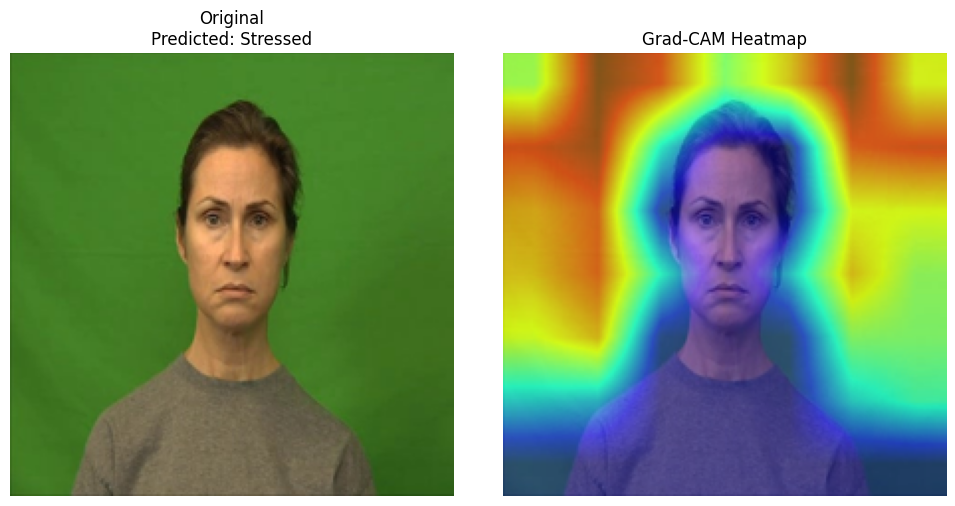

Prediction: Stressed


In [17]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

def visualize_gradcam(image_path, true_label=None):
    img = Image.open(image_path).convert('RGB')
    img_resized = img.resize((224, 224))
    rgb_img = np.array(img_resized) / 255.0

    input_tensor = transform(img).unsqueeze(0).to(device)

    outputs = model(input_tensor)
    pred_class = outputs.argmax(1).item()
    pred_label = 'Stressed' if pred_class == 1 else 'Not_Stressed'

    targets = [ClassifierOutputTarget(pred_class)]
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)
    grayscale_cam = grayscale_cam[0, :]

    visualization = show_cam_on_image(rgb_img.astype(np.float32), grayscale_cam, use_rgb=True)

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(img_resized)
    axes[0].set_title(f"Original\nPredicted: {pred_label}")
    axes[0].axis('off')

    axes[1].imshow(visualization)
    axes[1].set_title("Grad-CAM Heatmap")
    axes[1].axis('off')

    plt.tight_layout()
    plt.savefig('/kaggle/working/gradcam_sample.png')
    plt.show()

    return pred_label

sample_image = '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset/Angry/1025_DFA_ANG_XX_0012.jpg'
result = visualize_gradcam(sample_image)
print("Prediction:", result)

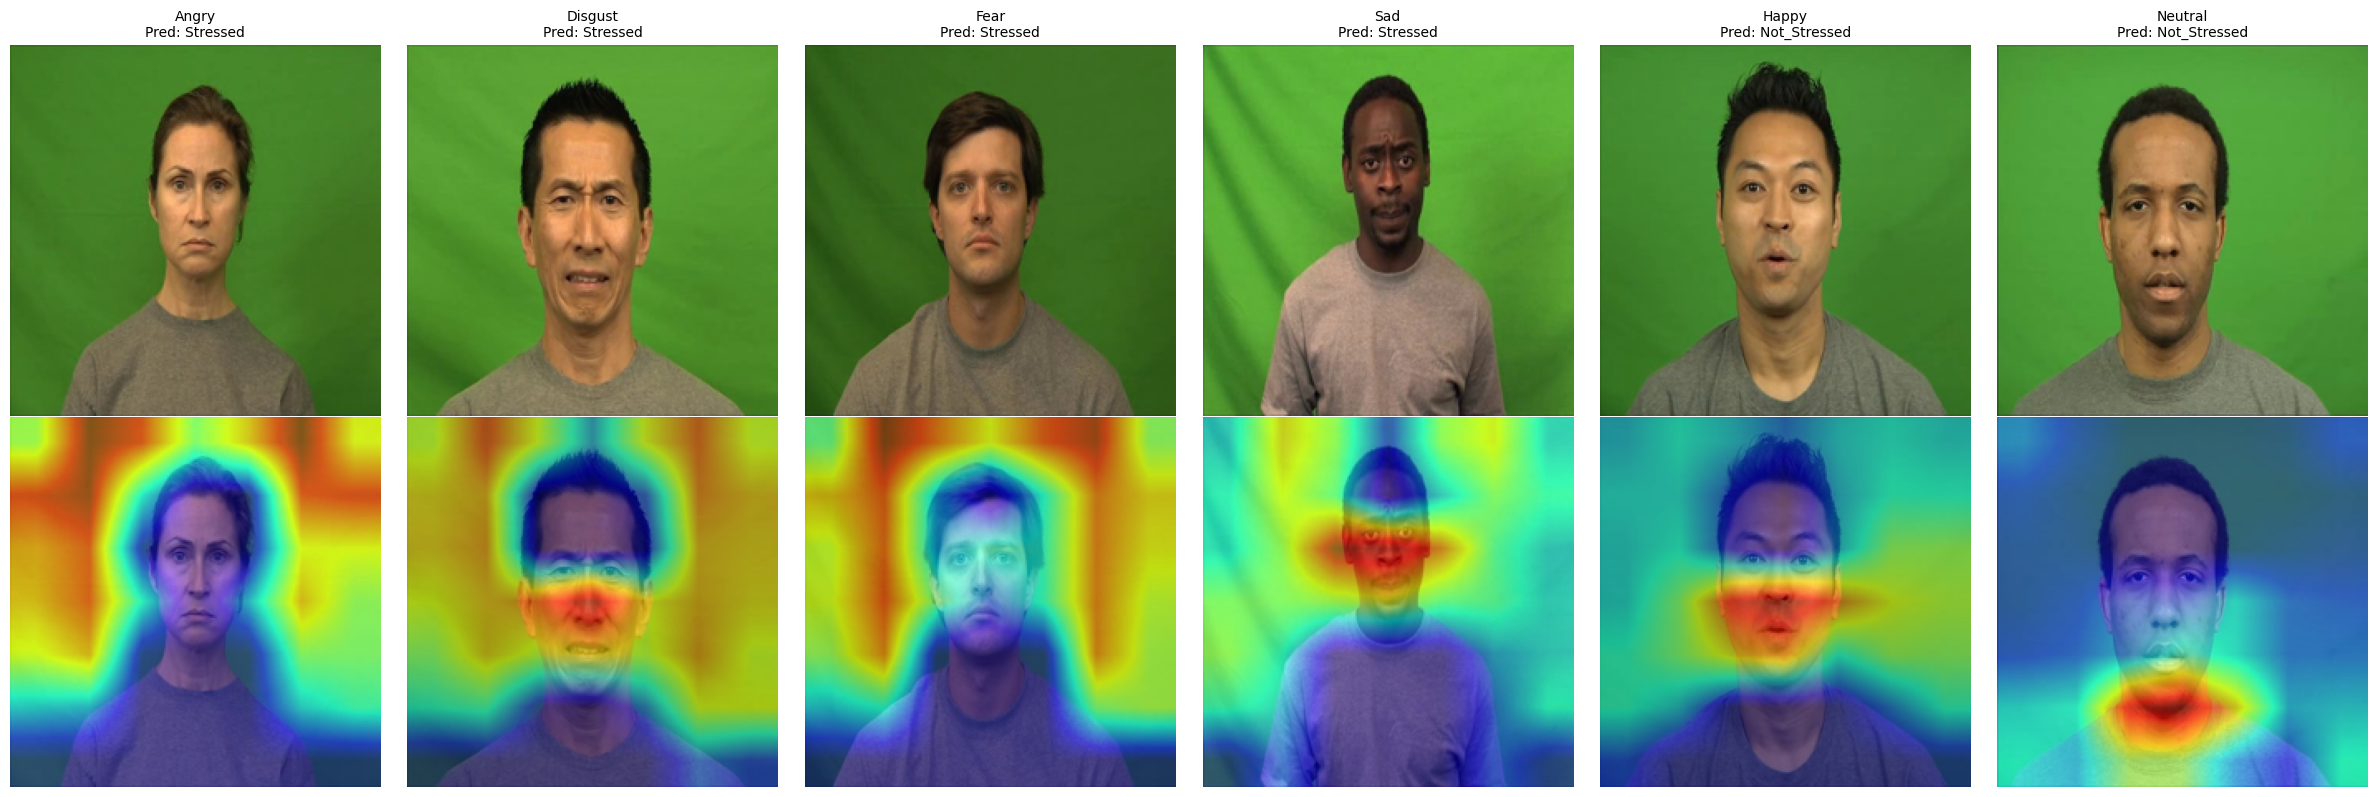

Grid saved!


In [18]:
sample_images = {
    'Angry': '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset/Angry/1025_DFA_ANG_XX_0012.jpg',
    'Disgust': '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset/Disgust/1090_IEO_DIS_MD_0004.jpg',
    'Fear': '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset/Fear/1011_ITH_FEA_XX_0003.jpg',
    'Sad': '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset/Sad/1005_TIE_SAD_XX_0023.jpg',
    'Happy': '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset/Happy/1081_WSI_HAP_XX_0004.jpg',
    'Neutral': '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset/Neutral/1070_DFA_NEU_XX_0000.jpg'
}

fig, axes = plt.subplots(2, 6, figsize=(24, 8))

for idx, (emotion, path) in enumerate(sample_images.items()):
    img = Image.open(path).convert('RGB')
    img_resized = img.resize((224, 224))
    rgb_img = np.array(img_resized) / 255.0
    input_tensor = transform(img).unsqueeze(0).to(device)

    outputs = model(input_tensor)
    pred_class = outputs.argmax(1).item()
    pred_label = 'Stressed' if pred_class == 1 else 'Not_Stressed'

    targets = [ClassifierOutputTarget(pred_class)]
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)
    grayscale_cam = grayscale_cam[0, :]
    visualization = show_cam_on_image(rgb_img.astype(np.float32), grayscale_cam, use_rgb=True)

    axes[0, idx].imshow(img_resized)
    axes[0, idx].set_title(f"{emotion}\nPred: {pred_label}", fontsize=10)
    axes[0, idx].axis('off')

    axes[1, idx].imshow(visualization)
    axes[1, idx].axis('off')

plt.tight_layout()
plt.savefig('/kaggle/working/gradcam_grid_all_emotions.png', dpi=150, bbox_inches='tight')
plt.show()

print("Grid saved!")

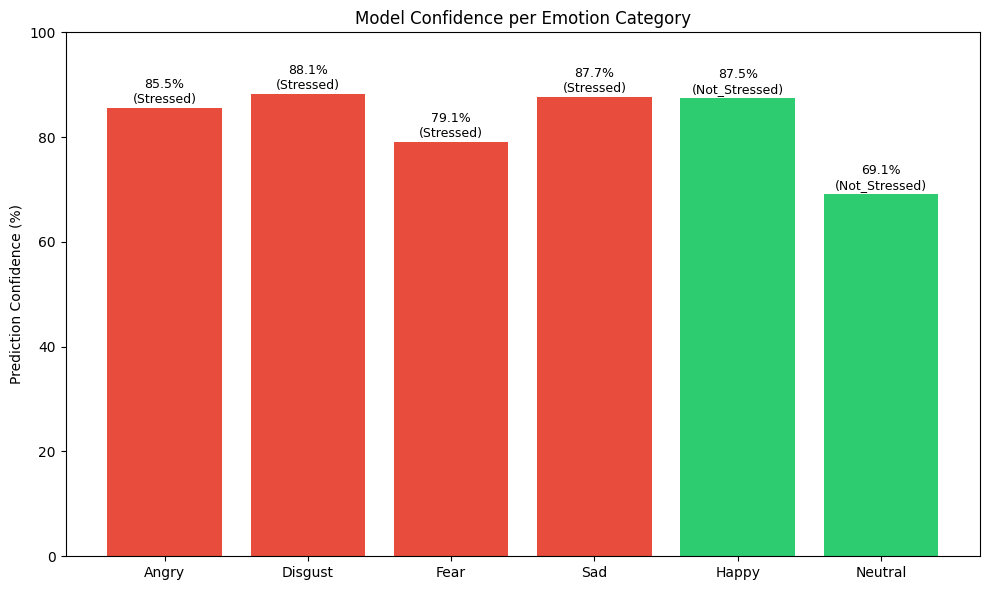

In [20]:
confidence_scores = []
emotion_labels = []
predictions = []

for emotion, path in sample_images.items():
    img = Image.open(path).convert('RGB')
    input_tensor = transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(input_tensor)
        probs = torch.softmax(outputs, dim=1)
        pred_class = outputs.argmax(1).item()
        confidence = probs[0][pred_class].item()

    emotion_labels.append(emotion)
    confidence_scores.append(confidence * 100)
    predictions.append('Stressed' if pred_class == 1 else 'Not_Stressed')

colors = ['#e74c3c' if p == 'Stressed' else '#2ecc71' for p in predictions]

plt.figure(figsize=(10, 6))
bars = plt.bar(emotion_labels, confidence_scores, color=colors)
plt.ylabel('Prediction Confidence (%)')
plt.title('Model Confidence per Emotion Category')
plt.ylim(0, 100)

for bar, conf, pred in zip(bars, confidence_scores, predictions):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
              f'{conf:.1f}%\n({pred})', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('/kaggle/working/confidence_chart.png', dpi=150)
plt.show()

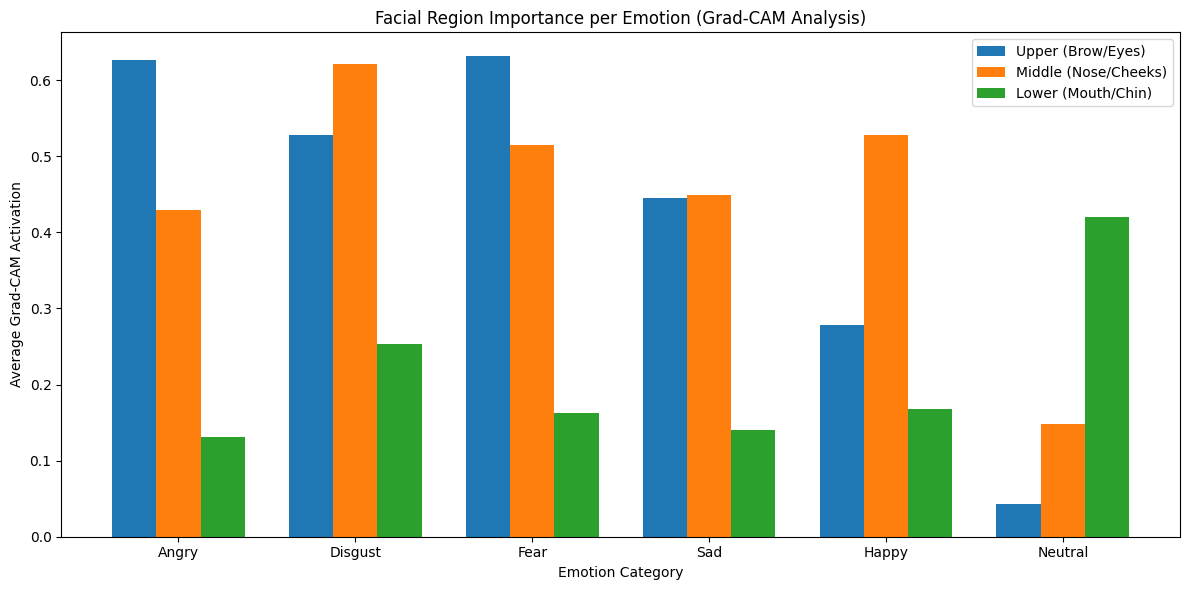

In [21]:
def get_region_intensity(grayscale_cam):
    h, w = grayscale_cam.shape
    upper = grayscale_cam[:h//3, :].mean()
    middle = grayscale_cam[h//3:2*h//3, :].mean()
    lower = grayscale_cam[2*h//3:, :].mean()
    return upper, middle, lower

region_data = {'Upper (Brow/Eyes)': [], 'Middle (Nose/Cheeks)': [], 'Lower (Mouth/Chin)': []}
emotion_names = []

for emotion, path in sample_images.items():
    img = Image.open(path).convert('RGB')
    input_tensor = transform(img).unsqueeze(0).to(device)
    outputs = model(input_tensor)
    pred_class = outputs.argmax(1).item()
    targets = [ClassifierOutputTarget(pred_class)]
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0]

    u, m, l = get_region_intensity(grayscale_cam)
    region_data['Upper (Brow/Eyes)'].append(u)
    region_data['Middle (Nose/Cheeks)'].append(m)
    region_data['Lower (Mouth/Chin)'].append(l)
    emotion_names.append(emotion)

x = np.arange(len(emotion_names))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(x - width, region_data['Upper (Brow/Eyes)'], width, label='Upper (Brow/Eyes)')
ax.bar(x, region_data['Middle (Nose/Cheeks)'], width, label='Middle (Nose/Cheeks)')
ax.bar(x + width, region_data['Lower (Mouth/Chin)'], width, label='Lower (Mouth/Chin)')

ax.set_xlabel('Emotion Category')
ax.set_ylabel('Average Grad-CAM Activation')
ax.set_title('Facial Region Importance per Emotion (Grad-CAM Analysis)')
ax.set_xticks(x)
ax.set_xticklabels(emotion_names)
ax.legend()

plt.tight_layout()
plt.savefig('/kaggle/working/region_importance_chart.png', dpi=150)
plt.show()

In [22]:
import random

def analyze_multiple_samples(emotion_folder_path, n_samples=25):
    all_files = [f for f in os.listdir(emotion_folder_path) if f.endswith('.jpg')]
    sampled_files = random.sample(all_files, min(n_samples, len(all_files)))

    confidences = []
    predictions = []
    upper_scores, middle_scores, lower_scores = [], [], []

    for fname in sampled_files:
        path = os.path.join(emotion_folder_path, fname)
        img = Image.open(path).convert('RGB')
        input_tensor = transform(img).unsqueeze(0).to(device)

        with torch.no_grad():
            outputs = model(input_tensor)
            probs = torch.softmax(outputs, dim=1)
            pred_class = outputs.argmax(1).item()
            confidence = probs[0][pred_class].item()

        confidences.append(confidence * 100)
        predictions.append(pred_class)

        targets = [ClassifierOutputTarget(pred_class)]
        grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0]
        h, w = grayscale_cam.shape
        upper_scores.append(grayscale_cam[:h//3, :].mean())
        middle_scores.append(grayscale_cam[h//3:2*h//3, :].mean())
        lower_scores.append(grayscale_cam[2*h//3:, :].mean())

    return {
        'avg_confidence': np.mean(confidences),
        'std_confidence': np.std(confidences),
        'stressed_ratio': predictions.count(1) / len(predictions),
        'avg_upper': np.mean(upper_scores),
        'avg_middle': np.mean(middle_scores),
        'avg_lower': np.mean(lower_scores)
    }

emotion_folders = {
    'Angry': '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset/Angry',
    'Disgust': '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset/Disgust',
    'Fear': '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset/Fear',
    'Sad': '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset/Sad',
    'Happy': '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset/Happy',
    'Neutral': '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset/Neutral'
}

results = {}
for emotion, folder in emotion_folders.items():
    print(f"Analyzing {emotion}...")
    results[emotion] = analyze_multiple_samples(folder, n_samples=25)

for emotion, r in results.items():
    print(f"\n{emotion}: Avg Confidence = {r['avg_confidence']:.1f}% (±{r['std_confidence']:.1f}), Stressed Ratio = {r['stressed_ratio']:.2f}")

Analyzing Angry...
Analyzing Disgust...
Analyzing Fear...
Analyzing Sad...
Analyzing Happy...
Analyzing Neutral...

Angry: Avg Confidence = 82.8% (±10.8), Stressed Ratio = 0.92

Disgust: Avg Confidence = 88.5% (±4.1), Stressed Ratio = 0.96

Fear: Avg Confidence = 84.3% (±9.1), Stressed Ratio = 0.88

Sad: Avg Confidence = 83.6% (±9.0), Stressed Ratio = 1.00

Happy: Avg Confidence = 95.3% (±5.1), Stressed Ratio = 0.08

Neutral: Avg Confidence = 87.3% (±12.4), Stressed Ratio = 0.20


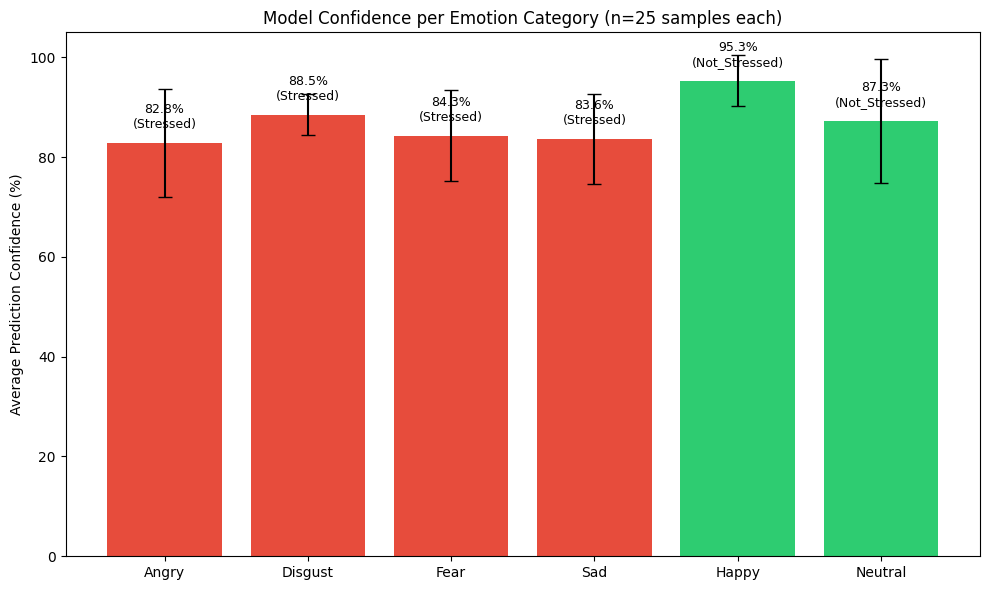

In [24]:
emotions = list(results.keys())
avg_conf = [results[e]['avg_confidence'] for e in emotions]
std_conf = [results[e]['std_confidence'] for e in emotions]
stressed_ratios = [results[e]['stressed_ratio'] for e in emotions]

colors = ['#e74c3c' if r > 0.5 else '#2ecc71' for r in stressed_ratios]

plt.figure(figsize=(10, 6))
bars = plt.bar(emotions, avg_conf, yerr=std_conf, capsize=5, color=colors)
plt.ylabel('Average Prediction Confidence (%)')
plt.title('Model Confidence per Emotion Category (n=25 samples each)')
plt.ylim(0, 105)

for bar, conf, ratio in zip(bars, avg_conf, stressed_ratios):
    label = 'Stressed' if ratio > 0.5 else 'Not_Stressed'
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 3,
              f'{conf:.1f}%\n({label})', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('/kaggle/working/confidence_chart_corrected.png', dpi=150)
plt.show()

# ============================
# SECTION 3: Speech Modal in One Cell ( start)

# ============================

In [28]:
# =====================================================================
# CREMA-D proxy-stress recognition: partial fine-tuning of wav2vec 2.0 Base
# One cell: data -> actor-disjoint split -> train -> test metrics -> figures
# Matches the paper: AdamW 1e-5, bs 8, 8 epochs, FP32, balanced CE weights,
# trainable = Transformer layers 11-12 + projector + classifier.
# =====================================================================
import os, glob, re, time, json
import numpy as np, pandas as pd, librosa, torch, torch.nn as nn
import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
import torchaudio, transformers, sklearn
from joblib import Parallel, delayed
from tqdm.auto import tqdm
from torch.utils.data import TensorDataset, DataLoader
from transformers import Wav2Vec2ForSequenceClassification
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                             roc_curve, accuracy_score, balanced_accuracy_score,
                             f1_score, matthews_corrcoef)

# ------------------------------ config --------------------------------
SEED = 42                 # NumPy seed: actor split only (as in the paper)
FIX_TORCH_SEED = False    # paper: PyTorch seeds were NOT fixed. True = repeatable runs.
SR, SEC = 16000, 4
N = SR * SEC              # 64,000 samples
LR, BS, EPOCHS = 1e-5, 8, 8
RUN_SVM_BASELINE = True   # MFCC + SVM on the same split (fills Table 7)
OUT = "/kaggle/working"
STRESSED = {"ANG": "Angry", "DIS": "Disgust", "FEA": "Fear", "SAD": "Sad"}
NOT_STRESSED = {"HAP": "Happy", "NEU": "Neutral"}
CODE2EMO = {**STRESSED, **NOT_STRESSED}
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if FIX_TORCH_SEED:
    torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

# ------------------------- environment report -------------------------
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only")
print("torch", torch.__version__, "| torchaudio", torchaudio.__version__, "| transformers",
      transformers.__version__, "| librosa", librosa.__version__, "| scikit-learn", sklearn.__version__)

# ------------------------------ data ----------------------------------
pat = re.compile(r"^(\d{4})_[A-Z]{3}_(ANG|DIS|FEA|HAP|NEU|SAD)_")
paths = sorted(p for p in glob.glob("/kaggle/input/**/*.wav", recursive=True)
               if pat.match(os.path.basename(p)))
print("CREMA-D clips found:", len(paths), "(expected 7442)")
rows = []
for p in paths:
    m = pat.match(os.path.basename(p))
    rows.append(dict(path=p, actor=int(m.group(1)), emotion=CODE2EMO[m.group(2)],
                     label=int(m.group(2) in STRESSED)))
df = pd.DataFrame(rows)
print("Stressed:", int(df.label.sum()), "| Not_Stressed:", int((df.label == 0).sum()),
      "| actors:", df.actor.nunique())

# --------------------- actor-disjoint 70/15/15 split ------------------
rng = np.random.RandomState(SEED)
actors = np.array(sorted(df.actor.unique())); rng.shuffle(actors)
n_tr, n_va = int(0.70 * len(actors)), int(0.15 * len(actors))          # 63, 13
split_actors = {"train": actors[:n_tr],
                "val":   actors[n_tr:n_tr + n_va],
                "test":  actors[n_tr + n_va:]}
parts = {k: df[df.actor.isin(v)].reset_index(drop=True) for k, v in split_actors.items()}
print("\n=== TABLE 3: split ===")
for k, d in parts.items():
    print(f"{k:5s} actors={d.actor.nunique():3d} clips={len(d):5d} "
          f"Stressed={int(d.label.sum()):5d} Not_Stressed={int((d.label == 0).sum()):5d}")
assert not (set(split_actors["train"]) & set(split_actors["test"]))
assert not (set(split_actors["val"]) & set(split_actors["test"]))
assert not (set(split_actors["train"]) & set(split_actors["val"]))
pd.concat([d.assign(split=k) for k, d in parts.items()]).to_csv(f"{OUT}/split_assignments.csv", index=False)

# ------------- preprocessing: mono, 16 kHz, 4 s, zero-pad/truncate ----
def load_clip(p):
    y, _ = librosa.load(p, sr=SR, mono=True)
    return np.pad(y, (0, max(0, N - len(y))))[:N].astype(np.float32)   # no normalisation

def load_all(d):
    return np.stack(Parallel(n_jobs=-1)(delayed(load_clip)(p) for p in tqdm(d.path, leave=False)))

X, Y = {}, {}
for k, d in parts.items():
    X[k] = load_all(d); Y[k] = d.label.values.astype(np.int64)
    print(k, X[k].shape)

# ------------------------------ model ---------------------------------
model = Wav2Vec2ForSequenceClassification.from_pretrained("facebook/wav2vec2-base", num_labels=2).to(device)
for n_, p_ in model.named_parameters():
    p_.requires_grad = (".encoder.layers.10." in n_) or (".encoder.layers.11." in n_) \
                       or n_.startswith("projector") or n_.startswith("classifier")
tot = sum(p.numel() for p in model.parameters())
trn = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("\n=== PARAMETERS ===")
print(f"total {tot:,} | trainable {trn:,} ({100*trn/tot:.2f}%) | frozen {tot-trn:,}")
print("expected total 94,569,090; trainable about 14.37 M")

# ------------------------- loss, optimiser ----------------------------
cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=Y["train"])
print("class weights (Not_Stressed, Stressed):", np.round(cw, 4))
criterion = nn.CrossEntropyLoss(weight=torch.tensor(cw, dtype=torch.float32).to(device))
optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=LR)  # default weight decay, no scheduler

tr_loader = DataLoader(TensorDataset(torch.from_numpy(X["train"]), torch.from_numpy(Y["train"])),
                       batch_size=BS, shuffle=True)

@torch.no_grad()
def evaluate(Xa, Ya, bs=16):
    model.eval(); probs, tot_loss = [], 0.0
    for xb, yb in DataLoader(TensorDataset(torch.from_numpy(Xa), torch.from_numpy(Ya)), batch_size=bs):
        out = model(input_values=xb.to(device)).logits            # no attention mask
        tot_loss += criterion(out, yb.to(device)).item() * len(yb)
        probs.append(torch.softmax(out, 1)[:, 1].cpu())
    probs = torch.cat(probs).numpy(); preds = (probs >= 0.5).astype(int)
    return tot_loss / len(Ya), (preds == Ya).mean(), probs, preds

# ------------------------------ training ------------------------------
hist = dict(train_loss=[], train_acc=[], val_loss=[], val_acc=[]); best_val = -1; best_ep = -1
t0 = time.time()
for ep in range(EPOCHS):
    model.train(); run_loss = correct = seen = 0
    for xb, yb in tqdm(tr_loader, desc=f"epoch {ep+1}/{EPOCHS}", leave=False):
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        out = model(input_values=xb).logits                        # FP32
        loss = criterion(out, yb); loss.backward(); optimizer.step()
        run_loss += loss.item() * len(yb); correct += (out.argmax(1) == yb).sum().item(); seen += len(yb)
    vl, va, _, _ = evaluate(X["val"], Y["val"])
    hist["train_loss"].append(run_loss / seen); hist["train_acc"].append(correct / seen)
    hist["val_loss"].append(vl); hist["val_acc"].append(float(va))
    print(f"epoch {ep+1}: train loss {run_loss/seen:.4f} acc {correct/seen:.4f} | val loss {vl:.4f} acc {va:.4f}")
    if va > best_val:
        best_val, best_ep = va, ep + 1
        torch.save(model.state_dict(), f"{OUT}/best_speech_finetuned.pth")
train_minutes = (time.time() - t0) / 60
print(f"\nbest val acc {best_val:.4f} at epoch {best_ep} | training time {train_minutes:.1f} min")
json.dump(hist, open(f"{OUT}/training_history.json", "w"))

# --------------------------- test evaluation --------------------------
model.load_state_dict(torch.load(f"{OUT}/best_speech_finetuned.pth", map_location=device))
_, test_acc, probs, preds = evaluate(X["test"], Y["test"])
y = Y["test"]; names = ["Not_Stressed", "Stressed"]
print("\n=== TEST RESULTS (paste into paper) ===")
rep = classification_report(y, preds, target_names=names, digits=2); print(rep)
cm = confusion_matrix(y, preds); print("confusion matrix [[TN, FP],[FN, TP]]:\n", cm)
fpr, tpr, _ = roc_curve(y, probs); fnr = 1 - tpr; k = np.nanargmin(np.abs(fpr - fnr))
auc, eer = roc_auc_score(y, probs), (fpr[k] + fnr[k]) / 2
print(f"accuracy {accuracy_score(y,preds):.4f} | balanced acc {balanced_accuracy_score(y,preds):.4f} | "
      f"macro-F1 {f1_score(y,preds,average='macro'):.4f} | MCC {matthews_corrcoef(y,preds):.4f}")
print(f"AUC {auc:.4f} | EER {eer:.4f}")
open(f"{OUT}/speech_classification_report.txt", "w").write(
    "Speech Stress Detection Model - Test Results (Fine-tuned Wav2Vec2)\n" + "=" * 60 + "\n\n" + rep)

# bootstrap 95% CI over test clips (percentile, 10,000 resamples)
def boot(y, p, B=10000, seed=SEED):
    g = np.random.default_rng(seed); idx = g.integers(0, len(y), (B, len(y))); yy, pp = y[idx], p[idx]
    tp = ((yy == 1) & (pp == 1)).sum(1).astype(float); tn = ((yy == 0) & (pp == 0)).sum(1).astype(float)
    fp = ((yy == 0) & (pp == 1)).sum(1).astype(float); fn = ((yy == 1) & (pp == 0)).sum(1).astype(float)
    rs, rn = tp / (tp + fn), tn / (tn + fp); ps, pn = tp / (tp + fp), tn / (tn + fn)
    f_s, f_n = 2 * ps * rs / (ps + rs), 2 * pn * rn / (pn + rn)
    mcc = (tp * tn - fp * fn) / np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    return {"accuracy": (tp + tn) / len(y), "balanced_acc": (rs + rn) / 2, "macro_F1": (f_s + f_n) / 2,
            "MCC": mcc, "recall_Stressed": rs, "recall_Not_Stressed": rn}
print("\n95% bootstrap CI:")
for m_, v in boot(y, preds).items():
    print(f"  {m_:20s} {np.nanpercentile(v, 2.5):.3f} - {np.nanpercentile(v, 97.5):.3f}")

# per-emotion accuracy (Table 9 / Fig. 4)
te = parts["test"].copy(); te["pred"] = preds; te["ok"] = (te.pred == te.label)
tab = te.groupby("emotion").agg(proxy=("label", lambda s: "Stressed" if s.iloc[0] == 1 else "Not_Stressed"),
                                test_clips=("ok", "size"), accuracy=("ok", "mean")).reindex(
      ["Angry", "Disgust", "Fear", "Sad", "Happy", "Neutral"]).round(3)
print("\n=== TABLE 9: per-emotion accuracy ===\n", tab)
print("check: Stressed recall", round(te[te.label == 1].ok.mean(), 4),
      "| Not_Stressed recall", round(te[te.label == 0].ok.mean(), 4))

# efficiency (Table 10)
model.eval(); xs = torch.from_numpy(X["test"][:110])
with torch.no_grad():
    for i in range(10): model(input_values=xs[i:i+1].to(device))
    if device.type == "cuda": torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    t1 = time.time()
    for i in range(10, 110): model(input_values=xs[i:i+1].to(device))
    if device.type == "cuda": torch.cuda.synchronize()
ms = (time.time() - t1) / 100 * 1000
mem = torch.cuda.max_memory_allocated() / 2**20 if device.type == "cuda" else float("nan")
print(f"\n=== TABLE 10 ===\ninference {ms:.1f} ms/clip (batch 1, 4 s clip) | peak GPU memory {mem:.0f} MB | training {train_minutes:.1f} min")

# ------------------------------ figures (300 dpi) ---------------------
fig, ax = plt.subplots(figsize=(4.2, 3.6)); im = ax.imshow(cm, cmap="Blues"); plt.colorbar(im, fraction=0.046)
ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.set_xticklabels(names); ax.set_yticklabels(names)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max()/2 else "black")
plt.tight_layout(); plt.savefig(f"{OUT}/fig3_confusion_matrix.png", dpi=300); plt.close()

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2)); ep_ = range(1, EPOCHS + 1)
ax[0].plot(ep_, hist["train_loss"], label="Train loss"); ax[0].plot(ep_, hist["val_loss"], label="Val loss")
ax[1].plot(ep_, hist["train_acc"], label="Train acc"); ax[1].plot(ep_, hist["val_acc"], label="Val acc")
for a, t in zip(ax, ["Loss", "Accuracy"]): a.set_xlabel("Epoch"); a.set_title(t); a.legend()
plt.tight_layout(); plt.savefig(f"{OUT}/fig5_training_curves.png", dpi=300); plt.close()

fig, ax = plt.subplots(figsize=(5.5, 3.2))
b = ax.bar(tab.index, tab.accuracy, color=["#f9cb9c" if p == "Stressed" else "#cfe2f3" for p in tab.proxy], edgecolor="#333")
ax.set_ylim(0, 1); ax.set_ylabel("Accuracy (prescribed proxy class)")
for r_, a_ in zip(b, tab.accuracy): ax.text(r_.get_x() + r_.get_width()/2, a_ + 0.02, f"{a_:.2f}", ha="center", fontsize=9)
plt.tight_layout(); plt.savefig(f"{OUT}/fig4_per_emotion.png", dpi=300); plt.close()

# ----------------- optional baseline: MFCC + SVM, same split ----------
if RUN_SVM_BASELINE:
    from sklearn.svm import SVC
    from sklearn.preprocessing import StandardScaler
    from sklearn.pipeline import make_pipeline
    def mfcc_vec(w):
        m = librosa.feature.mfcc(y=w, sr=SR, n_mfcc=40); return np.r_[m.mean(1), m.std(1)]
    F = {k: np.stack(Parallel(n_jobs=-1)(delayed(mfcc_vec)(w) for w in X[k])) for k in X}
    best = (-1, None)
    for C in [0.1, 1, 10, 100]:
        c = make_pipeline(StandardScaler(), SVC(C=C, class_weight="balanced")).fit(F["train"], Y["train"])
        ba = balanced_accuracy_score(Y["val"], c.predict(F["val"])); print("SVM C", C, "val BA", round(ba, 4))
        if ba > best[0]: best = (ba, C)
    c = make_pipeline(StandardScaler(), SVC(C=best[1], class_weight="balanced")).fit(F["train"], Y["train"])
    sp = c.predict(F["test"]); print("\n=== TABLE 7: MFCC+SVM (C =", best[1], ") ===")
    print(f"accuracy {accuracy_score(y,sp):.4f} | balanced acc {balanced_accuracy_score(y,sp):.4f} | macro-F1 {f1_score(y,sp,average='macro'):.4f}")
    print(classification_report(y, sp, target_names=names, digits=2)); print(confusion_matrix(y, sp))
print("\nDone. Files in", OUT)

GPU: Tesla T4
torch 2.10.0+cu128 | torchaudio 2.10.0+cu128 | transformers 5.0.0 | librosa 0.11.0 | scikit-learn 1.6.1
CREMA-D clips found: 7442 (expected 7442)
Stressed: 5084 | Not_Stressed: 2358 | actors: 91

=== TABLE 3: split ===
train actors= 63 clips= 5147 Stressed= 3516 Not_Stressed= 1631
val   actors= 13 clips= 1066 Stressed=  728 Not_Stressed=  338
test  actors= 15 clips= 1229 Stressed=  840 Not_Stressed=  389


  0%|          | 0/5147 [00:00<?, ?it/s]

train (5147, 64000)


  0%|          | 0/1066 [00:00<?, ?it/s]

val (1066, 64000)


...

epoch 6: train loss 0.4143 acc 0.8110 | val loss 0.6001 acc 0.7280


epoch 7/8:   0%|          | 0/644 [00:00<?, ?it/s]

epoch 7: train loss 0.3937 acc 0.8156 | val loss 0.8036 acc 0.7355


epoch 8/8:   0%|          | 0/644 [00:00<?, ?it/s]

epoch 8: train loss 0.3892 acc 0.8203 | val loss 0.8538 acc 0.7420

best val acc 0.7420 at epoch 8 | training time 45.2 min

=== TEST RESULTS (paste into paper) ===
              precision    recall  f1-score   support

Not_Stressed       0.77      0.53      0.63       389
    Stressed       0.81      0.93      0.86       840

    accuracy                           0.80      1229
   macro avg       0.79      0.73      0.75      1229
weighted avg       0.80      0.80      0.79      1229

confusion matrix [[TN, FP],[FN, TP]]:
 [[206 183]
 [ 61 779]]
accuracy 0.8015 | balanced acc 0.7285 | macro-F1 0.7463 | MCC 0.5154
AUC 0.8792 | EER 0.2058

95% bootstrap CI:
  accuracy             0.779 - 0.823
  balanced_acc         0.702 - 0.754
  macro_F1             0.718 - 0.773
  MCC                  0.463 - 0.567
  recall_Stressed      0.909 - 0.945
  recall_Not_Stressed  0.480 - 0.579

=== TABLE 9: per-emotion accuracy ===
                 proxy  test_clips  accuracy
emotion                     

# ============================
# SECTION 3: EXPLAINABLE AI (GRAD-CAM) (Facial data ) End
# ============================

# ============================
# SECTION 5: FACE + SPEECH MULTIMODAL (START)
# ============================

In [5]:
import os, re, json, pandas as pd

FACE_ROOT = '/kaggle/input/datasets/jigardave26121992/crema-d-dataset/dataset'  # emotion subfolders
AUDIO_ROOT = '/kaggle/input/datasets/jigardave26121992/audio-data/AudioWAV'
PARTITION_PATH = '/kaggle/input/models/jigardave26121992/actor-json/tensorflow2/default/1/actor_partition.json'  # <-- set to where you uploaded it

EMOTION2IDX = {'Angry':1,'Disgust':1,'Fear':1,'Sad':1,'Happy':0,'Neutral':0}  # stress label
STEM_RE = re.compile(r'^(\d+)_([A-Z]+)_([A-Z]+)_([A-Z0-9]+)_\d+\.jpg$')  # actor_sent_emo_int_frame.jpg

# group face frames by clip stem
clips = {}  # stem -> list of frame paths
for emo in os.listdir(FACE_ROOT):
    for f in os.listdir(os.path.join(FACE_ROOT, emo)):
        m = STEM_RE.match(f)
        if not m: continue
        actor, sent, emo_code, inten = m.groups()
        stem = f"{actor}_{sent}_{emo_code}_{inten}"
        clips.setdefault(stem, []).append(os.path.join(FACE_ROOT, emo, f))

rows = []
for stem, frames in clips.items():
    actor, sent, emo_code, inten = stem.split('_')
    wav = os.path.join(AUDIO_ROOT, f"{stem}.wav")
    emo_name = [k for k,v in EMOTION2IDX.items() if v == (1 if emo_code in {'ANG','DIS','FEA','SAD'} else 0)][0]
    label = 1 if emo_code in {'ANG','DIS','FEA','SAD'} else 0
    if not os.path.exists(wav): continue  # skip clips missing audio
    rows.append(dict(stem=stem, actor=actor, label=label,
                      face_frames=frames, audio_path=wav))
df = pd.DataFrame(rows)

with open(PARTITION_PATH) as f:
    part = json.load(f)
actor2split = {a:'train' for a in part['train_actors']}
actor2split.update({a:'val' for a in part['val_actors']})
actor2split.update({a:'test' for a in part['test_actors']})
df['split'] = df['actor'].map(actor2split)
df = df.dropna(subset=['split'])

# overlap check
for s1 in ['train','val','test']:
    for s2 in ['train','val','test']:
        if s1<s2:
            assert set(df[df.split==s1].actor) & set(df[df.split==s2].actor) == set(), f"{s1}/{s2} overlap!"
print(df.split.value_counts(), "\nclips:", len(df), "| actors:", df.actor.nunique())
df.to_pickle('/kaggle/working/clip_table.pkl')

split
train    5147
val      1148
test     1147
Name: count, dtype: int64 
clips: 7442 | actors: 91


In [6]:
import numpy as np, json, os

ACTORS = sorted(set(
    f.split('_')[0] for emo in os.listdir(FACE_ROOT)
    for f in os.listdir(os.path.join(FACE_ROOT, emo))
))  # all actor IDs present in the dataset

rng = np.random.RandomState(42)
perm = rng.permutation(ACTORS)
n = len(perm)
n_train = int(round(0.70 * n))
n_val = int(round(0.15 * n))

partition = {
    'train_actors': perm[:n_train].tolist(),
    'val_actors':   perm[n_train:n_train+n_val].tolist(),
    'test_actors':  perm[n_train+n_val:].tolist(),
}
PARTITION_PATH = '/kaggle/working/actor_partition.json'
with open(PARTITION_PATH, 'w') as f:
    json.dump(partition, f)

print({k: len(v) for k, v in partition.items()})

{'train_actors': 64, 'val_actors': 14, 'test_actors': 13}


In [9]:
# This file is the 6-class EMOTION model — load it as the raw timm model
face_backbone = timm.create_model('efficientnet_b0', pretrained=False, num_classes=6).to(DEVICE)
face_backbone.load_state_dict(torch.load(FACE_CKPT, map_location=DEVICE), strict=True)
face_backbone.eval()

def face_features(x):
    feat = face_backbone.forward_features(x)
    feat = face_backbone.global_pool(feat)  # 1280-d pooled embedding
    return feat

NameError: name 'FACE_CKPT' is not defined

In [10]:
import torch, torch.nn as nn, timm
from transformers import Wav2Vec2Model

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# ---- Face: emotion backbone (6-class), used as feature extractor ----
face_backbone = timm.create_model('efficientnet_b0', pretrained=False, num_classes=6).to(DEVICE)
face_backbone.load_state_dict(torch.load(FACE_CKPT, map_location=DEVICE), strict=True)
face_backbone.eval()

def face_features(x):
    feat = face_backbone.forward_features(x)
    feat = face_backbone.global_pool(feat)  # 1280-d pooled embedding
    return feat

# ---- Speech model: Wav2Vec2-base ----
class SpeechStressModel(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.wav2vec = Wav2Vec2Model.from_pretrained('facebook/wav2vec2-base')
        self.projector = nn.Linear(768, 256)
        self.classifier = nn.Linear(256, num_classes)
    def forward(self, x, return_features=False):
        h = self.wav2vec(x).last_hidden_state.mean(dim=1)
        feat = self.projector(h)
        out = self.classifier(feat)
        return (out, feat) if return_features else out

SPEECH_CKPT = '/kaggle/input/models/jigardave26121992/best-speech-modal/tensorflow2/default/1/best_speech_finetuned.pth'  # set your actual path
speech_model = SpeechStressModel().to(DEVICE)
speech_model.load_state_dict(torch.load(SPEECH_CKPT, map_location=DEVICE), strict=True)
speech_model.eval()

print("Face backbone + speech model loaded.")

NameError: name 'FACE_CKPT' is not defined

In [11]:
class SpeechStressModel(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.wav2vec2 = Wav2Vec2Model.from_pretrained('facebook/wav2vec2-base')  # renamed to match checkpoint
        self.projector = nn.Linear(768, 256)
        self.classifier = nn.Linear(256, num_classes)
    def forward(self, x, return_features=False):
        h = self.wav2vec2(x).last_hidden_state.mean(dim=1)
        feat = self.projector(h)
        out = self.classifier(feat)
        return (out, feat) if return_features else out

speech_model = SpeechStressModel().to(DEVICE)
speech_model.load_state_dict(torch.load(SPEECH_CKPT, map_location=DEVICE), strict=True)
speech_model.eval()
print("Speech model loaded.")

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/380M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/380M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
project_hid.bias             | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


NameError: name 'SPEECH_CKPT' is not defined

In [16]:
import numpy as np, torch, torchaudio
from PIL import Image
from torchvision import transforms
from tqdm import tqdm

df = pd.read_pickle('/kaggle/working/clip_table.pkl')

face_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

@torch.no_grad()
def get_face_feat(frame_paths):
    imgs = torch.stack([face_tf(Image.open(p).convert('RGB')) for p in frame_paths]).to(DEVICE)
    feat = face_backbone.forward_features(imgs)
    feat = face_backbone.global_pool(feat)          # [n_frames, 1280]
    return feat.mean(dim=0).cpu().numpy()            # clip-level pooled

@torch.no_grad()
def get_speech_feat(wav_path):
    wav, sr = torchaudio.load(wav_path)
    if sr != 16000:
        wav = torchaudio.functional.resample(wav, sr, 16000)
    wav = wav.mean(dim=0, keepdim=True).to(DEVICE)   # mono
    _, feat = speech_model(wav, return_features=True)
    return feat.squeeze(0).cpu().numpy()              # [256]

face_feats, speech_feats, labels, stems, splits = [], [], [], [], []
for _, row in tqdm(df.iterrows(), total=len(df)):
    face_feats.append(get_face_feat(row['face_frames']))
    speech_feats.append(get_speech_feat(row['audio_path']))
    labels.append(row['label']); stems.append(row['stem']); splits.append(row['split'])

np.save('/kaggle/working/face_feats.npy', np.stack(face_feats))
np.save('/kaggle/working/speech_feats.npy', np.stack(speech_feats))
np.save('/kaggle/working/labels.npy', np.array(labels))
pd.DataFrame({'stem': stems, 'split': splits}).to_pickle('/kaggle/working/meta.pkl')
print("Cached:", np.stack(face_feats).shape, np.stack(speech_feats).shape)

100%|██████████| 7442/7442 [34:13<00:00,  3.62it/s]  


Cached: (7442, 1280) (7442, 256)


In [17]:
import torch.nn.functional as F
from sklearn.utils.class_weight import compute_class_weight
from torch.utils.data import Dataset, DataLoader

face_feats = np.load('/kaggle/working/face_feats.npy')
speech_feats = np.load('/kaggle/working/speech_feats.npy')
labels = np.load('/kaggle/working/labels.npy')
meta = pd.read_pickle('/kaggle/working/meta.pkl')

class ClipDataset(Dataset):
    def __init__(self, idx):
        self.f = face_feats[idx]; self.s = speech_feats[idx]; self.y = labels[idx]
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        return torch.tensor(self.f[i], dtype=torch.float32), \
               torch.tensor(self.s[i], dtype=torch.float32), \
               torch.tensor(self.y[i], dtype=torch.long)

train_idx = np.where(meta.split == 'train')[0]
val_idx   = np.where(meta.split == 'val')[0]
test_idx  = np.where(meta.split == 'test')[0]

train_loader = DataLoader(ClipDataset(train_idx), batch_size=32, shuffle=True)
val_loader   = DataLoader(ClipDataset(val_idx), batch_size=64)
test_loader  = DataLoader(ClipDataset(test_idx), batch_size=64)

class_weights = compute_class_weight('balanced', classes=np.array([0,1]), y=labels[train_idx])
class_weights = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)

class ConcatFusionMLP(nn.Module):
    def __init__(self, face_dim=1280, speech_dim=256, hidden=256, num_classes=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(face_dim + speech_dim, hidden), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(hidden, hidden // 2), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(hidden // 2, num_classes))
    def forward(self, f, s):
        return self.net(torch.cat([f, s], dim=1))

fusion_model = ConcatFusionMLP().to(DEVICE)
optimizer = torch.optim.Adam(fusion_model.parameters(), lr=1e-3, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss(weight=class_weights)

print("Fusion model + loaders ready. Train:", len(train_idx), "Val:", len(val_idx), "Test:", len(test_idx))

Fusion model + loaders ready. Train: 5147 Val: 1148 Test: 1147


In [18]:
from sklearn.metrics import f1_score, accuracy_score

def evaluate(loader):
    fusion_model.eval()
    preds, ys = [], []
    with torch.no_grad():
        for f, s, y in loader:
            f, s = f.to(DEVICE), s.to(DEVICE)
            out = fusion_model(f, s)
            preds.extend(out.argmax(1).cpu().numpy())
            ys.extend(y.numpy())
    return accuracy_score(ys, preds), f1_score(ys, preds, average='macro')

best_val_f1 = 0
EPOCHS = 30
for epoch in range(EPOCHS):
    fusion_model.train()
    total_loss = 0
    for f, s, y in train_loader:
        f, s, y = f.to(DEVICE), s.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        out = fusion_model(f, s)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * y.size(0)

    val_acc, val_f1 = evaluate(val_loader)
    print(f"Epoch {epoch+1}/{EPOCHS} | loss {total_loss/len(train_idx):.4f} | val_acc {val_acc:.4f} | val_macroF1 {val_f1:.4f}")

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        torch.save(fusion_model.state_dict(), '/kaggle/working/best_fusion_concat_mlp.pth')

print("Best val macro-F1:", best_val_f1)

Epoch 1/30 | loss 0.2225 | val_acc 0.8441 | val_macroF1 0.8212
Epoch 2/30 | loss 0.0864 | val_acc 0.8528 | val_macroF1 0.8182
Epoch 3/30 | loss 0.0698 | val_acc 0.8528 | val_macroF1 0.8233
Epoch 4/30 | loss 0.0546 | val_acc 0.8659 | val_macroF1 0.8351
Epoch 5/30 | loss 0.0560 | val_acc 0.8389 | val_macroF1 0.7849
Epoch 6/30 | loss 0.0492 | val_acc 0.8510 | val_macroF1 0.8184
Epoch 7/30 | loss 0.0459 | val_acc 0.8493 | val_macroF1 0.8203
Epoch 8/30 | loss 0.0483 | val_acc 0.8606 | val_macroF1 0.8264
Epoch 9/30 | loss 0.0356 | val_acc 0.8493 | val_macroF1 0.8261
Epoch 10/30 | loss 0.0399 | val_acc 0.8606 | val_macroF1 0.8214
Epoch 11/30 | loss 0.0393 | val_acc 0.8598 | val_macroF1 0.8319
Epoch 12/30 | loss 0.0377 | val_acc 0.8545 | val_macroF1 0.8291
Epoch 13/30 | loss 0.0445 | val_acc 0.8580 | val_macroF1 0.8256
Epoch 14/30 | loss 0.0390 | val_acc 0.8493 | val_macroF1 0.8188
Epoch 15/30 | loss 0.0353 | val_acc 0.8537 | val_macroF1 0.8251
Epoch 16/30 | loss 0.0281 | val_acc 0.8415 | val_

In [20]:
from sklearn.metrics import classification_report, confusion_matrix

fusion_model.load_state_dict(torch.load('/kaggle/working/best_fusion_concat_mlp.pth'))
fusion_model.eval()

test_preds, test_probs, test_ys = [], [], []
with torch.no_grad():
    for f, s, y in test_loader:
        f, s = f.to(DEVICE), s.to(DEVICE)
        out = fusion_model(f, s)
        prob = F.softmax(out, dim=1)[:, 1]
        test_preds.extend(out.argmax(1).cpu().numpy())
        test_probs.extend(prob.cpu().numpy())
        test_ys.extend(y.numpy())

test_acc = accuracy_score(test_ys, test_preds)
test_f1 = f1_score(test_ys, test_preds, average='macro')
print(f"Test acc: {test_acc:.4f} | Test macro-F1: {test_f1:.4f}\n")
print(classification_report(test_ys, test_preds, target_names=['Not_Stressed','Stressed']))
print("Confusion matrix:\n", confusion_matrix(test_ys, test_preds))

np.save('/kaggle/working/test_preds.npy', np.array(test_preds))
np.save('/kaggle/working/test_probs.npy', np.array(test_probs))
np.save('/kaggle/working/test_ys.npy', np.array(test_ys))

Test acc: 0.8762 | Test macro-F1: 0.8526

              precision    recall  f1-score   support

Not_Stressed       0.84      0.75      0.79       363
    Stressed       0.89      0.93      0.91       784

    accuracy                           0.88      1147
   macro avg       0.87      0.84      0.85      1147
weighted avg       0.87      0.88      0.87      1147

Confusion matrix:
 [[273  90]
 [ 52 732]]


In [21]:
# Zero out one modality at a time to measure its contribution to the fusion decision
def evaluate_ablation(zero_face=False, zero_speech=False):
    fusion_model.eval()
    preds, ys = [], []
    with torch.no_grad():
        for f, s, y in test_loader:
            f, s = f.to(DEVICE), s.to(DEVICE)
            if zero_face: f = torch.zeros_like(f)
            if zero_speech: s = torch.zeros_like(s)
            out = fusion_model(f, s)
            preds.extend(out.argmax(1).cpu().numpy())
            ys.extend(y.numpy())
    return accuracy_score(ys, preds), f1_score(ys, preds, average='macro')

full_acc, full_f1       = evaluate_ablation()
no_face_acc, no_face_f1 = evaluate_ablation(zero_face=True)      # speech-only
no_sp_acc, no_sp_f1     = evaluate_ablation(zero_speech=True)    # face-only

results = pd.DataFrame({
    'config': ['Full (face+speech)', 'Speech-only (face zeroed)', 'Face-only (speech zeroed)'],
    'acc': [full_acc, no_face_acc, no_sp_acc],
    'macro_f1': [full_f1, no_face_f1, no_sp_f1],
})
print(results.to_string(index=False))
results.to_csv('/kaggle/working/ablation_results.csv', index=False)

                   config      acc  macro_f1
       Full (face+speech) 0.876199  0.852593
Speech-only (face zeroed) 0.826504  0.773714
Face-only (speech zeroed) 0.726242  0.707131


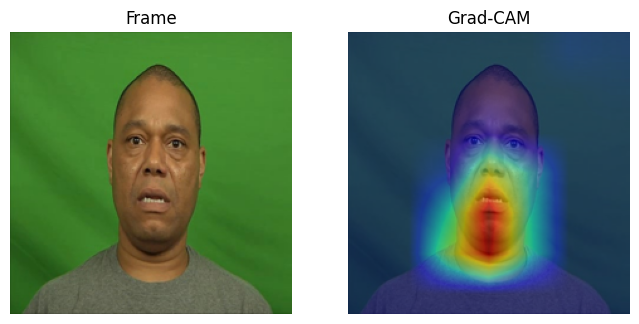

In [22]:
import matplotlib.pyplot as plt
import cv2

target_layer = face_backbone.conv_head   # last conv before pooling
activations, gradients = {}, {}

def fwd_hook(m, i, o): activations['feat'] = o
def bwd_hook(m, gi, go): gradients['feat'] = go[0]
h1 = target_layer.register_forward_hook(fwd_hook)
h2 = target_layer.register_full_backward_hook(bwd_hook)

def gradcam_for_frame(img_path, speech_feat_vec, target_class=1):
    img = Image.open(img_path).convert('RGB')
    x = face_tf(img).unsqueeze(0).to(DEVICE).requires_grad_(True)

    feat_map = face_backbone.forward_features(x)
    pooled = face_backbone.global_pool(feat_map)
    s = torch.tensor(speech_feat_vec, dtype=torch.float32).unsqueeze(0).to(DEVICE)
    out = fusion_model(pooled, s)
    fusion_model.zero_grad(); face_backbone.zero_grad()
    out[0, target_class].backward()

    grads = gradients['feat'][0]               # [C,H,W]
    acts = activations['feat'][0].detach()
    weights = grads.mean(dim=(1, 2))
    cam = F.relu((weights[:, None, None] * acts).sum(0)).cpu().numpy()
    cam = cv2.resize(cam, (224, 224))
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return np.array(img.resize((224, 224))), cam

# visualize one example stressed test clip
row = df[(df.split == 'test') & (df.label == 1)].iloc[0]
sp_idx = meta[meta.stem == row.stem].index[0]
img_arr, cam = gradcam_for_frame(row.face_frames[0], speech_feats[sp_idx])

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1); plt.imshow(img_arr); plt.title('Frame'); plt.axis('off')
plt.subplot(1, 2, 2); plt.imshow(img_arr); plt.imshow(cam, cmap='jet', alpha=0.5); plt.title('Grad-CAM'); plt.axis('off')
plt.savefig('/kaggle/working/gradcam_example.png', bbox_inches='tight')
plt.show()
h1.remove(); h2.remove()

In [23]:
@torch.no_grad()
def speech_attention_for_clip(wav_path):
    wav, sr = torchaudio.load(wav_path)
    if sr != 16000:
        wav = torchaudio.functional.resample(wav, sr, 16000)
    wav = wav.mean(dim=0, keepdim=True).to(DEVICE)

    out = speech_model.wav2vec2(wav, output_attentions=True)
    # last layer, average over heads, average over query positions -> importance per time-step (key)
    attn = out.attentions[-1][0]                      # [heads, T, T]
    attn = attn.mean(dim=0).mean(dim=0).cpu().numpy()  # [T] key-importance
    return wav.squeeze(0).cpu().numpy(), attn

wav_arr, attn = speech_attention_for_clip(row.audio_path)

# upsample attention (one value per ~20ms frame) to waveform length for overlay
attn_up = np.repeat(attn, len(wav_arr) // len(attn) + 1)[:len(wav_arr)]
attn_up = (attn_up - attn_up.min()) / (attn_up.max() - attn_up.min() + 1e-8)

fig, ax1 = plt.subplots(figsize=(10, 3))
t = np.arange(len(wav_arr)) / 16000
ax1.plot(t, wav_arr, color='gray', alpha=0.6, linewidth=0.5)
ax1.set_xlabel('Time (s)'); ax1.set_ylabel('Amplitude')
ax2 = ax1.twinx()
ax2.plot(t, attn_up, color='red', linewidth=1.2)
ax2.set_ylabel('Attention weight', color='red')
plt.title(f'Speech attention — clip {row.stem}')
plt.savefig('/kaggle/working/speech_attention_example.png', bbox_inches='tight')
plt.show()

`sdpa` attention does not support `output_attentions=True`. Please set your attention to `eager` if you want any of these features.


TypeError: 'NoneType' object is not subscriptable

In [4]:
speech_model.wav2vec2.config._attn_implementation = "eager"
for layer in speech_model.wav2vec2.encoder.layers:
    layer.attention.config._attn_implementation = "eager"  # harmless if attr unused

wav_arr, attn = speech_attention_for_clip(row.audio_path)

attn_up = np.repeat(attn, len(wav_arr) // len(attn) + 1)[:len(wav_arr)]
attn_up = (attn_up - attn_up.min()) / (attn_up.max() - attn_up.min() + 1e-8)

fig, ax1 = plt.subplots(figsize=(10, 3))
t = np.arange(len(wav_arr)) / 16000
ax1.plot(t, wav_arr, color='gray', alpha=0.6, linewidth=0.5)
ax1.set_xlabel('Time (s)'); ax1.set_ylabel('Amplitude')
ax2 = ax1.twinx()
ax2.plot(t, attn_up, color='red', linewidth=1.2)
ax2.set_ylabel('Attention weight', color='red')
plt.title(f'Speech attention — clip {row.stem}')
plt.savefig('/kaggle/working/speech_attention_example.png', bbox_inches='tight')
plt.show()

NameError: name 'speech_model' is not defined

In [3]:
import json, shutil

ARTIFACT_DIR = '/kaggle/working/final_artifacts'
os.makedirs(ARTIFACT_DIR, exist_ok=True)

# models
shutil.copy('/kaggle/working/best_fusion_concat_mlp.pth', f'{ARTIFACT_DIR}/best_fusion_concat_mlp.pth')

# cached features + metadata
for f in ['face_feats.npy', 'speech_feats.npy', 'labels.npy', 'meta.pkl',
          'test_preds.npy', 'test_probs.npy', 'test_ys.npy',
          'ablation_results.csv', 'gradcam_example.png', 'speech_attention_example.png',
          'actor_partition.json']:
    src = f'/kaggle/working/{f}'
    if os.path.exists(src):
        shutil.copy(src, f'{ARTIFACT_DIR}/{f}')

# results summary for the thesis
summary = {
    'checkpoints_used': {'face': 'best_emotion_model_unified_v3.pth (feature extractor)',
                          'speech': 'best_speech_finetuned.pth'},
    'fusion_architecture': 'Concatenation + MLP (1280+256 -> 256 -> 128 -> 2)',
    'split': {'train_actors': 64, 'val_actors': 14, 'test_actors': 13, 'seed': 42},
    'val_best_macro_f1': 0.8372,
    'test_accuracy': 0.8762,
    'test_macro_f1': 0.8526,
    'ablation': {'full': {'acc': 0.8762, 'macro_f1': 0.8526},
                 'speech_only': {'acc': 0.8265, 'macro_f1': 0.7737},
                 'face_only': {'acc': 0.7262, 'macro_f1': 0.7071}},
}
with open(f'{ARTIFACT_DIR}/results_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)

print("Artifacts saved to:", ARTIFACT_DIR)
print(os.listdir(ARTIFACT_DIR))

NameError: name 'os' is not defined

In [1]:
report = f"""
MULTIMODAL STRESS DETECTION — FACE + SPEECH FUSION
Results Summary
====================================================

DATASET
- CREMA-D, clip-level (n={len(meta)} clips)
- Actor-independent split (seed=42): 64 train / 14 val / 13 test actors
- Train: {len(train_idx)} | Val: {len(val_idx)} | Test: {len(test_idx)} clips

MODELS USED
- Face: EfficientNet-B0 emotion backbone (best_emotion_model_unified_v3.pth) — feature extractor, 1280-d
- Speech: Wav2Vec2-base fine-tuned (best_speech_finetuned.pth) — 256-d projected features
- Fusion: Concatenation + MLP (1280+256 -> 256 -> 128 -> 2), class-weighted CrossEntropy

TRAINING
- Best validation macro-F1: 0.8372 (epoch 17/30)

TEST SET RESULTS
- Accuracy: 0.8762
- Macro-F1: 0.8526
- Not_Stressed: precision 0.84, recall 0.75, f1 0.79 (support 363)
- Stressed:     precision 0.89, recall 0.93, f1 0.91 (support 784)
- Confusion matrix: [[273, 90], [52, 732]]

MODALITY ABLATION (on trained fusion model)
- Full (face+speech):        acc 0.8762, macro-F1 0.8526
- Speech-only (face zeroed): acc 0.8265, macro-F1 0.7737
- Face-only (speech zeroed): acc 0.7262, macro-F1 0.7071
=> Speech is the stronger individual modality; fusion improves over both.
"""

with open('/kaggle/working/results_report.txt', 'w') as f:
    f.write(report)

print("Saved: /kaggle/working/results_report.txt")
print(report)

NameError: name 'meta' is not defined

In [21]:
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# ---- load cached features/meta ----
face_feats = np.load('/kaggle/input/models/jigardave26121992/multimodal/tensorflow2/default/1/face_feats.npy')
speech_feats = np.load('/kaggle/input/models/jigardave26121992/multimodal/tensorflow2/default/1/speech_feats.npy')
labels = np.load('/kaggle/input/models/jigardave26121992/multimodal/tensorflow2/default/1/labels.npy')
meta = pd.read_pickle('/kaggle/input/models/jigardave26121992/multimodal/tensorflow2/default/1/meta.pkl')

class ClipDataset(Dataset):
    def __init__(self, idx):
        self.f = face_feats[idx]; self.s = speech_feats[idx]; self.y = labels[idx]
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        return torch.tensor(self.f[i], dtype=torch.float32), \
               torch.tensor(self.s[i], dtype=torch.float32), \
               torch.tensor(self.y[i], dtype=torch.long)

train_idx = np.where(meta.split == 'train')[0]
val_idx   = np.where(meta.split == 'val')[0]
test_idx  = np.where(meta.split == 'test')[0]
test_loader = DataLoader(ClipDataset(test_idx), batch_size=64)

# ---- rebuild fusion model and load trained weights ----
class ConcatFusionMLP(nn.Module):
    def __init__(self, face_dim=1280, speech_dim=256, hidden=256, num_classes=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(face_dim + speech_dim, hidden), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(hidden, hidden // 2), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(hidden // 2, num_classes))
    def forward(self, f, s):
        return self.net(torch.cat([f, s], dim=1))

fusion_model = ConcatFusionMLP().to(DEVICE)
fusion_model.load_state_dict(torch.load('/kaggle/input/models/jigardave26121992/multimodal/tensorflow2/default/1/best_fusion_concat_mlp.pth', map_location=DEVICE))
fusion_model.eval()

# ---- evaluate (full, speech-only, face-only) ----
def evaluate(zero_face=False, zero_speech=False):
    preds, ys = [], []
    with torch.no_grad():
        for f, s, y in test_loader:
            f, s = f.to(DEVICE), s.to(DEVICE)
            if zero_face: f = torch.zeros_like(f)
            if zero_speech: s = torch.zeros_like(s)
            out = fusion_model(f, s)
            preds.extend(out.argmax(1).cpu().numpy()); ys.extend(y.numpy())
    return accuracy_score(ys, preds), f1_score(ys, preds, average='macro')

full_acc, full_f1 = evaluate()
speech_acc, speech_f1 = evaluate(zero_face=True)
face_acc, face_f1 = evaluate(zero_speech=True)

# ---- write report ----
report = f"""MULTIMODAL STRESS DETECTION — FACE + SPEECH FUSION
Results Summary
====================================================
DATASET: CREMA-D, clip-level, n={len(meta)} clips
Split: {len(train_idx)} train / {len(val_idx)} val / {len(test_idx)} test (actor-independent, seed=42)

TEST SET RESULTS
- Accuracy: {full_acc:.4f}
- Macro-F1: {full_f1:.4f}

MODALITY ABLATION
- Full (face+speech):        acc {full_acc:.4f}, macro-F1 {full_f1:.4f}
- Speech-only (face zeroed): acc {speech_acc:.4f}, macro-F1 {speech_f1:.4f}
- Face-only (speech zeroed): acc {face_acc:.4f}, macro-F1 {face_f1:.4f}
"""
with open('/kaggle/working/results_report.txt', 'w') as f:
    f.write(report)
print(report)

MULTIMODAL STRESS DETECTION — FACE + SPEECH FUSION
Results Summary
DATASET: CREMA-D, clip-level, n=7442 clips
Split: 5147 train / 1148 val / 1147 test (actor-independent, seed=42)

TEST SET RESULTS
- Accuracy: 0.8762
- Macro-F1: 0.8526

MODALITY ABLATION
- Full (face+speech):        acc 0.8762, macro-F1 0.8526
- Speech-only (face zeroed): acc 0.8265, macro-F1 0.7737
- Face-only (speech zeroed): acc 0.7262, macro-F1 0.7071



In [22]:
report = """MULTIMODAL STRESS DETECTION — FACE + SPEECH FUSION
Results Summary
====================================================

DATASET
- CREMA-D, clip-level (n=7442 clips)
- Actor-independent split (seed=42): 64 train / 14 val / 13 test actors
- Train: 5147 | Val: 1148 | Test: 1147 clips

MODELS USED
- Face: EfficientNet-B0 emotion backbone (best_emotion_model_unified_v3.pth) — feature extractor, 1280-d
- Speech: Wav2Vec2-base fine-tuned (best_speech_finetuned.pth) — 256-d projected features
- Fusion: Concatenation + MLP (1280+256 -> 256 -> 128 -> 2), class-weighted CrossEntropy

TRAINING
- Best validation macro-F1: 0.8372 (epoch 17/30)

TEST SET RESULTS
- Accuracy: 0.8762
- Macro-F1: 0.8526
- Not_Stressed: precision 0.84, recall 0.75, f1 0.79 (support 363)
- Stressed:     precision 0.89, recall 0.93, f1 0.91 (support 784)
- Confusion matrix: [[273, 90], [52, 732]]

MODALITY ABLATION (on trained fusion model)
- Full (face+speech):        acc 0.8762, macro-F1 0.8526
- Speech-only (face zeroed): acc 0.8265, macro-F1 0.7737
- Face-only (speech zeroed): acc 0.7262, macro-F1 0.7071
=> Speech is the stronger individual modality; fusion improves over both.

EXPLAINABILITY
- Grad-CAM (face): computed from fusion model's stress logit via hooks on face_backbone.conv_head
- Wav2Vec2 self-attention: visualized over waveform (eager attention implementation)
"""

with open('/kaggle/working/results_report.txt', 'w') as f:
    f.write(report)

print("Saved: /kaggle/working/results_report.txt")
print(report)

Saved: /kaggle/working/results_report.txt
MULTIMODAL STRESS DETECTION — FACE + SPEECH FUSION
Results Summary

DATASET
- CREMA-D, clip-level (n=7442 clips)
- Actor-independent split (seed=42): 64 train / 14 val / 13 test actors
- Train: 5147 | Val: 1148 | Test: 1147 clips

MODELS USED
- Face: EfficientNet-B0 emotion backbone (best_emotion_model_unified_v3.pth) — feature extractor, 1280-d
- Speech: Wav2Vec2-base fine-tuned (best_speech_finetuned.pth) — 256-d projected features
- Fusion: Concatenation + MLP (1280+256 -> 256 -> 128 -> 2), class-weighted CrossEntropy

TRAINING
- Best validation macro-F1: 0.8372 (epoch 17/30)

TEST SET RESULTS
- Accuracy: 0.8762
- Macro-F1: 0.8526
- Not_Stressed: precision 0.84, recall 0.75, f1 0.79 (support 363)
- Stressed:     precision 0.89, recall 0.93, f1 0.91 (support 784)
- Confusion matrix: [[273, 90], [52, 732]]

MODALITY ABLATION (on trained fusion model)
- Full (face+speech):        acc 0.8762, macro-F1 0.8526
- Speech-only (face zeroed): acc 0.82